# Exploratory Data Analysis

This notebook explores the ACDC dataset before preprocessing. It previews the data, checks its structure and quality, and summarizes numerical, categorical, and Boolean variables.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import sqlite3
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil
from itertools import product

# for better resolution plots
%config InlineBackend.figure_format = 'retina'

## Load and preview the data

Load the semicolon-separated CSV file and display the first 10 records across all columns to get an initial view of the data.

In [2]:
acdc = pd.read_csv('../data/acdc_dataset.csv', sep = ';')
pd.set_option("display.max_columns", None)
acdc.head(10)
# categorical columns have multiple names for the same category, 
# numerical columns are not in the correct range (some are negative where they should not be) 
# uses_print is 0/1 and not T/F)
# date columns are also not in the correct range with end values being 1970 or the end date being smaller than the start date

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.0,0.0,18.0,False,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,2023-11-24,37,2,0.32,10.68,1,0.0,0.0,0.0,False,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,2023-07-22,163,19,0.17,26.09,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,2023-12-17,15,4,0.38,17.39,3,0.0,0.0,0.0,False,False,False,0,False,False,True,False,False,0,335.74
5,CW000006,39.0,Male,Health,Portugal,False,0,flex,3,2021-05-31,2021-08-01,2021-07-09,23,3,0.36,26.09,3,0.0,0.0,0.0,False,False,False,1,True,False,False,False,False,0,413.17
6,CW000007,23.0,Female,Unknown,Portugal,True,2,hot_desk,2,2022-01-17,2022-03-19,2022-01-31,47,5,0.62,17.39,5,0.0,0.0,1.0,False,False,True,0,False,False,False,False,False,0,257.95
7,CW000008,33.0,Male,Information Technology,Portugal,True,3,flex,3,2021-03-28,2022-06-30,2022-06-14,16,155,2.36,26.09,25,129.0,0.0,0.0,True,False,False,0,False,False,False,True,False,0,4636.8
8,CW000009,30.0,Male,Other,Portugal,False,0,flex,3,2023-08-12,2023-09-21,2023-08-12,40,6,1.10,17.13,6,0.0,1.0,0.0,False,True,False,0,False,False,False,False,False,0,281.37
9,CW000010,44.0,Male,Consulting,Portugal,False,0,dedicated_desk,5,2022-06-06,1970-01-01,2023-12-30,2,331,4.04,43.48,36,42.1,0.0,37.0,True,False,True,1,True,True,False,True,False,1,8741.88


## Dataset structure

Check the number of rows and columns, review the column names, and inspect inferred data types. This helps distinguish numeric, categorical, date-like, and Boolean fields.

In [3]:
acdc.shape

(15465, 31)

In [4]:
list(acdc.columns)

['member_id',
 'age',
 'gender',
 'industry',
 'country',
 'is_team_account',
 'n_colleagues_on_account',
 'plan_tier',
 'plan_days_per_week',
 'membership_start',
 'membership_end',
 'last_badge_swipe',
 'days_since_last_visit',
 'total_visits',
 'avg_weekly_visits',
 'entitled_visits_last_period',
 'actual_visits_last_period',
 'meeting_room_hours',
 'event_space_hours',
 'guest_passes_issued',
 'uses_meeting_rooms',
 'uses_event_space',
 'uses_guest_passes',
 'uses_print',
 'uses_mail_handling',
 'uses_phone_booths',
 'uses_day_passes',
 'uses_storage',
 'uses_bike_locker',
 'n_renewals',
 'lifetime_value']

In [5]:
acdc.dtypes

member_id                       object
age                            float64
gender                          object
industry                        object
country                         object
is_team_account                   bool
n_colleagues_on_account          int64
plan_tier                       object
plan_days_per_week               int64
membership_start                object
membership_end                  object
last_badge_swipe                object
days_since_last_visit            int64
total_visits                     int64
avg_weekly_visits              float64
entitled_visits_last_period    float64
actual_visits_last_period        int64
meeting_room_hours             float64
event_space_hours              float64
guest_passes_issued            float64
uses_meeting_rooms                bool
uses_event_space                  bool
uses_guest_passes                 bool
uses_print                       int64
uses_mail_handling                bool
uses_phone_booths        

## Missing values

Calculate the percentage of missing values in each column and show only columns that contain missing data.

In [6]:
column_percentage = acdc.isna().mean() * 100
column_percentage = column_percentage[column_percentage > 0]
column_percentage

age                    3.608147
gender                 3.427093
country                2.780472
plan_tier              0.678952
meeting_room_hours     8.393146
guest_passes_issued    8.218558
lifetime_value         6.724863
dtype: float64

## Duplicate records

Count exact duplicate rows and repeated member IDs, then inspect records with duplicated IDs to see whether they are identical or differ in their other fields.

In [7]:
print("Duplicated rows:", acdc.duplicated().sum())
print("Duplicated member IDs:", acdc["member_id"].duplicated().sum())

Duplicated rows: 15
Duplicated member IDs: 15


In [8]:
dup_ids = acdc.loc[acdc["member_id"].duplicated(keep=False)].sort_values("member_id")
dup_ids.head(30)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
959,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,2023-03-07,2023-01-21,45,18,1.56,26.09,11,1.7,0.0,1.0,True,False,True,0,False,False,False,False,False,0,505.28
15453,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,2023-03-07,2023-01-21,45,18,1.56,26.09,11,1.7,0.0,1.0,True,False,True,0,False,False,False,False,False,0,505.28
15454,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,18/12/2022,17/11/2022,31,4,0.61,14.63,5,NaN,0.0,NaN,False,False,True,0,False,False,False,False,False,0,231.86
1428,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,18/12/2022,17/11/2022,31,4,0.61,14.63,5,NaN,0.0,NaN,False,False,True,0,False,False,False,False,False,0,231.86
15462,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,1970-01-01,2023-12-27,5,1,0.21,1.31,0,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,18.14
3985,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,1970-01-01,2023-12-27,5,1,0.21,1.31,0,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,18.14
15461,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,2023-09-26,19,74,0.58,60.87,4,0.0,0.0,0.0,False,False,False,0,True,True,False,True,False,0,20683.24
5441,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,2023-09-26,19,74,0.58,60.87,4,0.0,0.0,0.0,False,False,False,0,True,True,False,True,False,0,20683.24
6011,CW005845,35.0,Female,FINANCE,Portugal,True,3,dedicated_desk,5,2021-10-05,1970-01-01,2023-01-26,340,24,0.20,43.48,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,4,9403.99
15456,CW005845,35.0,Female,FINANCE,Portugal,True,3,dedicated_desk,5,2021-10-05,1970-01-01,2023-01-26,340,24,0.20,43.48,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,4,9403.99


## Variable distributions

Check and convert the lifetime values so they can be included in numeric summaries. Then inspect numeric statistics, raw category frequencies, and Boolean summaries. The category counts retain the original spellings so inconsistent labels remain visible.

In [9]:
# Numeric summary (50% is the median)
numeric = acdc.select_dtypes(include="number").drop(columns="uses_print", errors="ignore")
numeric["lifetime_value"] = pd.to_numeric(
    acdc["lifetime_value"].astype("string").str.replace(r"[€,]", "", regex=True),
    errors="coerce",
)
display(numeric.describe(include=["float", "integer"]).T)

# Category counts, shown separately
display(acdc["gender"].value_counts(dropna=False))
display(acdc["industry"].value_counts(dropna=False))
display(acdc["country"].value_counts(dropna=False))
display(acdc["plan_tier"].value_counts(dropna=False))

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.0,34.0,40.0,149.0
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.0,0.0,1.0,9.0
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.0,3.0,5.0,9.0
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.0,13.0,55.0,1212.0
total_visits,15465.0,110.406531,182.93934,-112.0,8.0,34.0,132.0,6530.0
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.4
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.80097,11.387207,0.0,5.0,10.0,20.0,60.0
meeting_room_hours,14167.0,33.07557,428.169678,-56.6,0.0,0.0,7.2,41220.0
event_space_hours,15465.0,5.11722,26.013097,-13.5,0.0,0.0,0.0,602.8


gender
Female     7414
Male       6172
NaN         530
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64

industry
Information Technology    3322
Consulting                1896
Marketing & PR            1835
Design & Creative         1822
Finance                   1134
Other                     1100
Legal                      809
Education                  727
Unknown                    640
Health                     571
Real Estate                528
CONSULTING                  86
consulting                  76
INFORMATION TECHNOLOGY      54
IT                          53
information technology      49
FINANCE                     48
design & creative           44
Information technology      41
DESIGN & CREATIVE           40
Tech                        40
OTHER                       39
finance                     38
LEGAL                       38
other                       36
Design/Creative             35
Design and Creative         34
legal                       33
MARKETING & PR              32
UNKNOWN                     29
unknown                     27
marketing & pr              25

country
Portugal           9959
United Kingdom     1105
Germany             852
Spain               712
France              506
Netherlands         464
NaN                 430
Other (Europe)      429
Ireland             232
portugal            155
Portucal            142
PT                  130
portugal            122
germany              24
other (europe)       22
france               18
united kingdom       16
DE                   14
UK                   14
NL                   13
Deutschland          13
GB                   12
Espana               10
U.K.                 10
FR                    9
United kingdom        9
ES                    8
España                7
IE                    6
ireland               6
spain                 5
netherlands           4
The Netherlands       4
Holland               3
Name: count, dtype: int64

plan_tier
flex              5182
hot_desk          4974
full_time         2323
dedicated_desk    1481
private_office     630
Flex               138
FLEX               133
NaN                105
HOT_DESK            82
Hot Desk            80
hotdesk             79
fulltime            64
FULL_TIME           49
Full Time           39
DEDICATED_DESK      27
Dedicated Desk      25
dedicateddesk       19
Private Office      13
privateoffice       12
PRIVATE_OFFICE      10
Name: count, dtype: int64

In [10]:
# cat_cols = ["gender", "industry", "country", "plan_tier"]

# # Use a 2x2 grid instead of 4x1, with a manageable figure size
# fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# axes = axes.flatten()

# for i, col in enumerate(cat_cols):
#     ax = axes[i]
    
#     # Fill NaNs with a string placeholder so Matplotlib doesn't crash on floats
#     plot_data = acdc[col].fillna("Missing")
    
#     # Get value counts of the cleaned series
#     counts = plot_data.value_counts()
    
#     # Plot as a bar chart using seaborn
#     sns.countplot(
#         data=acdc.assign(**{col: plot_data}), 
#         x=col, 
#         order=counts.index, 
#         ax=ax, 
#         palette="viridis", 
#         hue=col, 
#         legend=False
#     )
    
#     ax.set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
#     ax.set_xlabel(col, fontsize=10)
#     ax.set_ylabel("Count", fontsize=10)
#     ax.tick_params(axis='x', rotation=45)

# # Hide any unused subplots (just in case)
# for ax in axes[len(cat_cols):]:
#     ax.axis("off")

# plt.suptitle("Categorical Variable Distributions (Raw Labels)", fontsize=16, y=1.02)
# plt.tight_layout()
# plt.show()

In [11]:
# Boolean summary, including uses_print converted from 0/1 to True/False
booleans = acdc.select_dtypes(include="bool").assign(
    uses_print=acdc["uses_print"].astype(bool)
)
display(booleans.describe(include="bool"))

,is_team_account,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,uses_print
count,15465,15465,15465,15465,15465,15465,15465,15465,15465,15465
unique,2,2,2,2,2,2,2,2,2,2
top,False,False,False,False,False,False,False,False,False,False
freq,11112,10202,13624,12651,11901,11469,12069,13169,15439,10469


Values containing €: 291


70     246.10 €
83     446.70 €
211    859.65 €
220    843.67 €
240    646.66 €
Name: lifetime_value, dtype: object

                             missing       min  median     mean         max   skew  kurtosis  pct_zero  n_negative
age                              557      1.00   34.00    34.86      149.00   3.03     28.90      0.00           0
n_colleagues_on_account            0     -1.00    0.00     0.54        9.00   2.12      4.83     69.18         565
plan_days_per_week                 0      0.00    3.00     3.39        9.00   0.93      0.27      0.28           0
days_since_last_visit              0   -956.00   13.00   117.19     1212.00   2.72      5.98      0.55          56
total_visits                       0   -112.00   34.00   110.39     6530.00   6.82    159.76      0.71          42
avg_weekly_visits                  0      0.00    1.42     1.78       47.40  10.27    190.12      0.09           0
entitled_visits_last_period        0      0.00   26.09    27.51       78.27   0.73      0.00      0.06           0
actual_visits_last_period          0      0.00   10.00    13.80       60.00   1.

C:\Users\miaka\AppData\Local\Temp\ipykernel_22152\3461743837.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  numeric_acdc["lifetime_value"] = pd.to_numeric(numeric_acdc["lifetime_value"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(), errors="coerce")


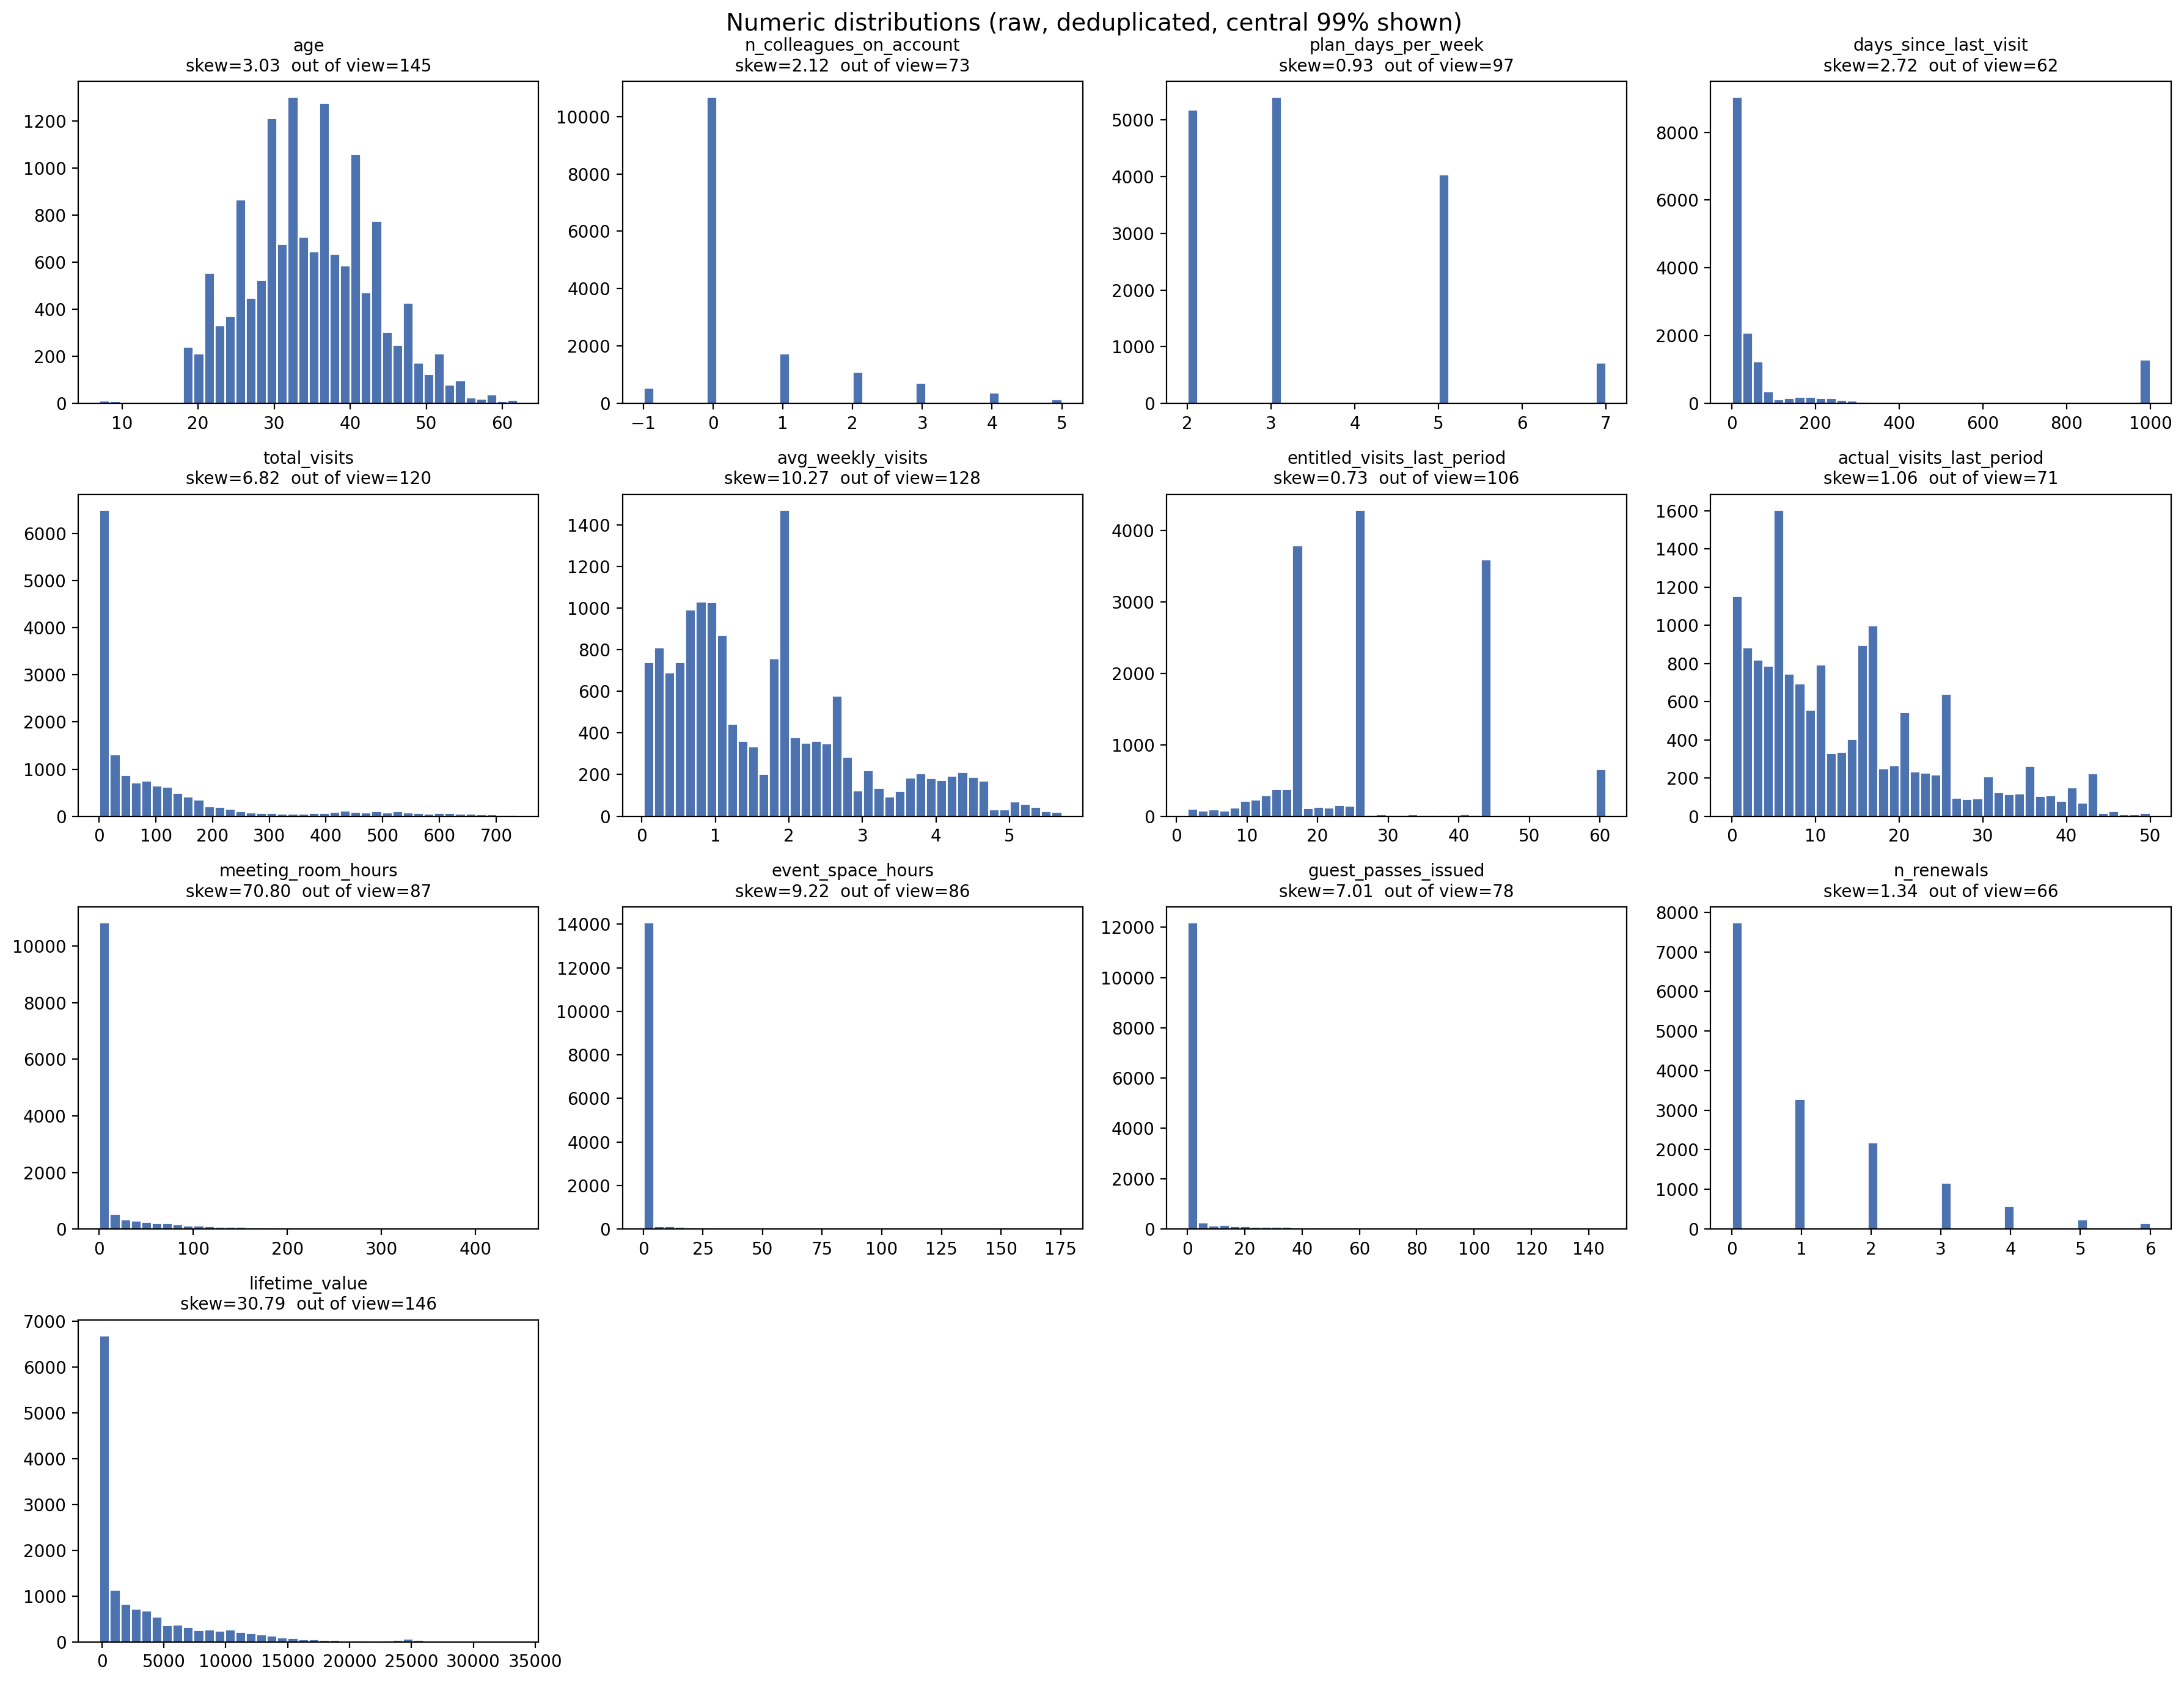

In [12]:
# Lifetime value is of type object, why? Because there are euro signs in some of the values. 
# Check how many values contain the euro sign and remove to look at distribution.
euro_values = acdc["lifetime_value"].astype("string").str.contains("€", na=False)
print(f"Values containing €: {euro_values.sum()}")
display(acdc.loc[euro_values, "lifetime_value"].head())

numeric_acdc = acdc.drop_duplicates()
numeric_acdc["lifetime_value"] = pd.to_numeric(numeric_acdc["lifetime_value"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(), errors="coerce")

num_cols = ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit",
            "total_visits", "avg_weekly_visits", "entitled_visits_last_period",
            "actual_visits_last_period", "meeting_room_hours", "event_space_hours",
            "guest_passes_issued", "n_renewals", "lifetime_value"]

stats = pd.DataFrame({
    "missing": numeric_acdc[num_cols].isna().sum(),
    "min": numeric_acdc[num_cols].min(),
    "median": numeric_acdc[num_cols].median(),
    "mean": numeric_acdc[num_cols].mean(),
    "max": numeric_acdc[num_cols].max(),
    "skew": numeric_acdc[num_cols].skew(),
    "kurtosis": numeric_acdc[num_cols].kurt(),
    "pct_zero": (numeric_acdc[num_cols] == 0).mean() * 100,
    "n_negative": (numeric_acdc[num_cols] < 0).sum(),
}).round(2)
print(stats.to_string())

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, num_cols):
    s = numeric_acdc[col].dropna()
    lo, hi = s.quantile([0.005, 0.995])
    s_clip = s[(s >= lo) & (s <= hi)]
    ax.hist(s_clip, bins=40, color="#4C72B0", edgecolor="white")
    ax.set_title(f"{col}\nskew={s.skew():.2f}  out of view={len(s) - len(s_clip)}", fontsize=10)
for ax in axes.flat[len(num_cols):]:
    ax.axis("off")
fig.suptitle("Numeric distributions (raw, deduplicated, central 99% shown)", fontsize=14)
fig.tight_layout()
#fig.savefig("numeric_distributions.png", dpi=110)

## Univariate Exploration
### Outlier Analysis

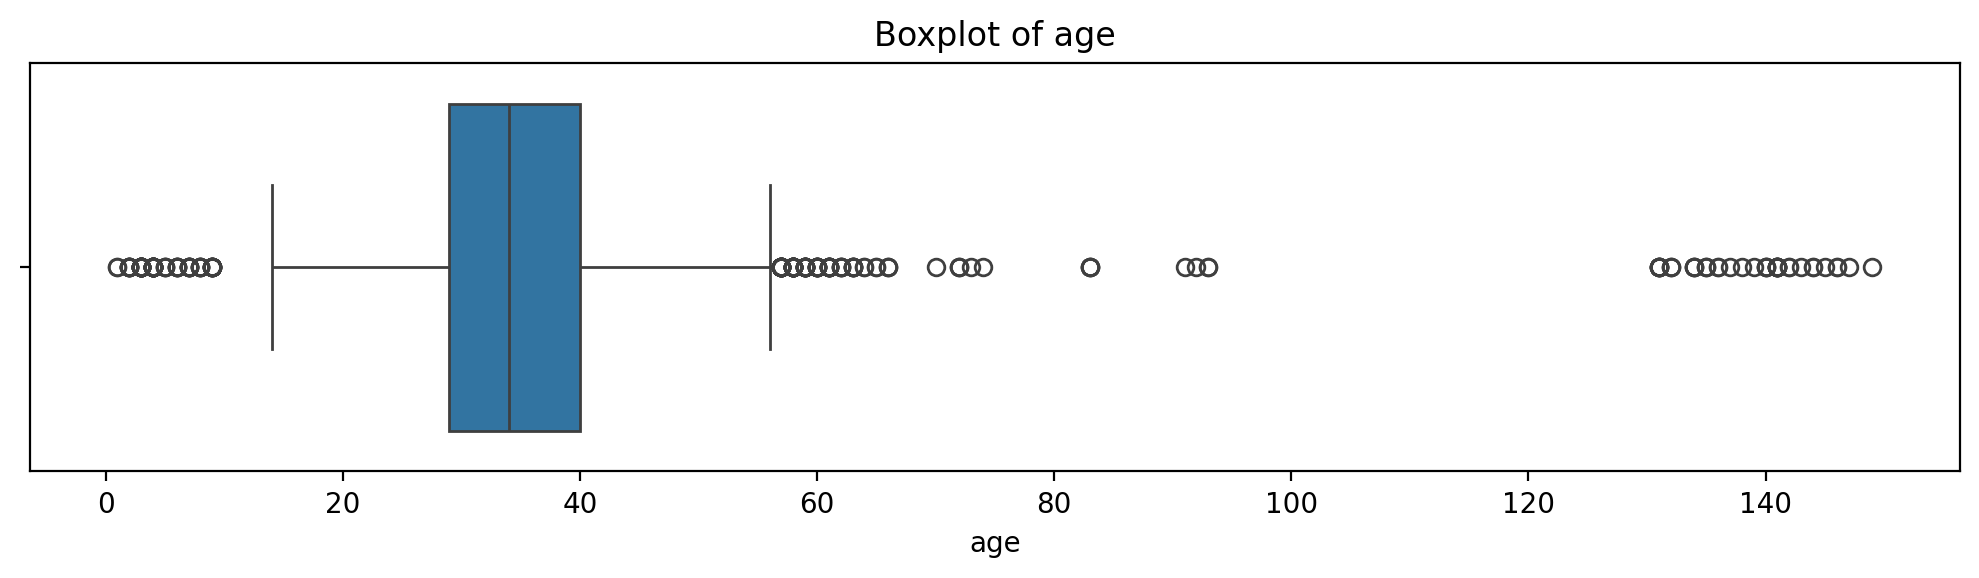

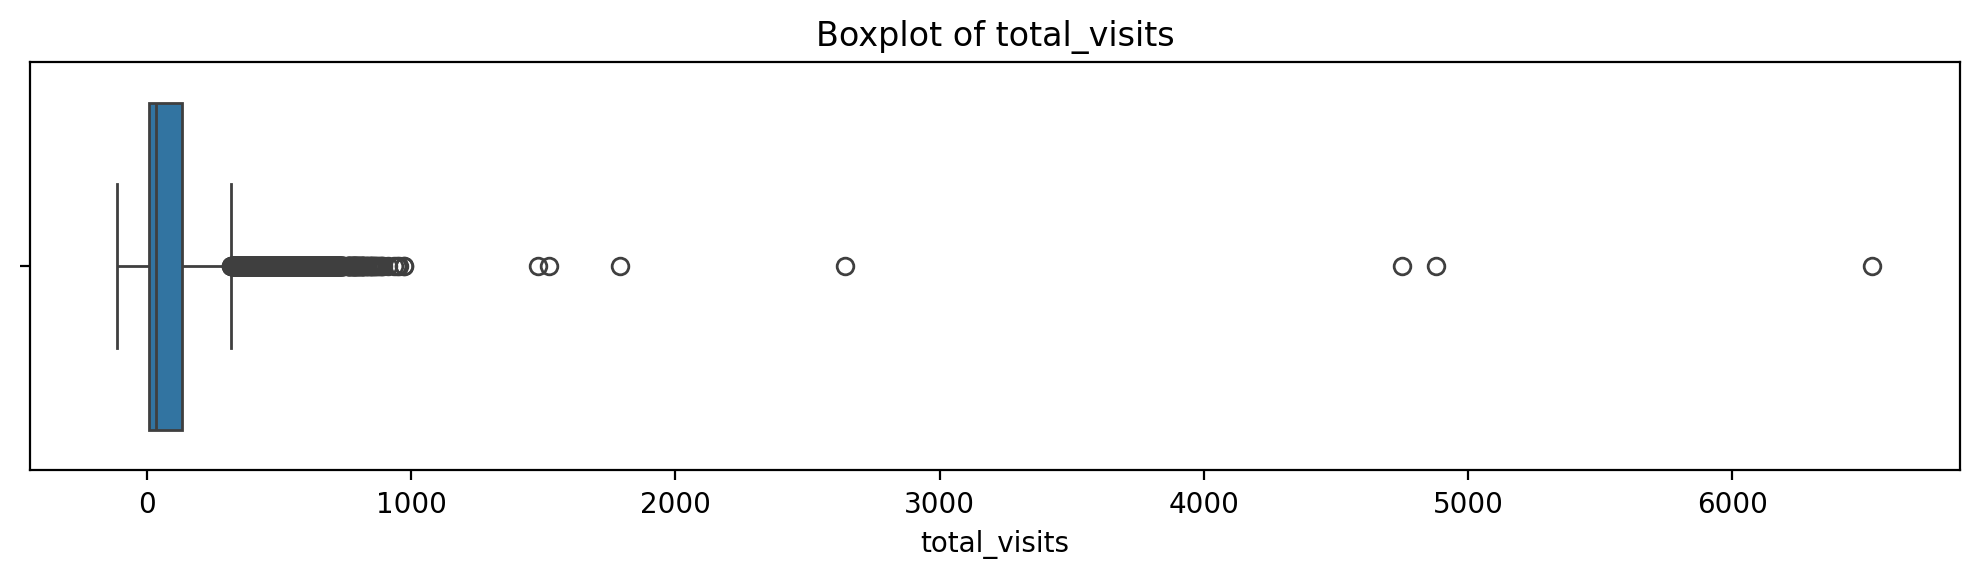

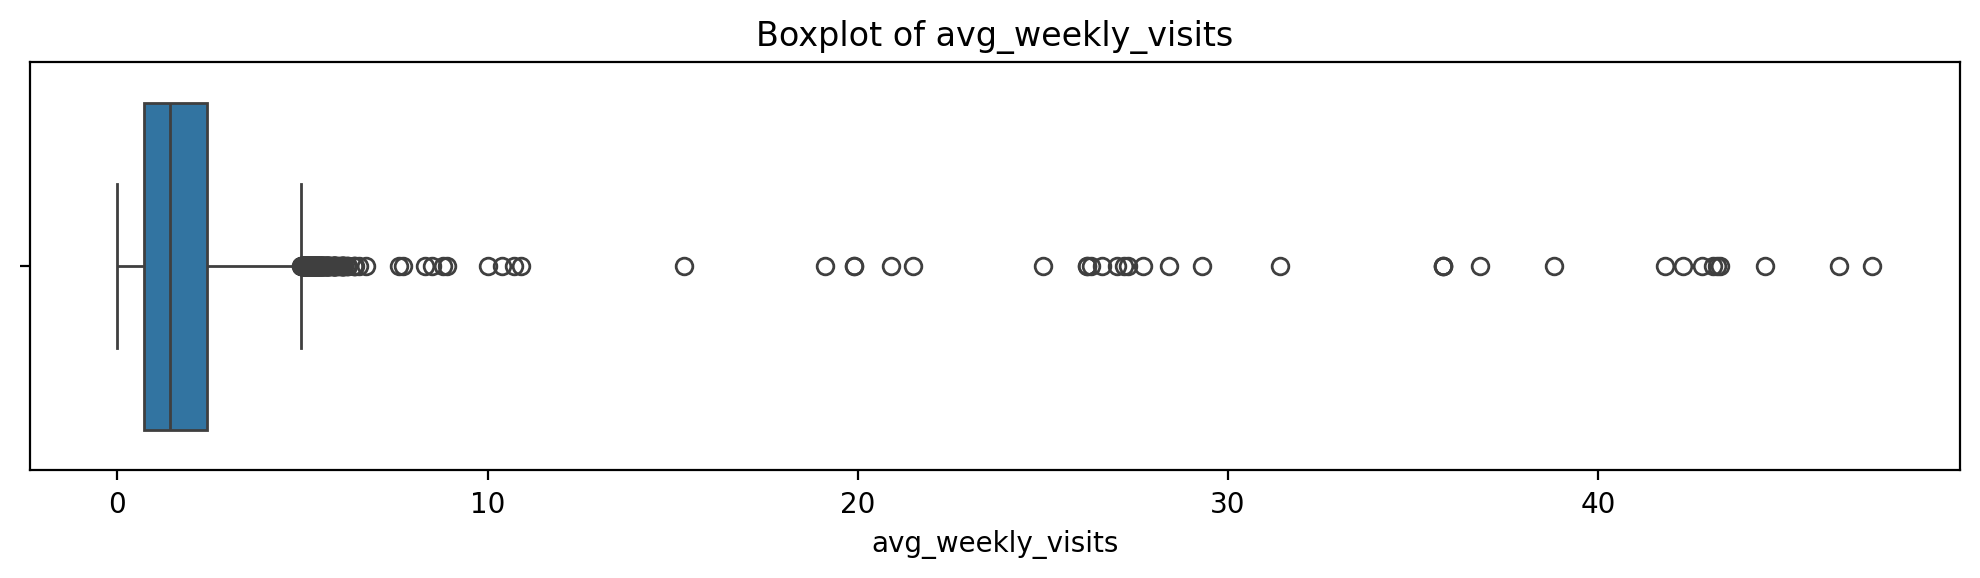

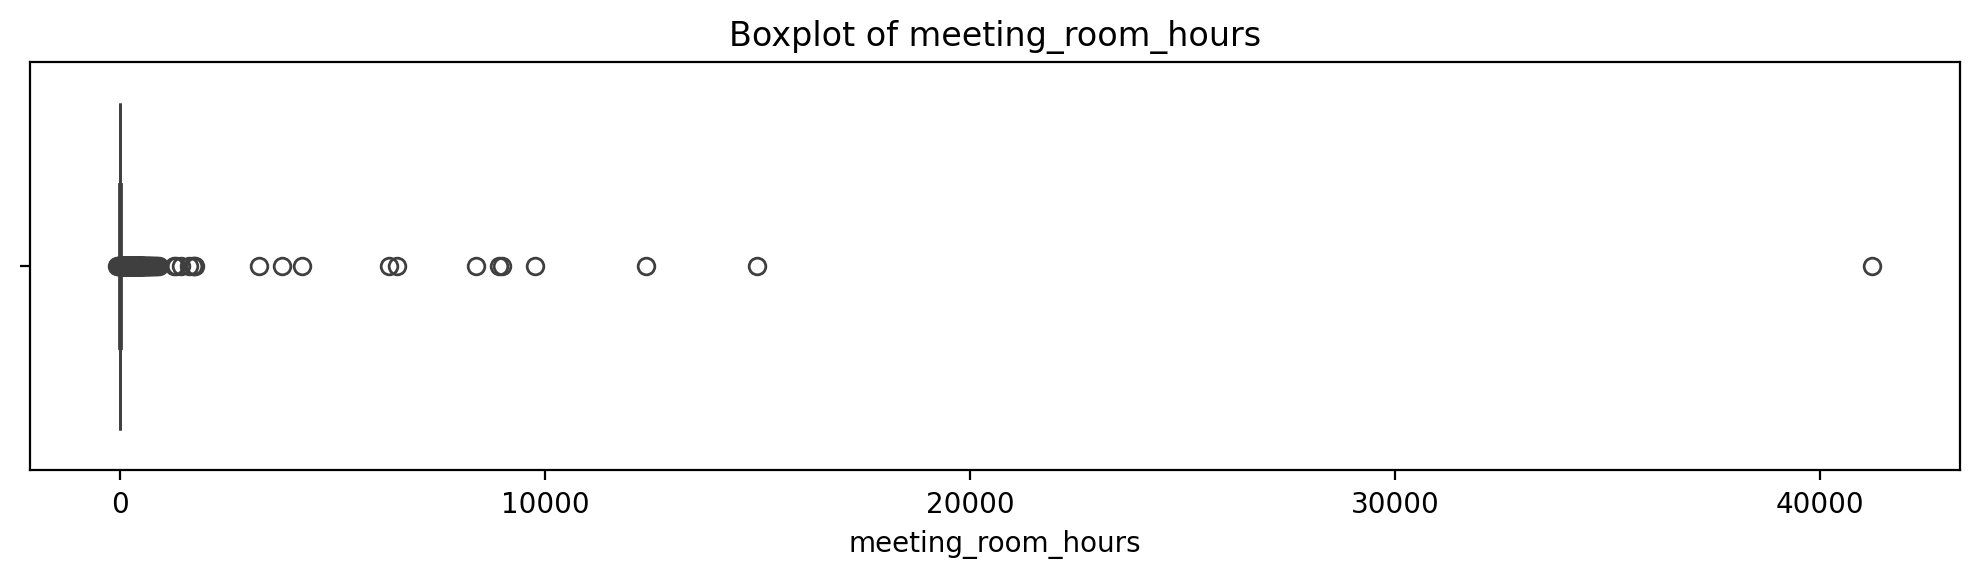

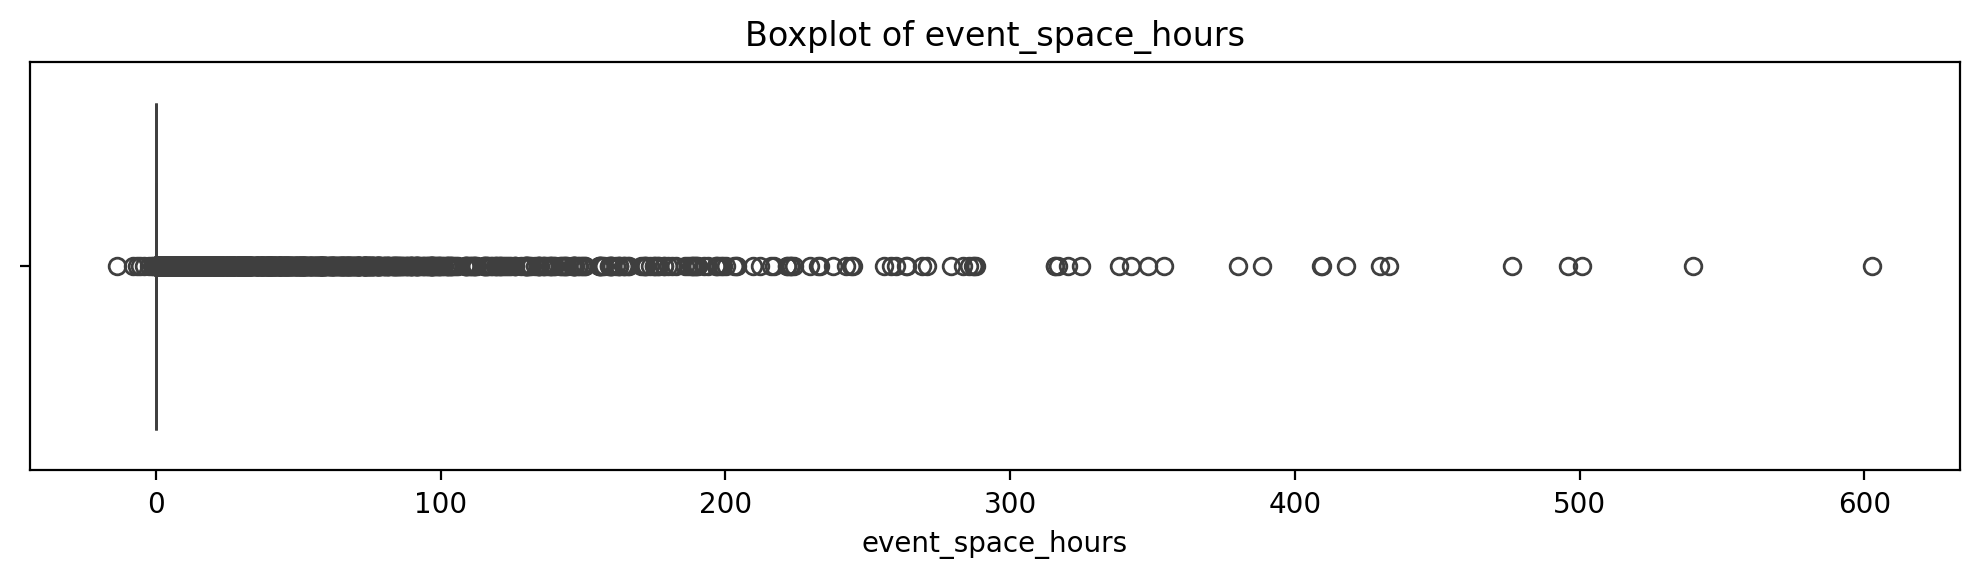

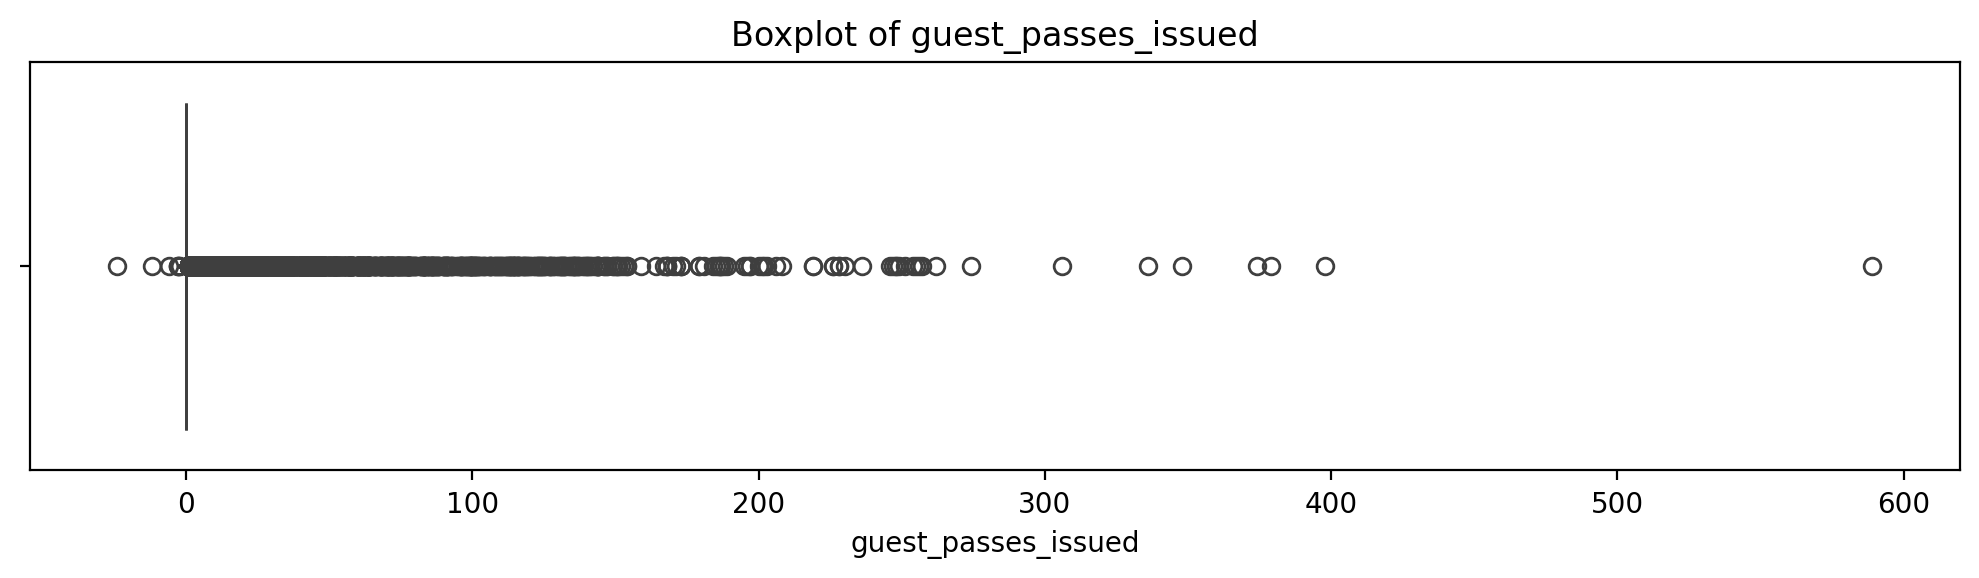

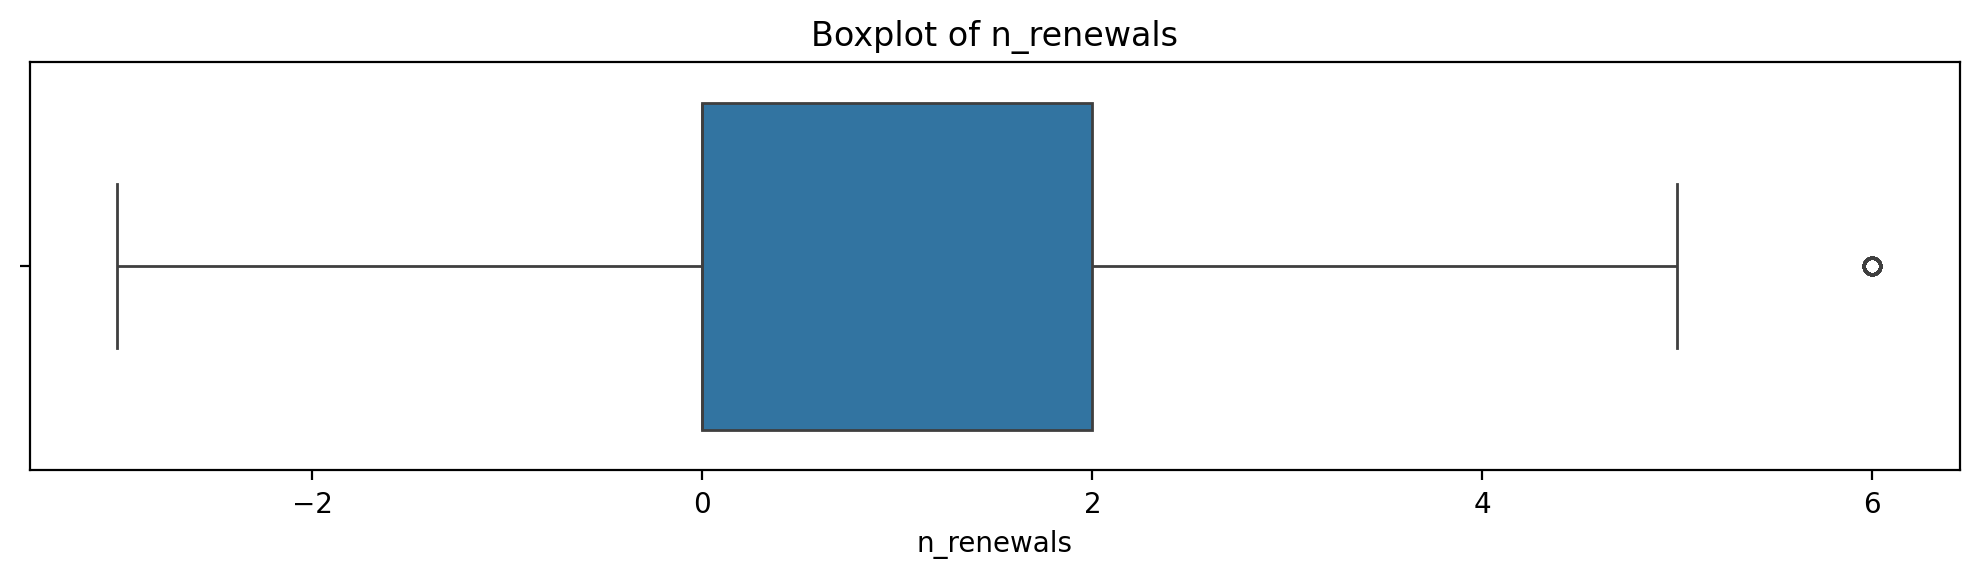

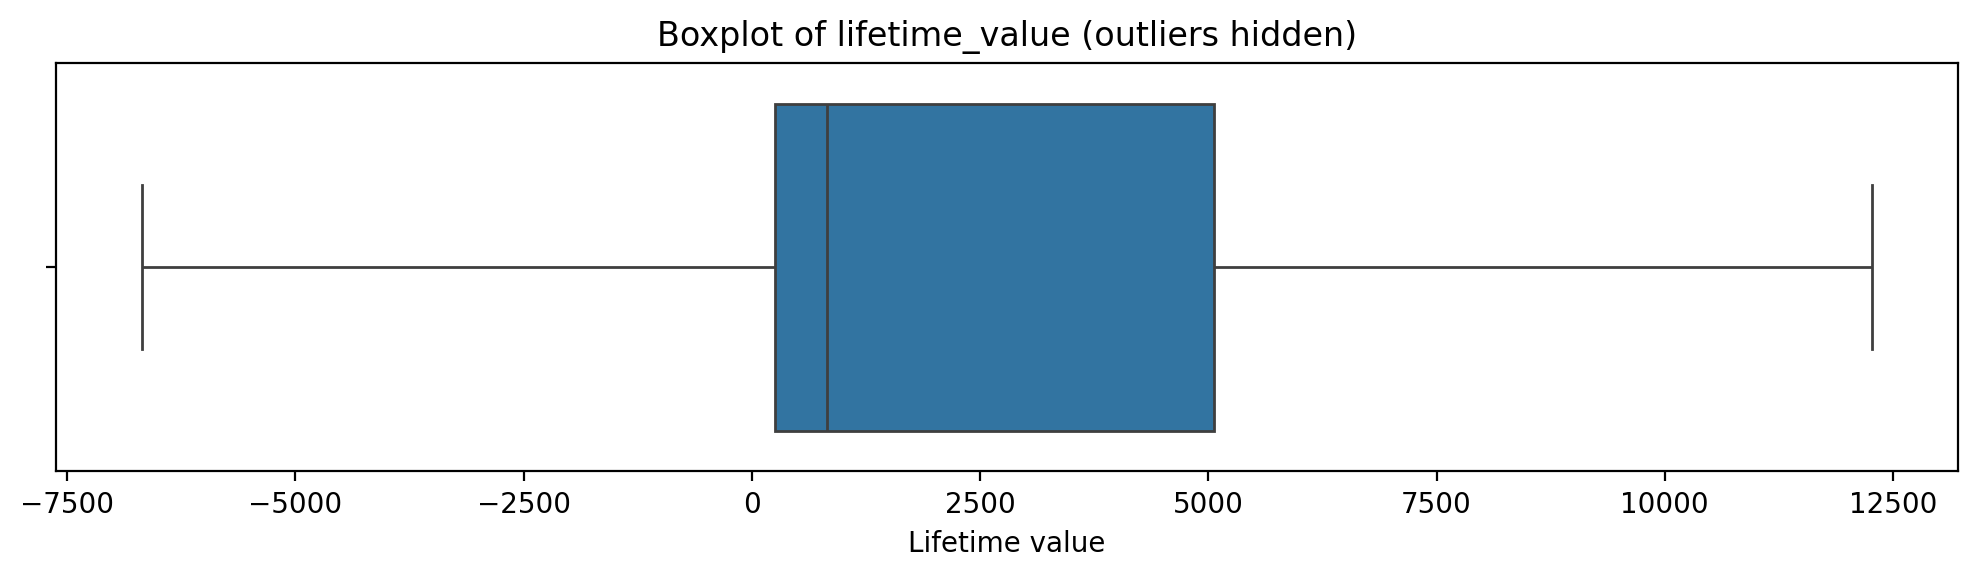

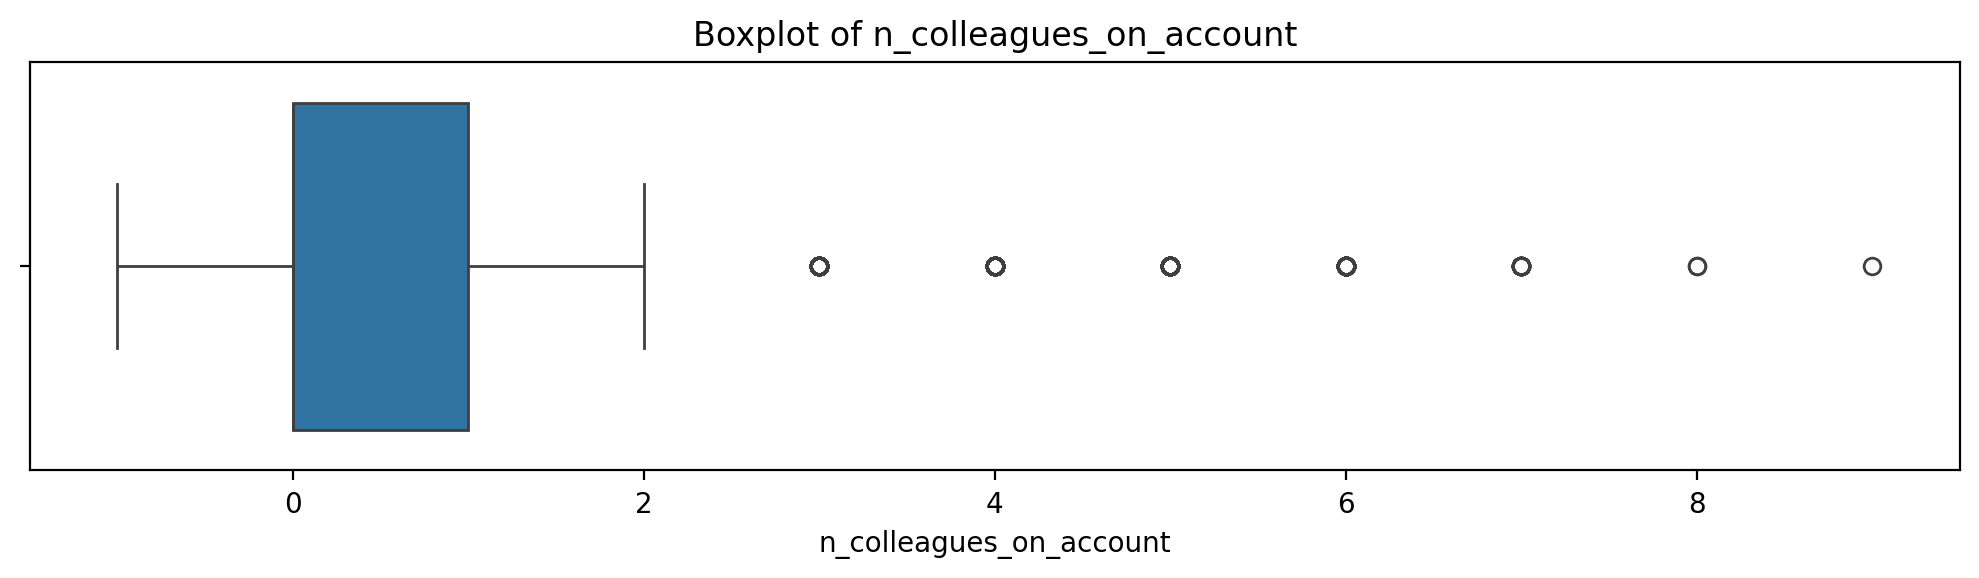

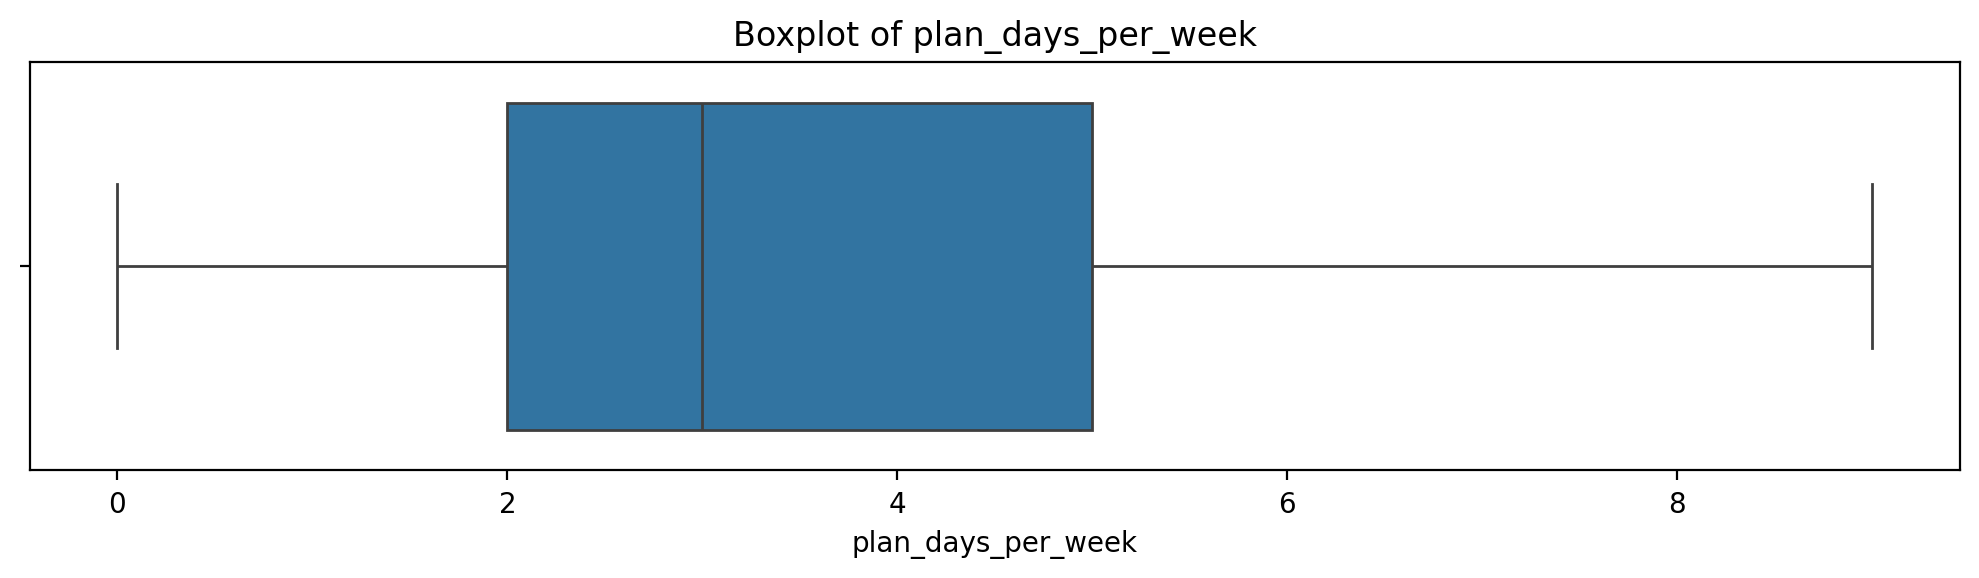

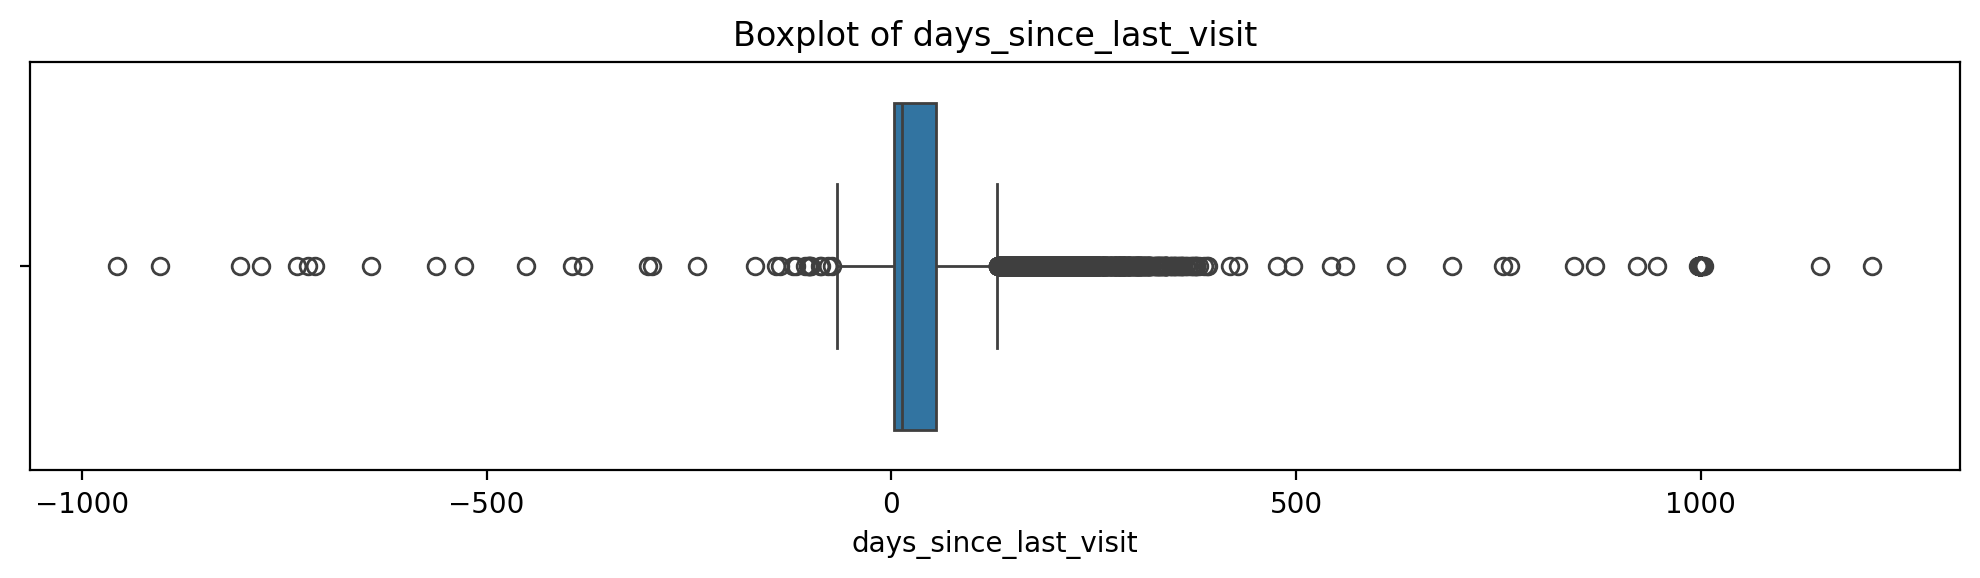

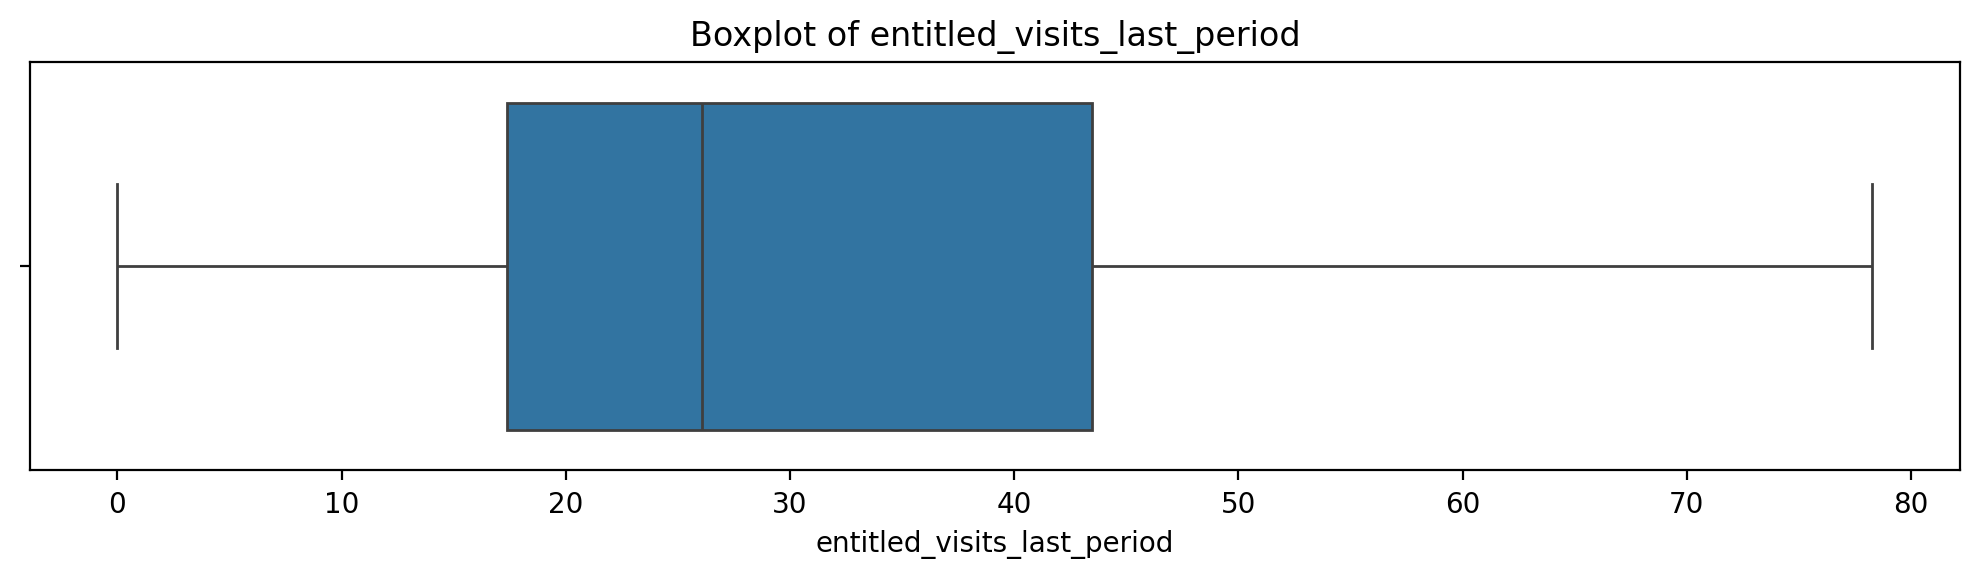

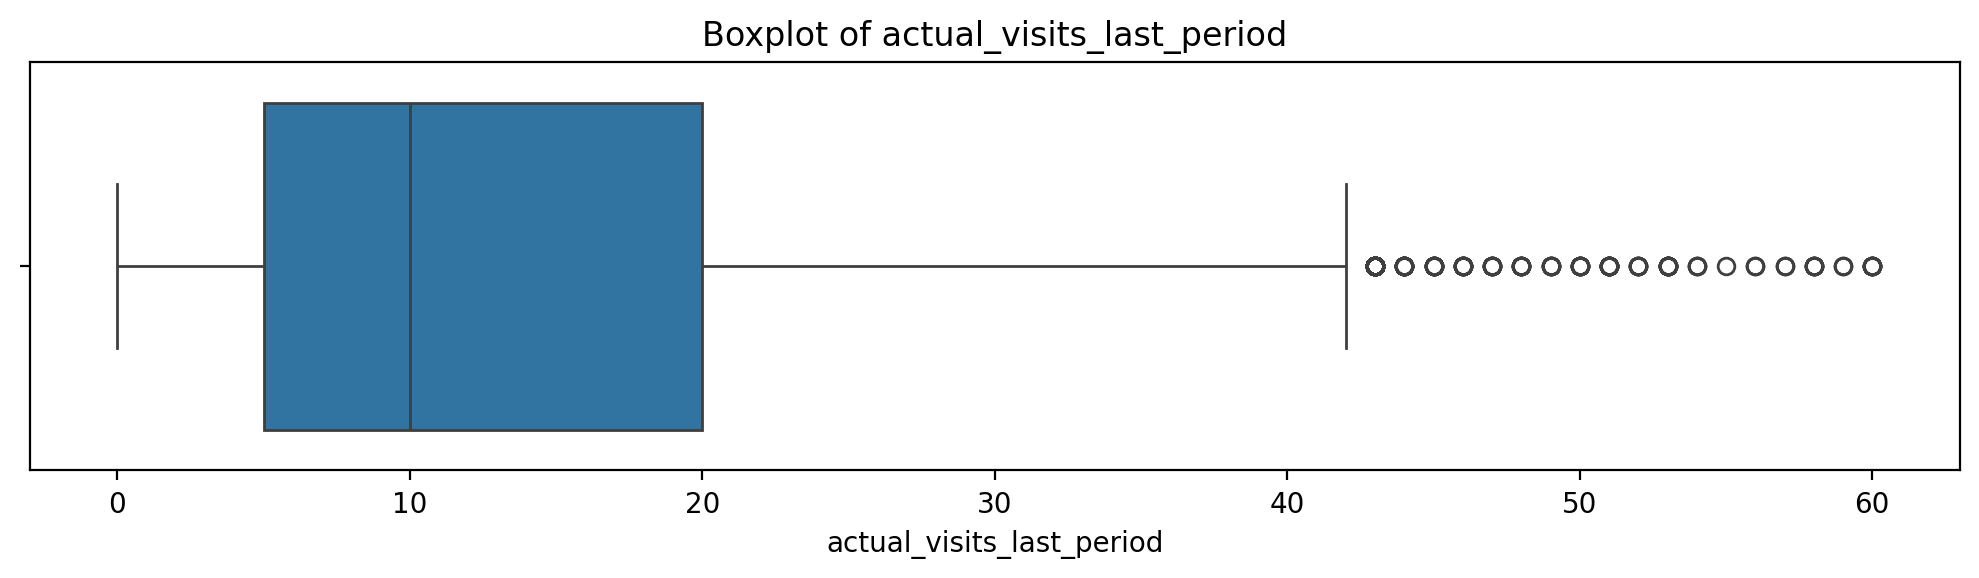

In [13]:
outlier_cols = [
    "age",
    "total_visits",
    "avg_weekly_visits",
    "meeting_room_hours",
    "event_space_hours",
    "guest_passes_issued",
    "n_renewals", 
    "lifetime_value", 
    "n_colleagues_on_account", 
    "plan_days_per_week",
    "days_since_last_visit",
    "entitled_visits_last_period",
    "actual_visits_last_period"
]

for col in outlier_cols:
    plt.figure(figsize=(10, 3))
    values = numeric[col] if col == "lifetime_value" else acdc[col]
    sns.boxplot(x=values, showfliers=(col != "lifetime_value"))
    title = f"Boxplot of {col}"
    if col == "lifetime_value":
        title += " (outliers hidden)"
        plt.xlabel("Lifetime value")
        plt.ticklabel_format(axis="x", style="plain", useOffset=False)
    plt.title(title)
    plt.tight_layout()
    plt.show()

For our variables:

- Age: outliers at very low or very high ages may be data-quality problems if they are unrealistic.
- Total visits: high outliers may be genuinely very active or long-term members.
- Average weekly visits: very high outliers may indicate unusually active members, but they should be checked for plausibility.
- Meeting room hours: high outliers may indicate members who use meeting rooms much more than others, which could be a meaningful customer profile.
- Event space hours: same idea; extreme users may represent a distinct behavioral group.
- Guest passes issued: high values may indicate members who frequently bring clients or guests.
- Number of renewals: high positive values may indicate loyal long-term members, while negative values would be a data-quality problem.

## Correlation and redundancy

Lets try to apply a Spearman correlation to our data to see which behaviors move together and which variables might be redundant when we later build the clustering model. Spearman correlation was used because several numerical variables contain extreme values. As a rank-based measure, Spearman is less sensitive to outliers and can identify monotonic relationships that are not necessarily linear.

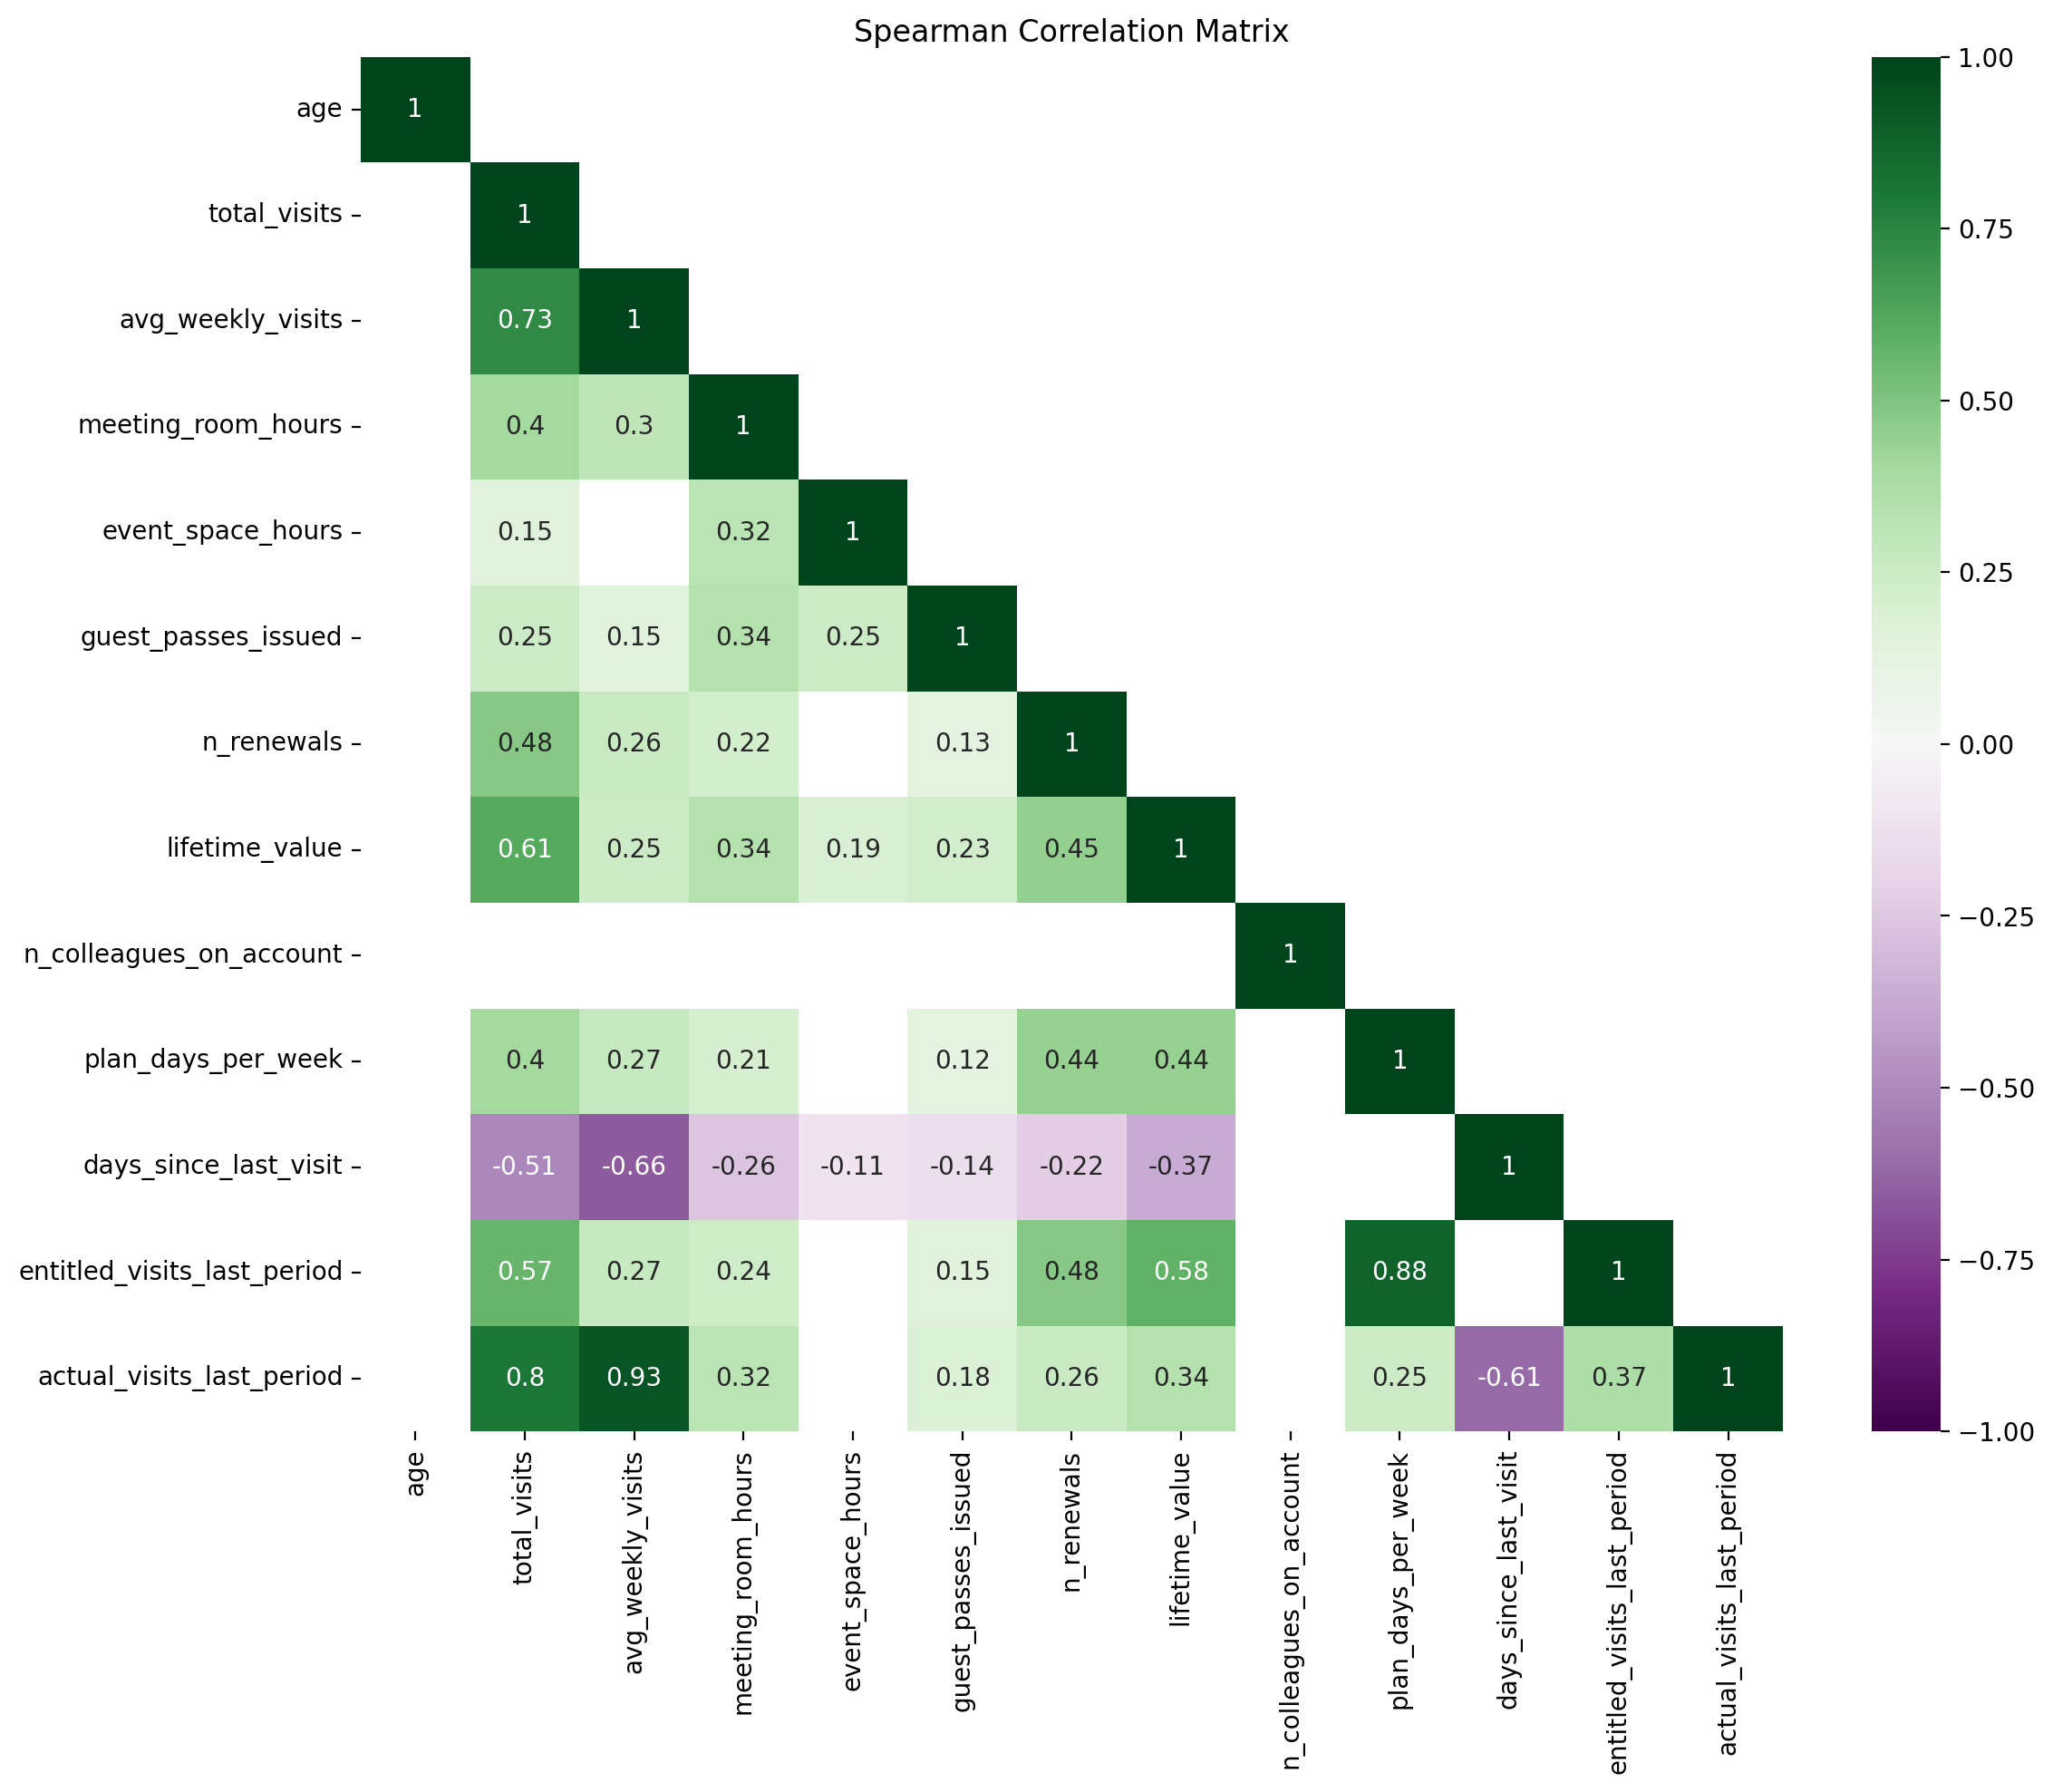

In [14]:
#Variables i want to include in the correlation analysis, aka numeric variables
corr_cols = [
    "age",
    "total_visits",
    "avg_weekly_visits",
    "meeting_room_hours",
    "event_space_hours",
    "guest_passes_issued",
    "n_renewals", 
    "lifetime_value", 
    "n_colleagues_on_account", 
    "plan_days_per_week",
    "days_since_last_visit",
    "entitled_visits_last_period",
    "actual_visits_last_period"
]

numeric["lifetime_value"] = pd.to_numeric(
    acdc["lifetime_value"].astype("string").str.replace(r"[€,]", "", regex=True),
    errors="coerce",
)

corr = numeric[corr_cols].corr(method="spearman").round(2)
plt.figure(figsize=(12, 10)) #size of the graph
sns.heatmap(
    corr,
    mask=(~np.tril(np.ones_like(corr, dtype=bool))) | (corr.abs() < 0.10),
    #tril hides the upper traingle, upper triangle is True but Seaborn hides True cells, so we add the "~"
    annot=True,#write the correlation value inside each square 
    cmap='PRGn', #colour palette
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout() #helps prevent labels from overlapping or being cut off
plt.show()
# also the values close to zero(check distributions because they could still relate to eachother



# avg_weekly_visits ↔ actual_visits_last_period = 0.93
# Members with higher weekly visit frequency generally also have more actual visits in the recent period.
# people who rank high in average weekly visits also rank high on actual visits last period

# days_since_last_visit ↔ avg_weekly_visits = -0.66
# As the number of days since the last visit increases, weekly visit frequency generally decreases.

# Age shows little monotonic(means if one grows the other typically grows or decreases too)
# relationship with all variables according to Spearman correlation but it doesnt mean it has no relationship at all

Spearman correlation was used to examine monotonic relationships between numerical variables. The upper triangle was removed because the correlation matrix is symmetrical, and very weak correlations were hidden to improve readability. Strong correlations may indicate related or potentially redundant variables. However, correlations close to zero do not necessarily indicate the absence of a relationship, as non-linear patterns may still be present and should be investigated through distributions and other visualizations.

### Detailed look at specific variables

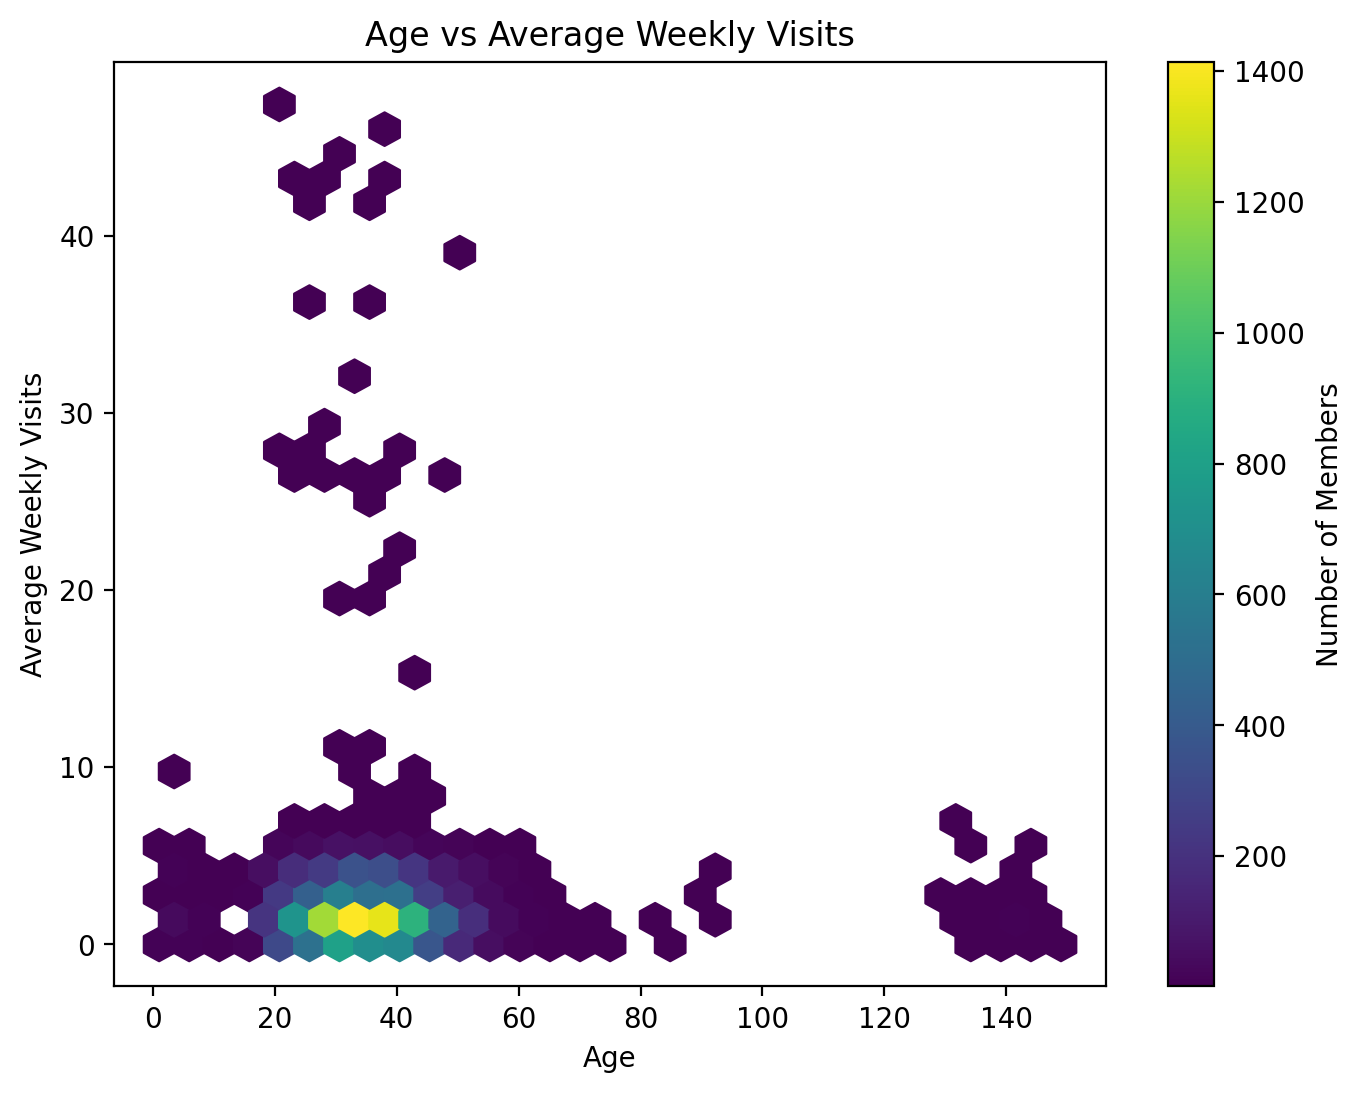

Spearman correlation: 0.01


In [15]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    acdc["age"],
    acdc["avg_weekly_visits"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.xlabel("Age")
plt.ylabel("Average Weekly Visits")
plt.title("Age vs Average Weekly Visits")

plt.colorbar(label="Number of Members")
plt.show()

rho = acdc["age"].corr(acdc["avg_weekly_visits"], method="spearman")
print("Spearman correlation:", round(rho, 2))

The hexbin plot does not suggest a clear increasing or decreasing relationship between age and average weekly visits. Instead, the observations are concentrated in particular areas of the distribution, showing that members with similar ages can have quite different levels of weekly activity.

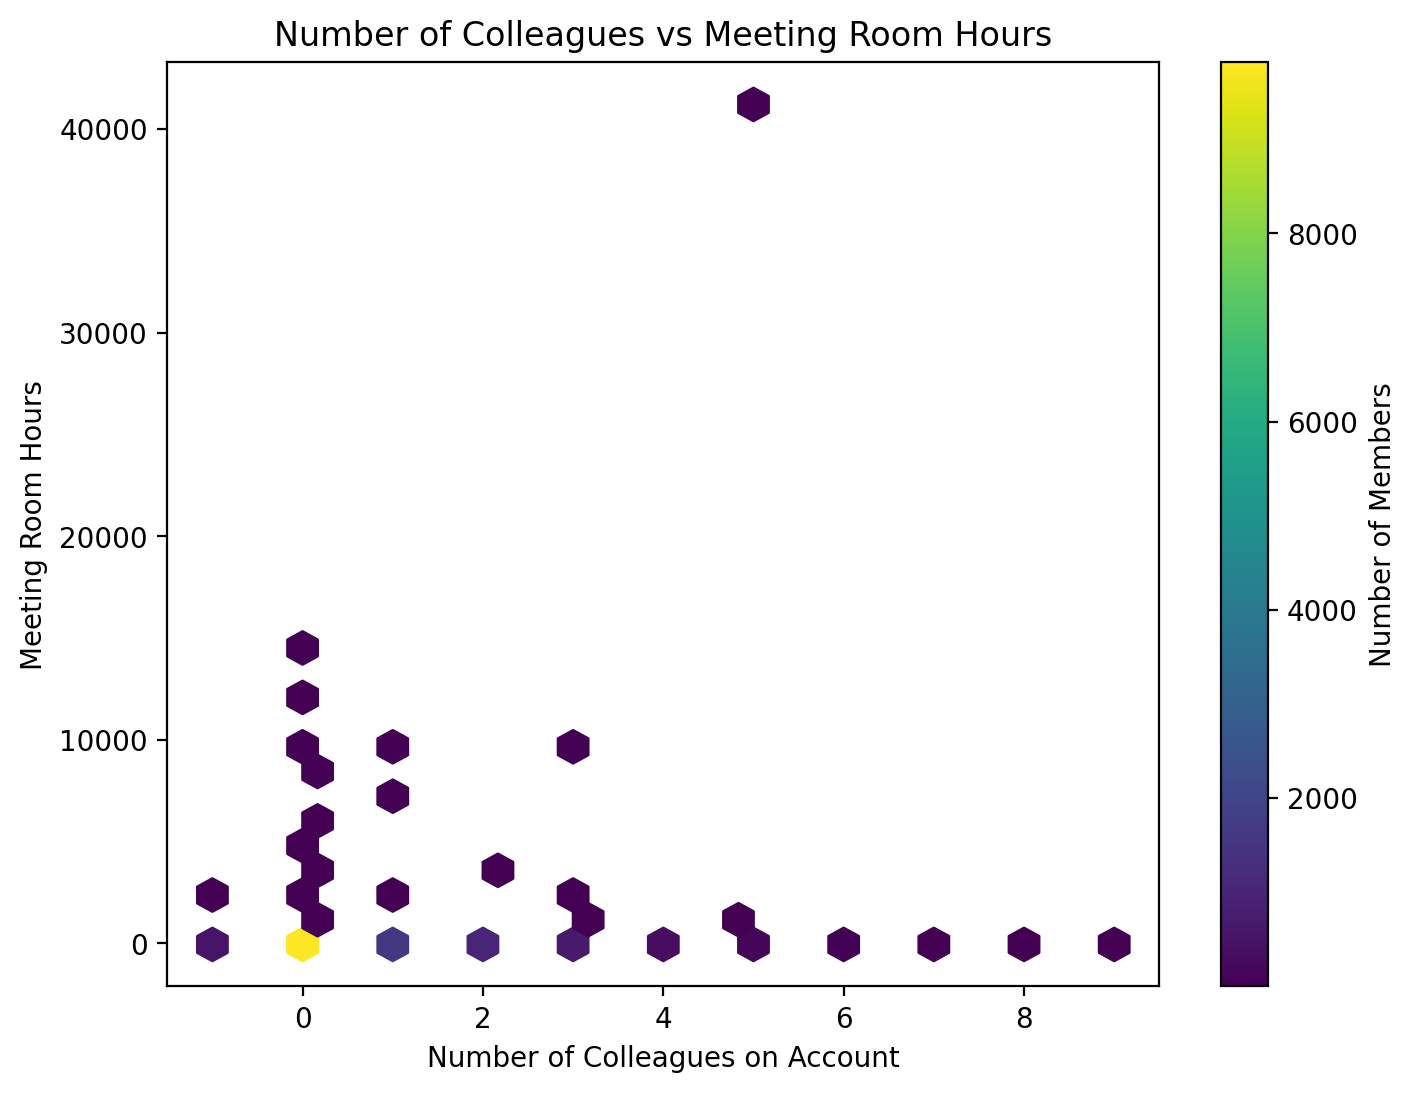

Spearman correlation: 0.01


In [16]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    acdc["n_colleagues_on_account"],
    acdc["meeting_room_hours"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.xlabel("Number of Colleagues on Account")
plt.ylabel("Meeting Room Hours")
plt.title("Number of Colleagues vs Meeting Room Hours")

plt.colorbar(label="Number of Members")
plt.show()
rho = acdc["n_colleagues_on_account"].corr(acdc["meeting_room_hours"], method="spearman")
print("Spearman correlation:", round(rho, 2))

No clear monotonic relationship is visible between the number of colleagues on an account and meeting-room usage. Most members are concentrated around low values for both variables. However, the graph reveals that there is extremely large meeting-room-hour values, plus a negative value for number of colleagues. Those are strong anomalies.

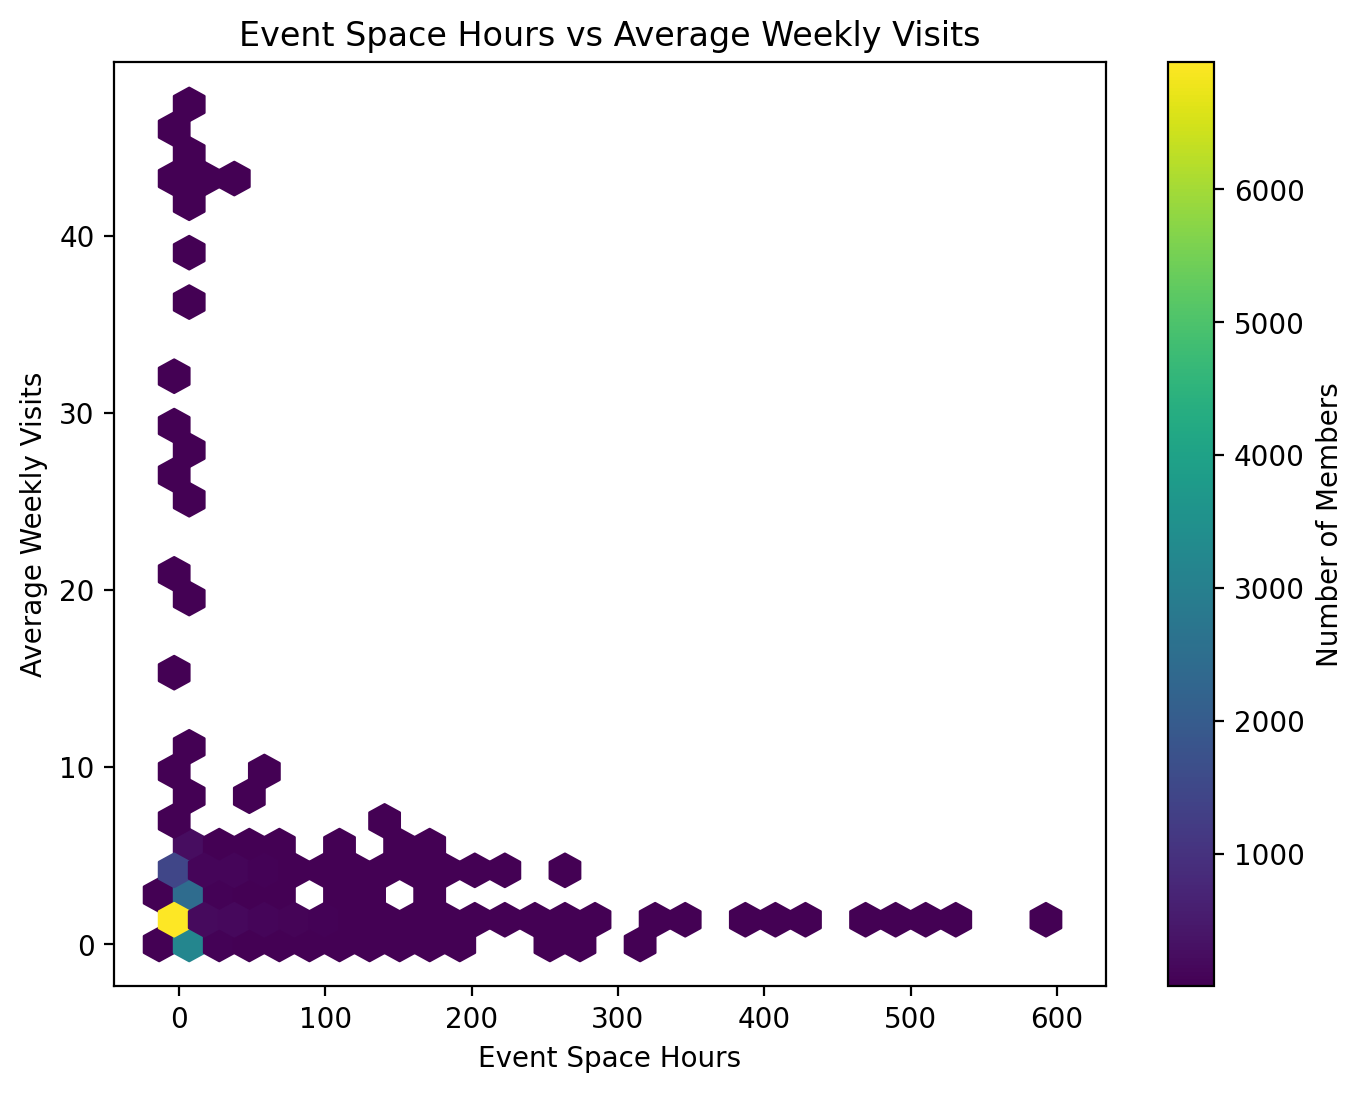

Spearman correlation: 0.07


In [17]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    acdc["event_space_hours"],
    acdc["avg_weekly_visits"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.xlabel("Event Space Hours")
plt.ylabel("Average Weekly Visits")
plt.title("Event Space Hours vs Average Weekly Visits")

plt.colorbar(label="Number of Members")
plt.show()

rho = acdc["event_space_hours"].corr(acdc["avg_weekly_visits"], method="spearman")
print("Spearman correlation:", round(rho, 2))

Event-space usage shows little evidence of a strong monotonic relationship with average weekly visits. Most members have low values for both variables, while high event-space usage is mainly associated with low weekly visits. This suggests that event-space hours may capture a different behavioral dimension from regular workspace attendance.

                             missing       min  median     mean         max   skew  kurtosis  pct_zero  n_negative
age                              558      1.00   34.00    34.86      149.00   3.03     28.89      0.00           0
n_colleagues_on_account            0     -1.00    0.00     0.54        9.00   2.12      4.83     69.18         566
plan_days_per_week                 0      0.00    3.00     3.39        9.00   0.93      0.26      0.28           0
days_since_last_visit              0   -956.00   13.00   117.11     1212.00   2.72      5.99      0.55          56
total_visits                       0   -112.00   34.00   110.41     6530.00   6.81    159.60      0.70          42
avg_weekly_visits                  0      0.00    1.42     1.78       47.40  10.27    190.12      0.09           0
entitled_visits_last_period        0      0.00   26.09    27.52       78.27   0.73     -0.00      0.06           0
actual_visits_last_period          0      0.00   10.00    13.80       60.00   1.

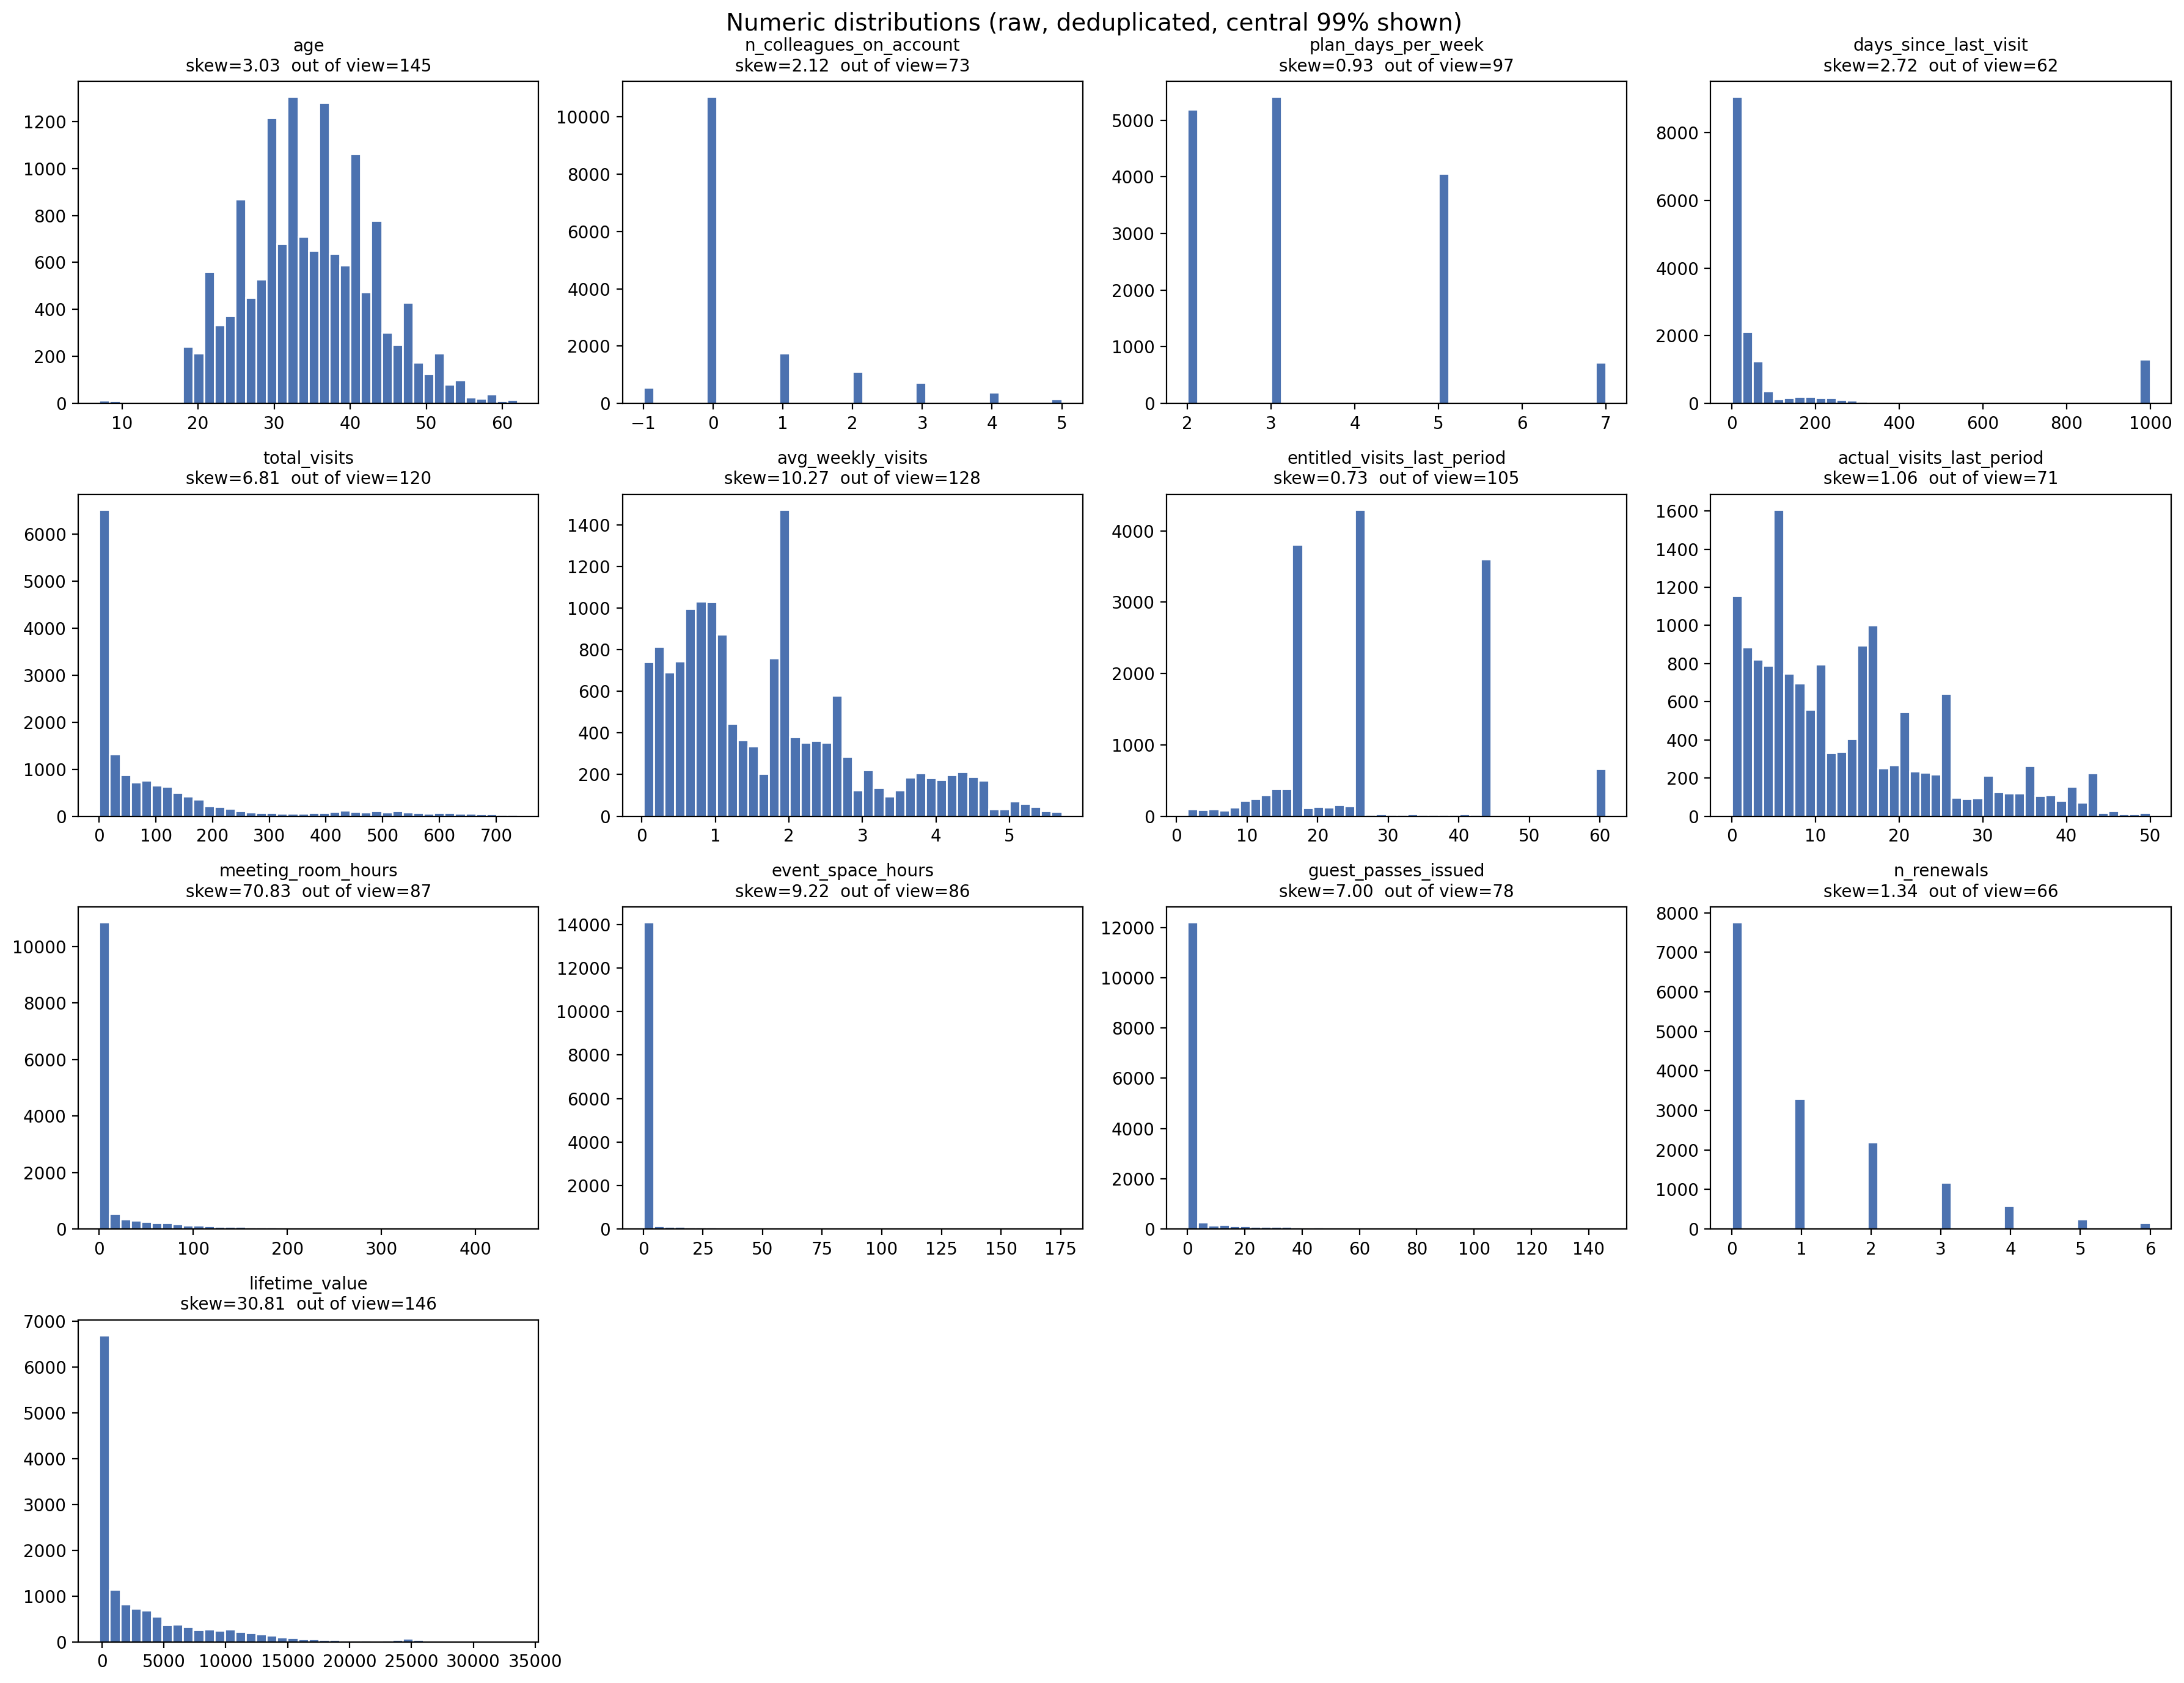

In [18]:
acdc.drop_duplicates()
acdc["lifetime_value"] = pd.to_numeric(acdc["lifetime_value"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(), errors="coerce")

num_cols = ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit",
            "total_visits", "avg_weekly_visits", "entitled_visits_last_period",
            "actual_visits_last_period", "meeting_room_hours", "event_space_hours",
            "guest_passes_issued", "n_renewals", "lifetime_value"]

stats = pd.DataFrame({
    "missing": acdc[num_cols].isna().sum(),
    "min": acdc[num_cols].min(),
    "median": acdc[num_cols].median(),
    "mean": acdc[num_cols].mean(),
    "max": acdc[num_cols].max(),
    "skew": acdc[num_cols].skew(),
    "kurtosis": acdc[num_cols].kurt(),
    "pct_zero": (acdc[num_cols] == 0).mean() * 100,
    "n_negative": (acdc[num_cols] < 0).sum(),
}).round(2)
print(stats.to_string())
stats.to_csv("numeric_stats.csv")

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, num_cols):
    s = acdc[col].dropna()
    lo, hi = s.quantile([0.005, 0.995])
    s_clip = s[(s >= lo) & (s <= hi)]
    ax.hist(s_clip, bins=40, color="#4C72B0", edgecolor="white")
    ax.set_title(f"{col}\nskew={s.skew():.2f}  out of view={len(s) - len(s_clip)}", fontsize=10)
for ax in axes.flat[len(num_cols):]:
    ax.axis("off")
fig.suptitle("Numeric distributions (raw, deduplicated, central 99% shown)", fontsize=14)
fig.tight_layout()
fig.savefig("numeric_distributions.png", dpi=110)

## Feature Engineering

New features are created from existing variables to capture member behaviour in a simpler and potentially more useful way for segmentation.

Two features are explored:
- **Visit utilization:** how much of the member's allowed visits were actually used.
- **Number of services used:** how many different additional services each member uses.

#### Visit utilization

In [19]:
acdc["visit_utilization"] = (
    acdc["actual_visits_last_period"] /
    acdc["entitled_visits_last_period"].replace(0, np.nan)
)

acdc["visit_utilization"].describe()

count    15455.000000
mean         0.517490
std          0.312224
min          0.000000
25%          0.238445
50%          0.517539
75%          0.804906
max          1.000000
Name: visit_utilization, dtype: float64

Member was allowed 20 visits, member actually used 10
- 10 / 20 = 0.5, they used 50% of their allowed visits 

Visit utilization measures the proportion of entitled visits that each member actually used. The average visit utilization is approximately 52%, meaning that members used, on average, about half of the visits available in their plan. Tere are members with very low and very high utilization, suggesting different levels of engagement with their membership plans.

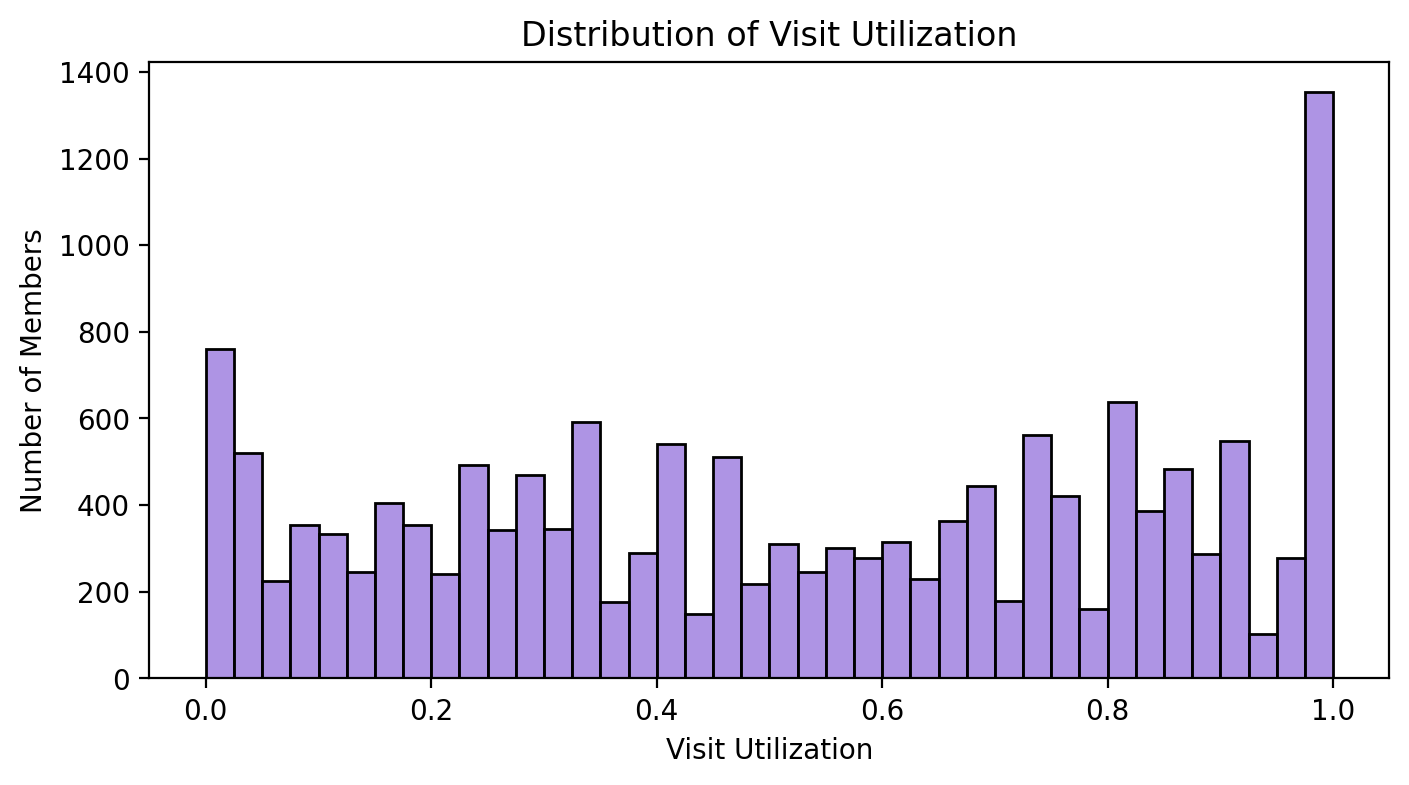

In [20]:
plt.figure(figsize=(8, 4))

sns.histplot(
    acdc["visit_utilization"].dropna(),
    bins=40,
    color="mediumpurple"
)

plt.title("Distribution of Visit Utilization")
plt.xlabel("Visit Utilization")
plt.ylabel("Number of Members")

plt.show()

#### Number of Services Used

This feature counts how many different additional services each member uses.
It may help distinguish members who mainly use the basic workspace from members
who make broader use of ACDC's services.

In [21]:
service_cols = [
    "uses_meeting_rooms",
    "uses_event_space",
    "uses_guest_passes",
    "uses_print",
    "uses_mail_handling",
    "uses_phone_booths",
    "uses_day_passes",
    "uses_storage",
    "uses_bike_locker"
]

acdc["n_services_used"] = acdc[service_cols].sum(axis=1)

acdc["n_services_used"].value_counts().sort_index()

n_services_used
0    3091
1    4645
2    3240
3    2141
4    1397
5     690
6     224
7      34
8       3
Name: count, dtype: int64

The most common number of services used is 1, with 4,645 members. Most members use only a small number of additional services, while members using many different services are much less common. This may help distinguish between members with basic service usage and members with more engagement with ACDC's services.

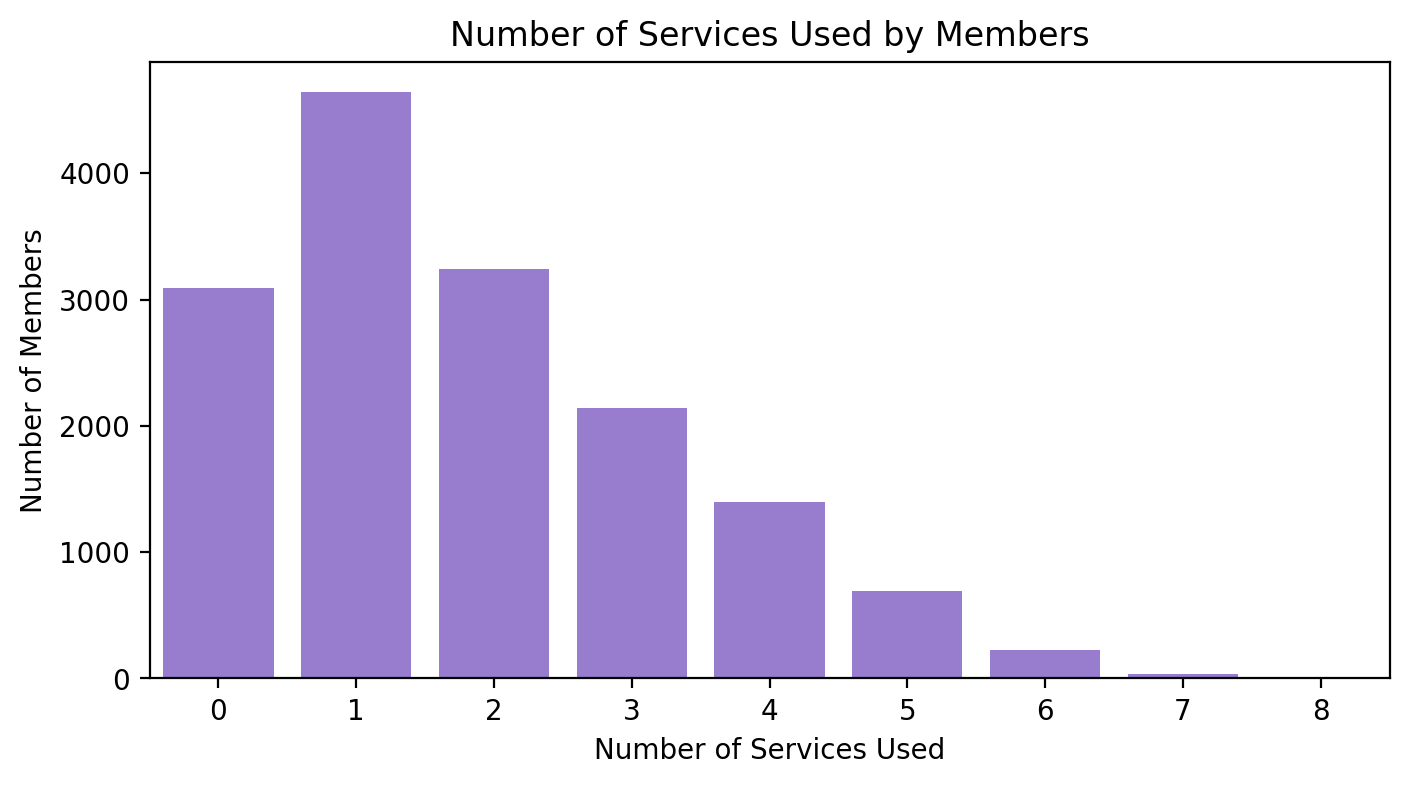

In [22]:
plt.figure(figsize=(8, 4))

sns.countplot(
    data=acdc,
    x="n_services_used",
    color="mediumpurple"
)

plt.title("Number of Services Used by Members")
plt.xlabel("Number of Services Used")
plt.ylabel("Number of Members")

plt.show()

## Clustering-focused synthesis and comparisons

### Why these variables?

The goal is to discover member groups from **behavior**, not to predict a known label. This EDA therefore examines four possible dimensions: (1) visit engagement and recency, (2) use of the visits included in a plan, (3) breadth and type of service use, and (4) individual versus team-oriented use. These are candidate dimensions to investigate, not a predetermined answer. Demographics and plan categories can help describe or contextualize patterns, but should not automatically define behavioral clusters.

The comparisons below ask whether each candidate dimension varies meaningfully, adds information beyond the others, and is reliable enough to use. No clustering model is fitted in this EDA; cluster count and profiles must be evaluated in the modeling stage.


### Data-quality review before interpreting patterns

Exact duplicate rows should not count as separate members. Repeated IDs with different records need investigation rather than automatic deletion. Negative counts, hours, or recency values and implausible ages are flagged for source validation; they are not silently changed to zero. Missing usage values are kept missing unless the data definition confirms that missing means no usage.

In [23]:
# Work on a separate frame so this notebook's original EDA cells and `acdc` remain unchanged.
cluster_eda = acdc.copy()
exact_duplicate_count = int(cluster_eda.duplicated().sum())
repeated_id_rows = cluster_eda.loc[cluster_eda["member_id"].duplicated(keep=False)]
conflicting_id_count = int(
    repeated_id_rows.drop_duplicates().groupby("member_id").size().gt(1).sum()
) if not repeated_id_rows.empty else 0
cluster_eda = cluster_eda.drop_duplicates().copy()
print(f"Rows before exact deduplication: {len(acdc):,}")
print(f"Exact duplicate rows removed: {exact_duplicate_count:,}")
print(f"Repeated IDs with conflicting records: {conflicting_id_count:,}")
print(f"Rows after exact deduplication: {len(cluster_eda):,}")

quality_checks = {
    "negative colleague counts": int((cluster_eda["n_colleagues_on_account"] < 0).sum()),
    "negative days since last visit": int((cluster_eda["days_since_last_visit"] < 0).sum()),
    "negative total visits": int((cluster_eda["total_visits"] < 0).sum()),
    "negative meeting-room hours": int((cluster_eda["meeting_room_hours"] < 0).sum()),
    "negative event-space hours": int((cluster_eda["event_space_hours"] < 0).sum()),
    "negative guest passes": int((cluster_eda["guest_passes_issued"] < 0).sum()),
    "negative renewals": int((cluster_eda["n_renewals"] < 0).sum()),
    "age below 18 (review, not automatically invalid)": int((cluster_eda["age"] < 18).sum()),
    "age above 100 (review)": int((cluster_eda["age"] > 100).sum()),
}
display(pd.Series(quality_checks, name="records to investigate").to_frame())


Rows before exact deduplication: 15,465
Exact duplicate rows removed: 15
Repeated IDs with conflicting records: 0
Rows after exact deduplication: 15,450


,records to investigate
negative colleague counts,565
negative days since last visit,56
negative total visits,42
negative meeting-room hours,16
negative event-space hours,8
negative guest passes,7
negative renewals,66
"age below 18 (review, not automatically invalid)",98
age above 100 (review),45


### Do members use different plans differently?

Compare attendance and visit utilization across plan tiers. The utilization ratio is actual visits divided by entitled visits; rows with zero entitlement have no defined ratio and remain missing. This comparison helps distinguish high attendance from high use *relative to entitlement*. Small groups and inconsistent plan labels should be handled before interpreting differences.

,members,weekly_visits_median,utilization_median
plan_tier_clean,,,
Flex,5449,1.89,0.57
Hot desk,5212,0.96,0.46
Full time,2471,1.61,0.33
Dedicated desk,1549,3.86,0.74
Private office,664,1.04,0.15
Missing / review,105,3.98,0.67


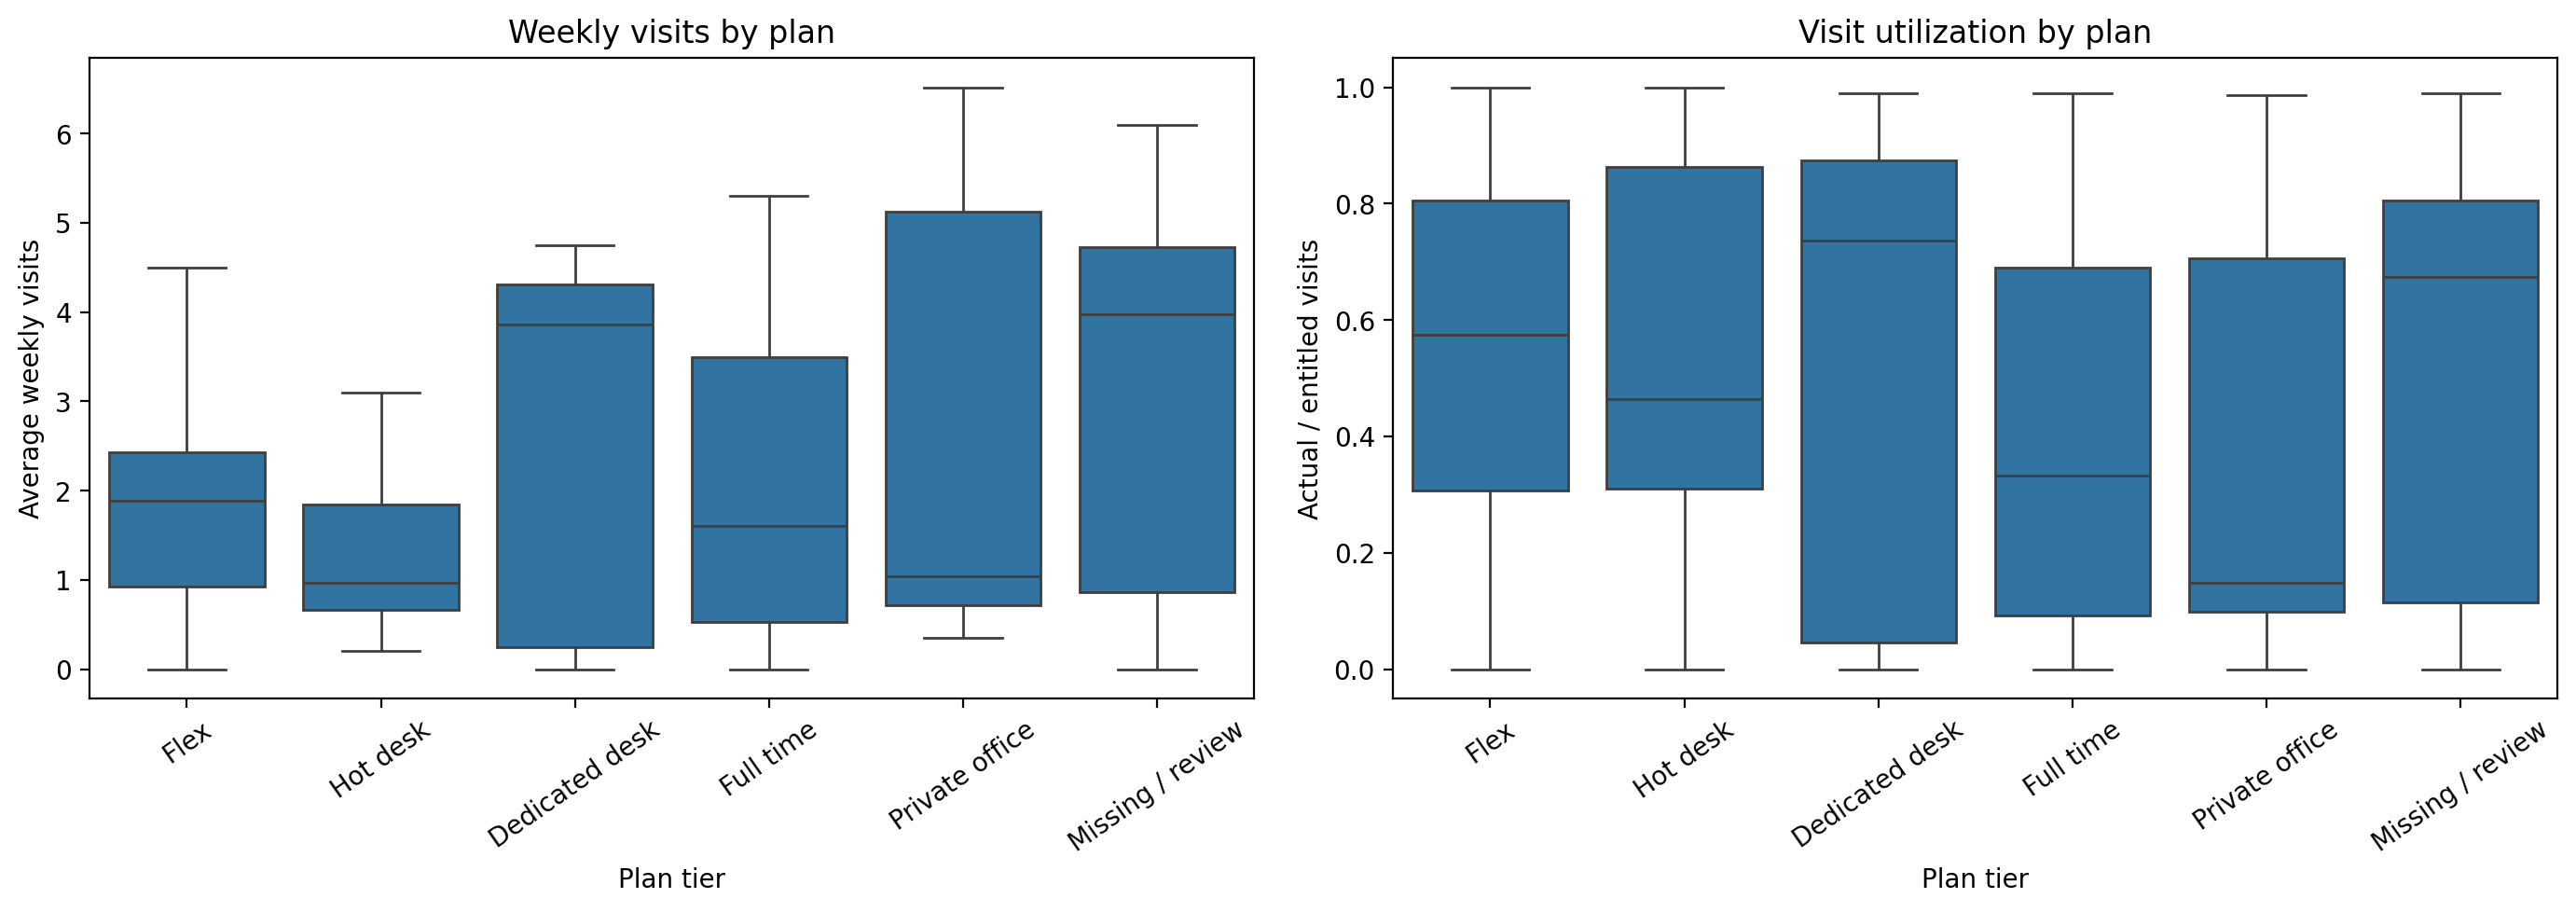

In [24]:
# Normalize spelling/case for this comparison only; preserve the original source values.
plan_key = (cluster_eda["plan_tier"].astype("string").str.strip().str.lower()
            .str.replace(r"[\s_-]+", "", regex=True))
plan_map = {
    "flex": "Flex", "hotdesk": "Hot desk", "fulltime": "Full time",
    "dedicateddesk": "Dedicated desk", "privateoffice": "Private office",
}
cluster_eda["plan_tier_clean"] = plan_key.map(plan_map).fillna("Missing / review")
cluster_eda["visit_utilization"] = (
    cluster_eda["actual_visits_last_period"] /
    cluster_eda["entitled_visits_last_period"].replace(0, np.nan)
)
plan_summary = (cluster_eda.groupby("plan_tier_clean", observed=True)
                .agg(members=("member_id", "size"),
                     weekly_visits_median=("avg_weekly_visits", "median"),
                     utilization_median=("visit_utilization", "median"))
                .sort_values("members", ascending=False))
display(plan_summary.round(2))

plot_plans = plan_summary.index[plan_summary["members"] >= 30]
plot_data = cluster_eda.loc[cluster_eda["plan_tier_clean"].isin(plot_plans)]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=plot_data, x="plan_tier_clean", y="avg_weekly_visits", showfliers=False, ax=axes[0])
axes[0].set(title="Weekly visits by plan", xlabel="Plan tier", ylabel="Average weekly visits")
sns.boxplot(data=plot_data, x="plan_tier_clean", y="visit_utilization", showfliers=False, ax=axes[1])
axes[1].set(title="Visit utilization by plan", xlabel="Plan tier", ylabel="Actual / entitled visits")
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()


### How do attendance and recency relate?

Plot average weekly visits against days since the last visit, excluding negative recency values from this visualization because they need validation. A relationship can indicate a useful engagement dimension, but related attendance variables should not all be given equal weight in a distance-based model.

Spearman correlation (valid non-negative recency rows, n=15,394): -0.66


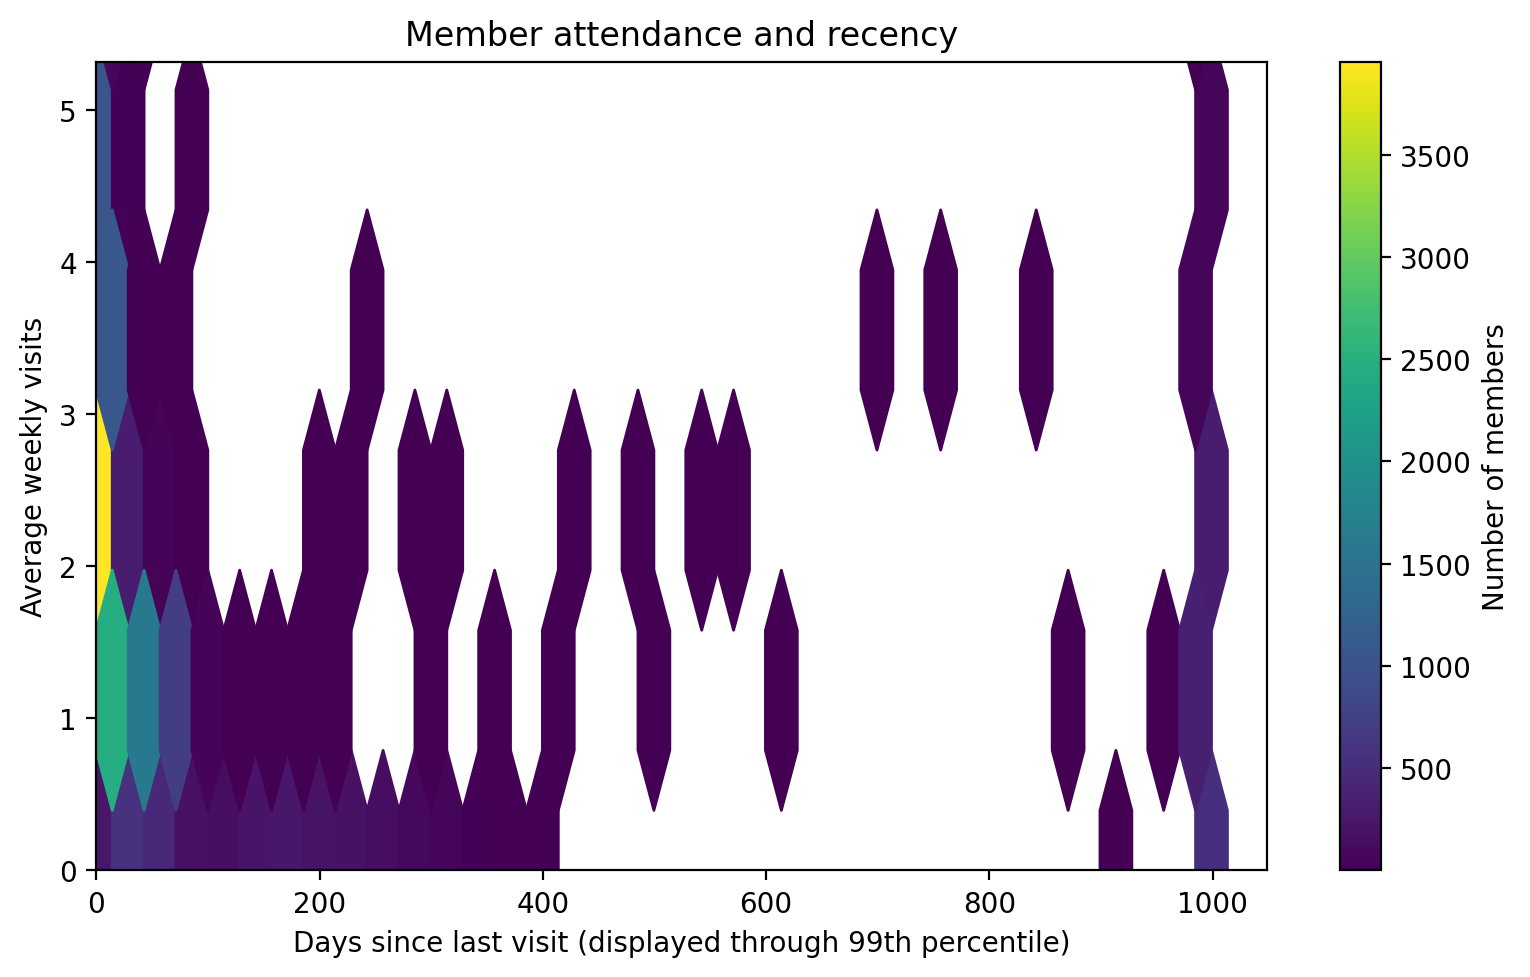

In [25]:
valid_activity = cluster_eda.loc[
    (cluster_eda["days_since_last_visit"] >= 0) &
    (cluster_eda["avg_weekly_visits"] >= 0),
    ["days_since_last_visit", "avg_weekly_visits"],
].dropna()
activity_rho = valid_activity.corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation (valid non-negative recency rows, n={len(valid_activity):,}): {activity_rho:.2f}")

# Limit the displayed axes to the 99th percentile to make the main concentration visible;
# this only changes the view, not the underlying analysis data.
x_limit, y_limit = valid_activity.quantile(0.99)
plot_activity = valid_activity.loc[
    valid_activity["days_since_last_visit"] <= x_limit
].copy()
plt.figure(figsize=(8, 5))
plt.hexbin(plot_activity["days_since_last_visit"], plot_activity["avg_weekly_visits"],
           gridsize=35, mincnt=1, cmap="viridis")
plt.xlim(left=0)
plt.ylim(bottom=0, top=y_limit)
plt.xlabel("Days since last visit (displayed through 99th percentile)")
plt.ylabel("Average weekly visits")
plt.title("Member attendance and recency")
plt.colorbar(label="Number of members")
plt.tight_layout()
plt.show()


### Do service choices distinguish different kinds of engagement?

The total number of services is a useful summary but hides *which* services members use. Compare individual service-use rates and their median weekly visits/utilization. These are descriptive associations, not evidence that using a service causes more visits. Very rare services may be too sparse to drive clustering reliably.

,service,members_using,share_using_pct,median_weekly_visits_when_used,median_utilization_when_used
0,meeting_rooms,5258,34.03,1.95,0.62
3,print,4992,32.31,2.11,0.71
5,phone_booths,3990,25.83,1.98,0.69
4,mail_handling,3560,23.04,1.90,0.59
6,day_passes,3394,21.97,1.19,0.46
2,guest_passes,2811,18.19,1.75,0.58
7,storage,2293,14.84,2.53,0.69
1,event_space,1838,11.90,1.38,0.50
8,bike_locker,26,0.17,1.17,0.38


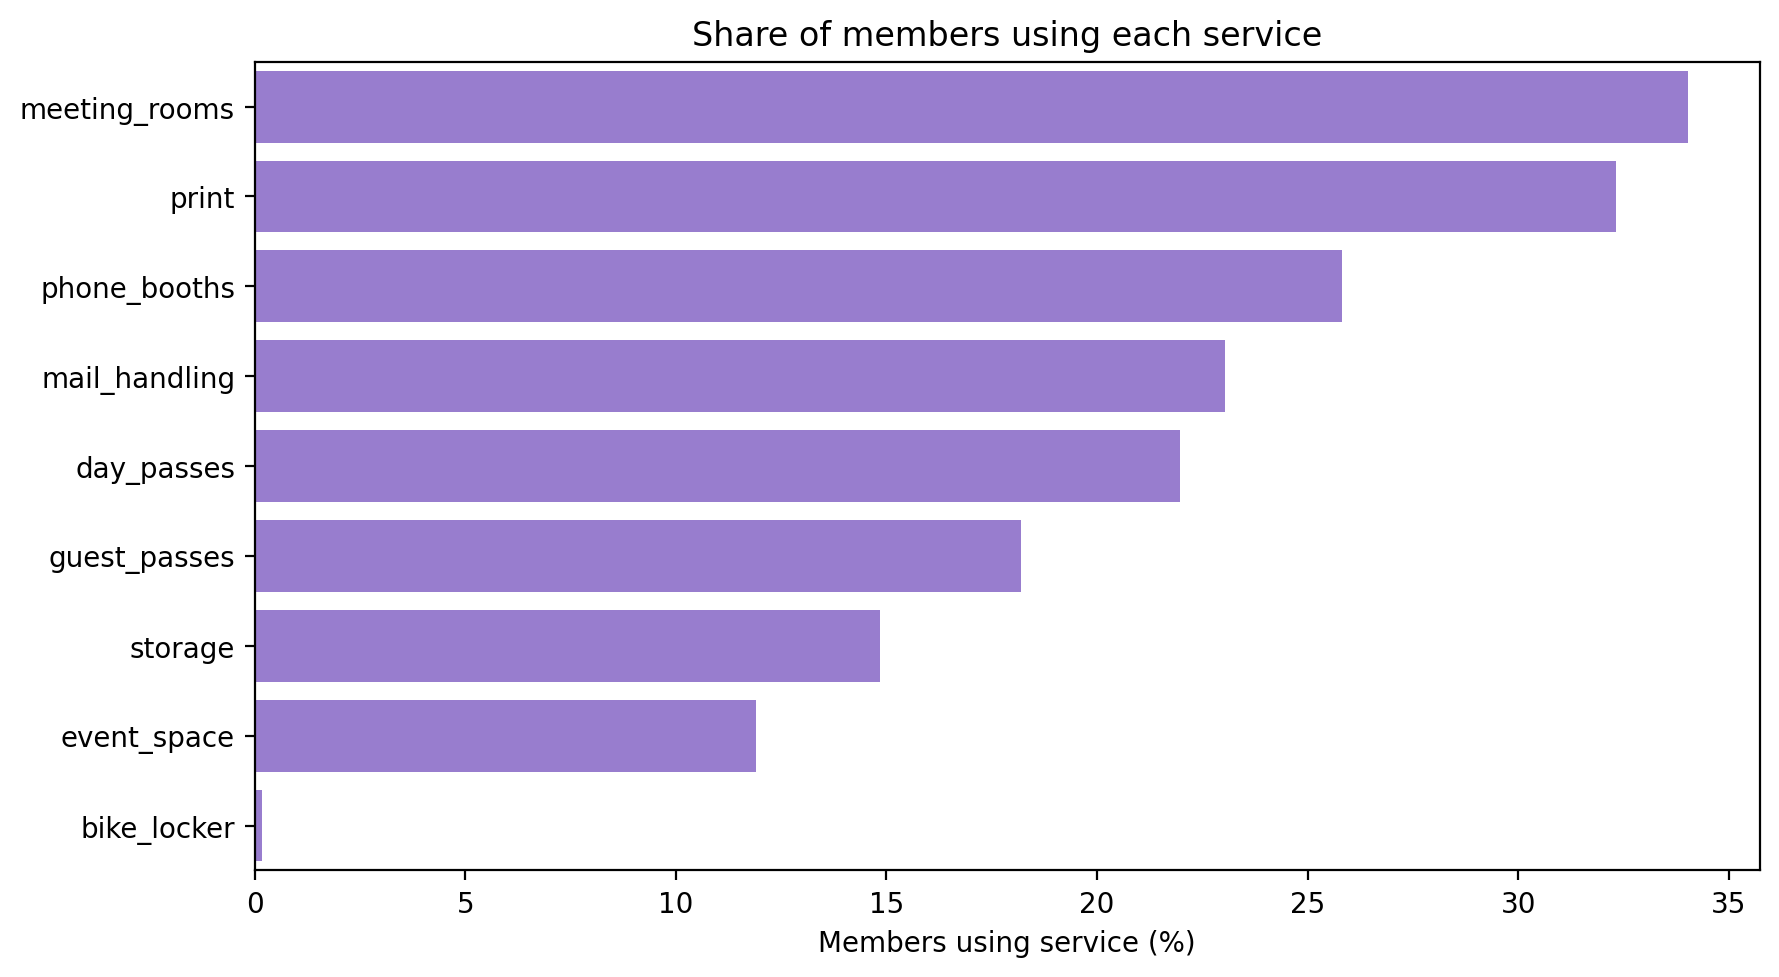

In [26]:
service_cols = [
    "uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print",
    "uses_mail_handling", "uses_phone_booths", "uses_day_passes", "uses_storage",
    "uses_bike_locker",
]
service_summary = []
for column in service_cols:
    used = cluster_eda[column].fillna(False).astype(bool)
    service_summary.append({
        "service": column.removeprefix("uses_"),
        "members_using": int(used.sum()),
        "share_using_pct": 100 * used.mean(),
        "median_weekly_visits_when_used": cluster_eda.loc[used, "avg_weekly_visits"].median(),
        "median_utilization_when_used": cluster_eda.loc[used, "visit_utilization"].median(),
    })
service_summary = pd.DataFrame(service_summary).sort_values("share_using_pct", ascending=False)
display(service_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=service_summary, x="share_using_pct", y="service", color="mediumpurple", ax=ax)
ax.set(title="Share of members using each service", xlabel="Members using service (%)", ylabel="")
plt.tight_layout()
plt.show()


### Is team-oriented use a different behavioral dimension?

Compare team and non-team accounts on colleagues, meeting-room use, guest passes, and attendance. This can identify whether collaboration-related features add a distinct signal. Check the definition and level of each record first: if a row represents an individual within a team account, team-level properties may be repeated across members.

In [27]:
team_summary = (cluster_eda.groupby("is_team_account", dropna=False)
                .agg(members=("member_id", "size"),
                     colleagues_median=("n_colleagues_on_account", "median"),
                     weekly_visits_median=("avg_weekly_visits", "median"),
                     meeting_room_hours_median=("meeting_room_hours", "median"),
                     guest_passes_median=("guest_passes_issued", "median"),
                     meeting_room_use_pct=("uses_meeting_rooms", lambda s: 100 * s.astype(bool).mean()),
                     guest_pass_use_pct=("uses_guest_passes", lambda s: 100 * s.astype(bool).mean())))
display(team_summary.round(2))


,members,colleagues_median,weekly_visits_median,meeting_room_hours_median,guest_passes_median,meeting_room_use_pct,guest_pass_use_pct
is_team_account,,,,,,,
False,11100,0.0,1.42,0.0,0.0,33.83,18.22
True,4350,2.0,1.45,0.0,0.0,34.55,18.14


### Demographics as context, not assumed cluster inputs

Age and gender can be checked against behavior to see whether eventual clusters disproportionately include particular groups. Here they are used only to describe attendance patterns. Clean common gender spellings for this comparison, retain unknown values, and suppress tiny groups. Demographic associations do not establish causes and sensitive characteristics should not automatically be used as clustering features.

,age_band,gender_clean,members,weekly_visits_median
0,Under 18 (review),Female,56,1.92
1,Under 18 (review),Male,35,1.04
4,18-24,Female,877,1.23
5,18-24,Male,713,1.45
6,18-24,Missing / review,62,1.06
7,18-24,Other,64,1.40
8,25-34,Female,2919,1.44
9,25-34,Male,2453,1.41
10,25-34,Missing / review,200,1.83
11,25-34,Other,180,1.48


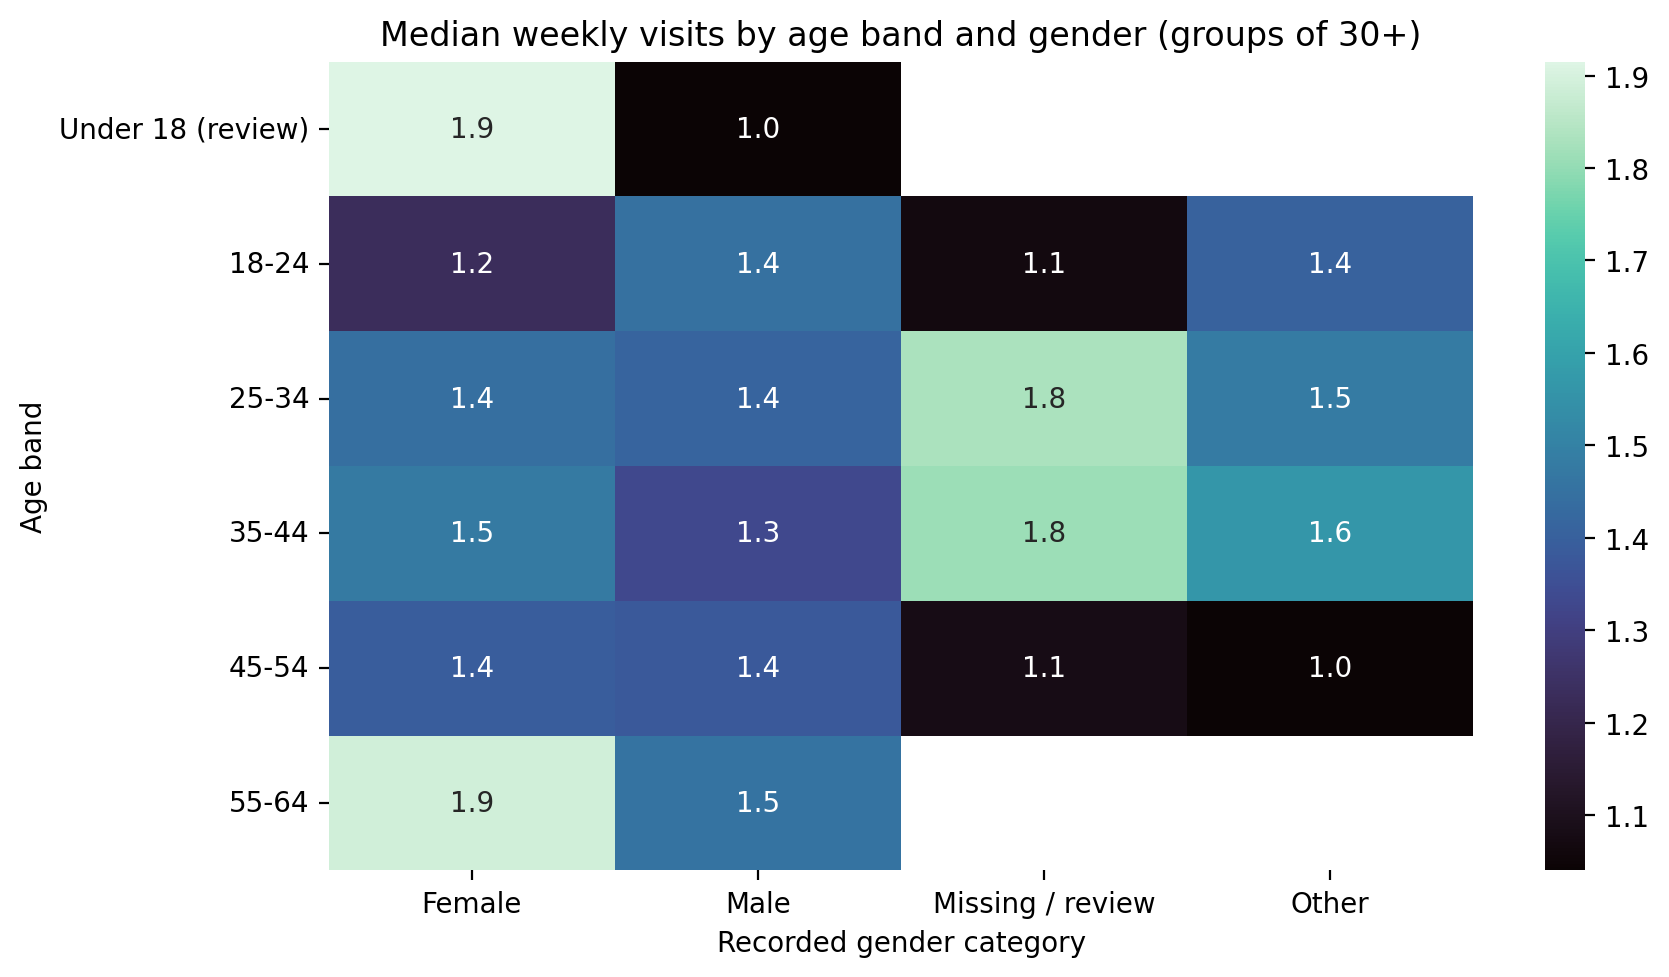

In [28]:
gender_key = cluster_eda["gender"].astype("string").str.strip().str.casefold()
gender_map = {"female": "Female", "f": "Female", "male": "Male", "m": "Male",
              "other": "Other", "o": "Other"}
cluster_eda["gender_clean"] = gender_key.map(gender_map).fillna("Missing / review")
cluster_eda["age_band"] = pd.cut(
    cluster_eda["age"], bins=[-np.inf, 17, 24, 34, 44, 54, 64, 100, np.inf],
    labels=["Under 18 (review)", "18-24", "25-34", "35-44", "45-54", "55-64", "65-100", "Over 100 (review)"],
)
demo_counts = (cluster_eda.groupby(["age_band", "gender_clean"], observed=True)
               .agg(members=("member_id", "size"),
                    weekly_visits_median=("avg_weekly_visits", "median"))
               .reset_index())
display(demo_counts.loc[demo_counts["members"] >= 30].round(2))
demo_plot = demo_counts.loc[demo_counts["members"] >= 30].pivot(
    index="age_band", columns="gender_clean", values="weekly_visits_median")
if not demo_plot.empty:
    plt.figure(figsize=(9, 5))
    sns.heatmap(demo_plot, annot=True, fmt=".1f", cmap="mako")
    plt.title("Median weekly visits by age band and gender (groups of 30+)")
    plt.xlabel("Recorded gender category")
    plt.ylabel("Age band")
    plt.tight_layout()
    plt.show()


### Membership dates and tenure

The source mixes ISO dates (for example, `2024-01-01`) with day-first slash dates (for example, `18/01/2022`). Parse those formats explicitly and use ISO `YYYY-MM-DD` for a consistent representation. Lifetime totals (such as total visits, renewals, and lifetime value) can mainly reflect how long someone has been a member. Do not calculate current tenure from today's date unless the dataset's observation date is known.

### Standardize categories for interpretation

The raw category summaries include spelling, capitalization, abbreviation, and missing-value variants. Combine only clear aliases for exploratory summaries, keep the source fields unchanged, and review the mapping before using categorical features in a clustering model. Country and industry are mainly useful here for describing member mix and later profiling clusters.



country (top categories after clear alias mapping):


,members
country_clean,
Portugal,10499
United Kingdom,1165
Germany,901
Spain,741
France,533
Netherlands,487
Other (Europe),451
Missing,429
Ireland,244



industry (top categories after clear alias mapping):


,members
industry_clean,
Information Technology,3557
Consulting,2055
Design & Creative,1974
Marketing & PR,1962
Finance,1219
Other,1175
Legal,878
Education,775
Unknown,693


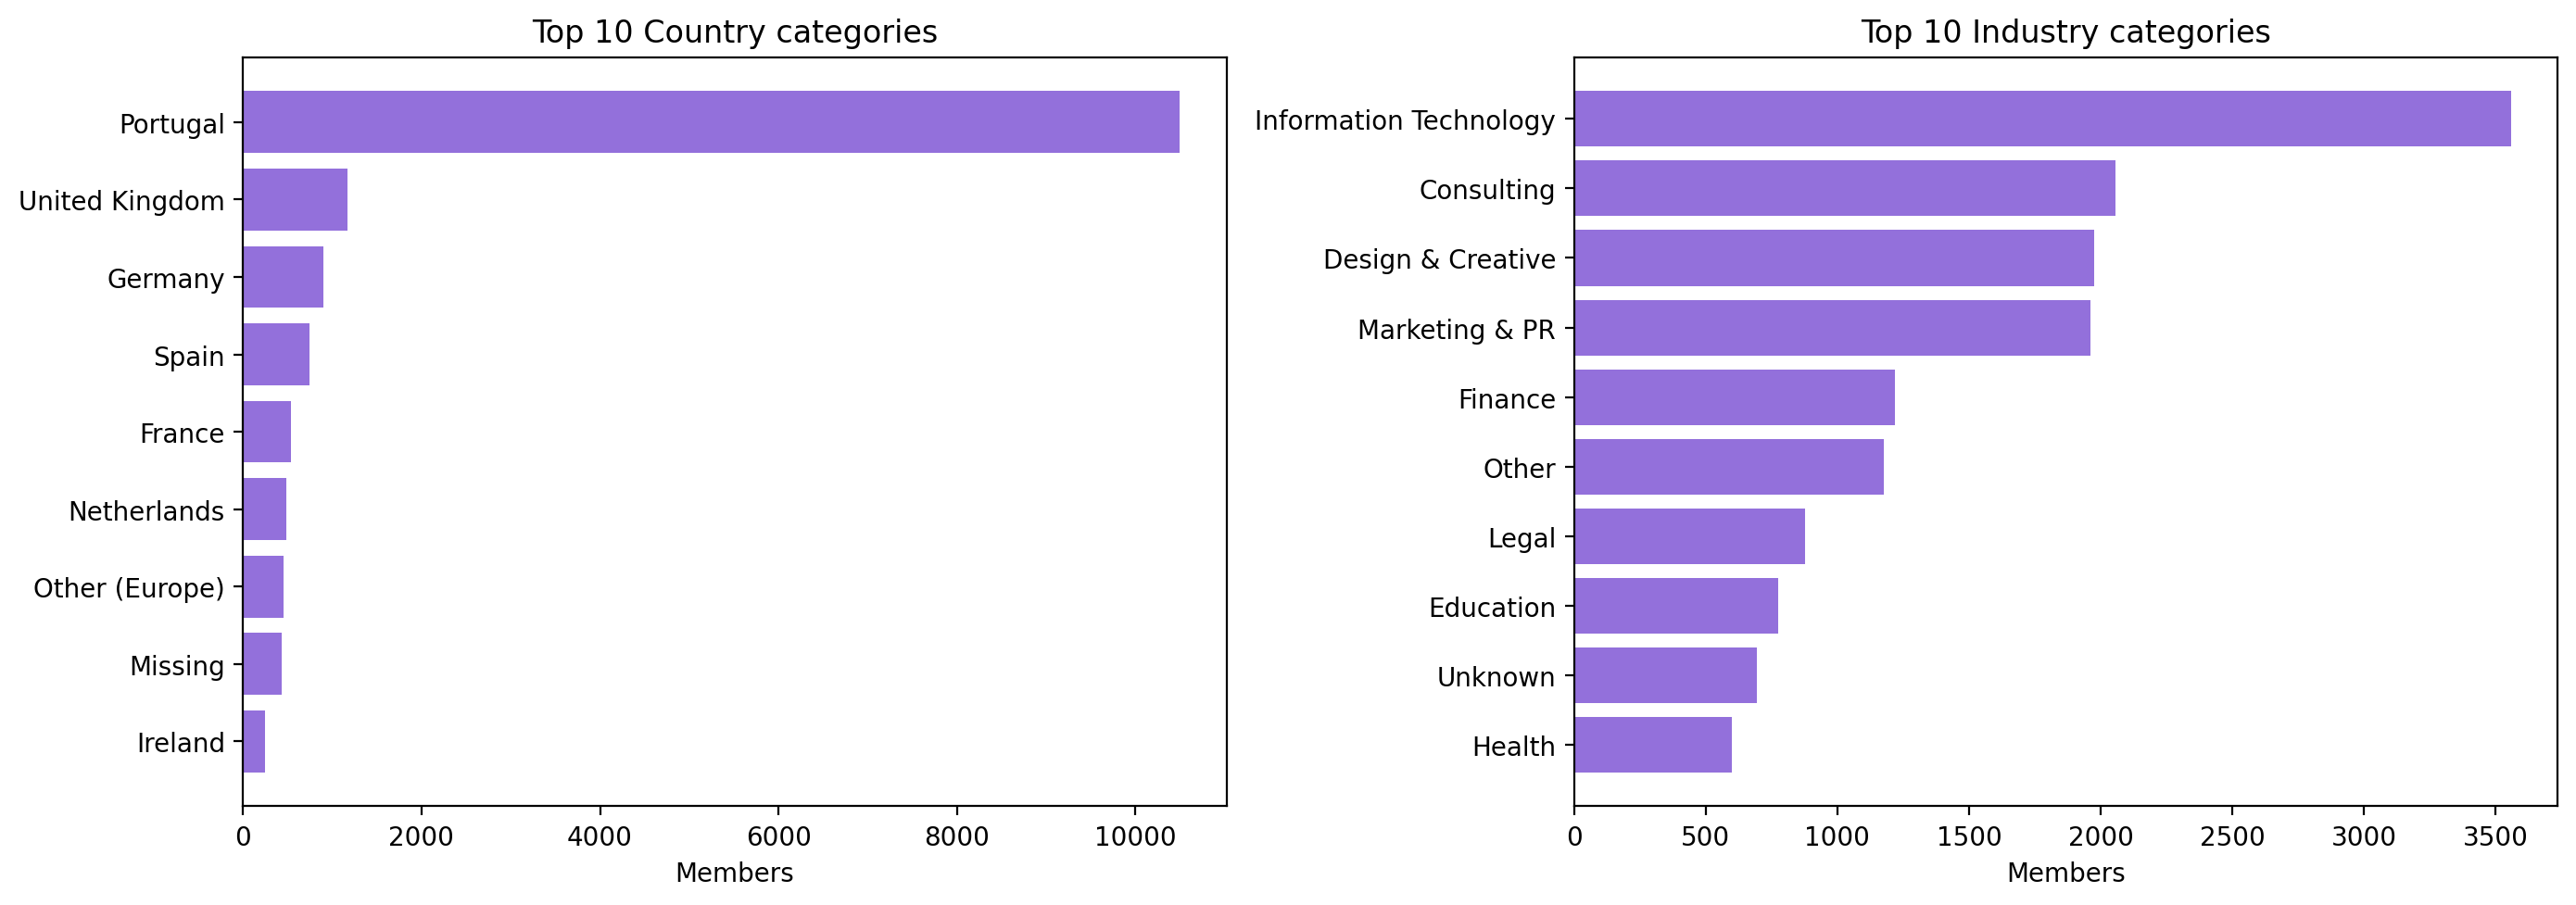

In [29]:
import re
import unicodedata

def category_key(value):
    if pd.isna(value):
        return None
    text = unicodedata.normalize("NFKD", str(value)).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z0-9]+", " ", text.casefold()).strip()

country_aliases = {
    "portugal": "Portugal", "portucal": "Portugal", "pt": "Portugal",
    "united kingdom": "United Kingdom", "uk": "United Kingdom", "u k": "United Kingdom", "gb": "United Kingdom",
    "germany": "Germany", "deutschland": "Germany", "de": "Germany",
    "netherlands": "Netherlands", "the netherlands": "Netherlands", "holland": "Netherlands", "nl": "Netherlands",
    "spain": "Spain", "espana": "Spain", "espa a": "Spain", "es": "Spain",
    "france": "France", "fr": "France", "ireland": "Ireland", "ie": "Ireland",
    "other europe": "Other (Europe)",
}
industry_aliases = {
    "information technology": "Information Technology", "it": "Information Technology", "tech": "Information Technology",
    "design creative": "Design & Creative", "design and creative": "Design & Creative",
    "consulting": "Consulting", "finance": "Finance", "marketing pr": "Marketing & PR",
    "marketing and pr": "Marketing & PR", "legal": "Legal", "education": "Education", "health": "Health",
    "real estate": "Real Estate", "realestate": "Real Estate", "other": "Other", "unknown": "Unknown",
}
for source_col, output_col, aliases in [
    ("country", "country_clean", country_aliases),
    ("industry", "industry_clean", industry_aliases),
]:
    keys = cluster_eda[source_col].map(category_key)
    cluster_eda[output_col] = keys.map(aliases).fillna(keys.str.title()).fillna("Missing")
    counts = cluster_eda[output_col].value_counts(dropna=False).head(12)
    print(f"\n{source_col} (top categories after clear alias mapping):")
    display(counts.rename("members").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, column, title in zip(axes, ["country_clean", "industry_clean"], ["Country", "Industry"]):
    counts = cluster_eda[column].value_counts().head(10).sort_values()
    ax.barh(counts.index, counts.values, color="mediumpurple")
    ax.set(title=f"Top 10 {title} categories", xlabel="Members", ylabel="")
plt.tight_layout()
plt.show()


In [30]:
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]
raw_dates = cluster_eda[date_cols].astype("string").apply(lambda column: column.str.strip())
parsed_dates = pd.DataFrame(index=cluster_eda.index)
date_parse_audit = []
for column in date_cols:
    raw = raw_dates[column]
    iso_mask = raw.str.fullmatch(r"\d{4}-\d{2}-\d{2}", na=False)
    slash_mask = raw.str.fullmatch(r"\d{1,2}/\d{1,2}/\d{4}", na=False)
    parsed = pd.Series(pd.NaT, index=raw.index, dtype="datetime64[ns]")
    parsed.loc[iso_mask] = pd.to_datetime(raw.loc[iso_mask], format="%Y-%m-%d", errors="coerce")
    parsed.loc[slash_mask] = pd.to_datetime(raw.loc[slash_mask], format="%d/%m/%Y", errors="coerce")
    parsed_dates[column] = parsed
    date_parse_audit.append({
        "column": column,
        "ISO YYYY-MM-DD": int(iso_mask.sum()),
        "day-first DD/MM/YYYY": int(slash_mask.sum()),
        "missing or unsupported": int((raw.isna() | ~(iso_mask | slash_mask)).sum()),
        "invalid calendar dates": int((iso_mask | slash_mask).sum() - parsed.notna().sum()),
    })

# Keep raw source columns intact; add consistently formatted ISO-string columns for use downstream.
for column in date_cols:
    cluster_eda[f"{column}_iso"] = parsed_dates[column].dt.strftime("%Y-%m-%d")
display(pd.DataFrame(date_parse_audit).set_index("column"))
print("Normalized date examples:")
display(cluster_eda[[f"{column}_iso" for column in date_cols]].head())
date_summary = pd.DataFrame({
    "parsed_values": parsed_dates.notna().sum(),
    "missing_or_unparsed": parsed_dates.isna().sum(),
    "earliest": parsed_dates.min(),
    "latest": parsed_dates.max(),
})
display(date_summary)
start_end_both = parsed_dates["membership_start"].notna() & parsed_dates["membership_end"].notna()
print("Records with end date before start date:", int((parsed_dates.loc[start_end_both, "membership_end"] < parsed_dates.loc[start_end_both, "membership_start"]).sum()))


,ISO YYYY-MM-DD,day-first DD/MM/YYYY,missing or unsupported,invalid calendar dates
column,,,,
membership_start,14813,637,0,0
membership_end,14989,461,0,0
last_badge_swipe,14813,637,0,0


Normalized date examples:


,membership_start_iso,membership_end_iso,last_badge_swipe_iso
0,2021-08-01,2023-03-06,2023-03-23
1,2023-11-24,1970-01-01,2023-11-24
2,2021-12-03,1970-01-01,2023-07-22
3,2022-01-02,2022-02-15,2022-01-02
4,2023-10-24,1970-01-01,2023-12-17


,parsed_values,missing_or_unparsed,earliest,latest
membership_start,15450,0,2021-01-01,2023-12-30
membership_end,15450,0,1970-01-01,2024-01-01
last_badge_swipe,15450,0,2020-09-06,2024-04-28


Records with end date before start date: 4106


### Do renewals vary with member engagement?

`n_renewals` is a potentially useful measure of membership history, but it is not by itself a direct measure of loyalty or future retention. Members who have been members longer have had more opportunities to renew, so interpret it alongside membership dates and tenure where the observation period is known. Negative renewal counts are invalid for this comparison and are excluded, not recoded. The summaries below compare renewal history with average weekly visits and visit utilization; they show association, not that visits cause renewals. Industry is used to profile the pattern after standardizing category labels, not to define behavior groups.

Records with negative renewals excluded: 66
Renewal-count distribution (valid non-negative values):


,members
n_renewals,
0,7742
1,3289
2,2194
3,1176
4,586
5,248
6,149


,members,median_weekly_visits,median_visit_utilization
renewal_band,,,
0,7742,0.99,0.397
1,3289,1.96,0.713
2+,4353,2.02,0.690


,Spearman correlation with n_renewals
avg_weekly_visits,0.263
visit_utilization,0.142


Industry profile (groups with at least 30 valid records):


,members,median_renewals,zero_renewal_pct,median_weekly_visits
industry_clean,,,,
Information Technology,3544,1.0,48.31,1.81
Consulting,2048,1.0,41.60,1.44
Design & Creative,1968,0.0,56.35,1.83
Marketing & PR,1950,0.0,53.44,1.28
Finance,1216,1.0,37.34,1.18
Other,1165,0.0,63.78,1.11
Legal,873,1.0,42.38,1.20
Education,772,0.0,60.49,1.11
Unknown,690,0.0,52.75,1.30


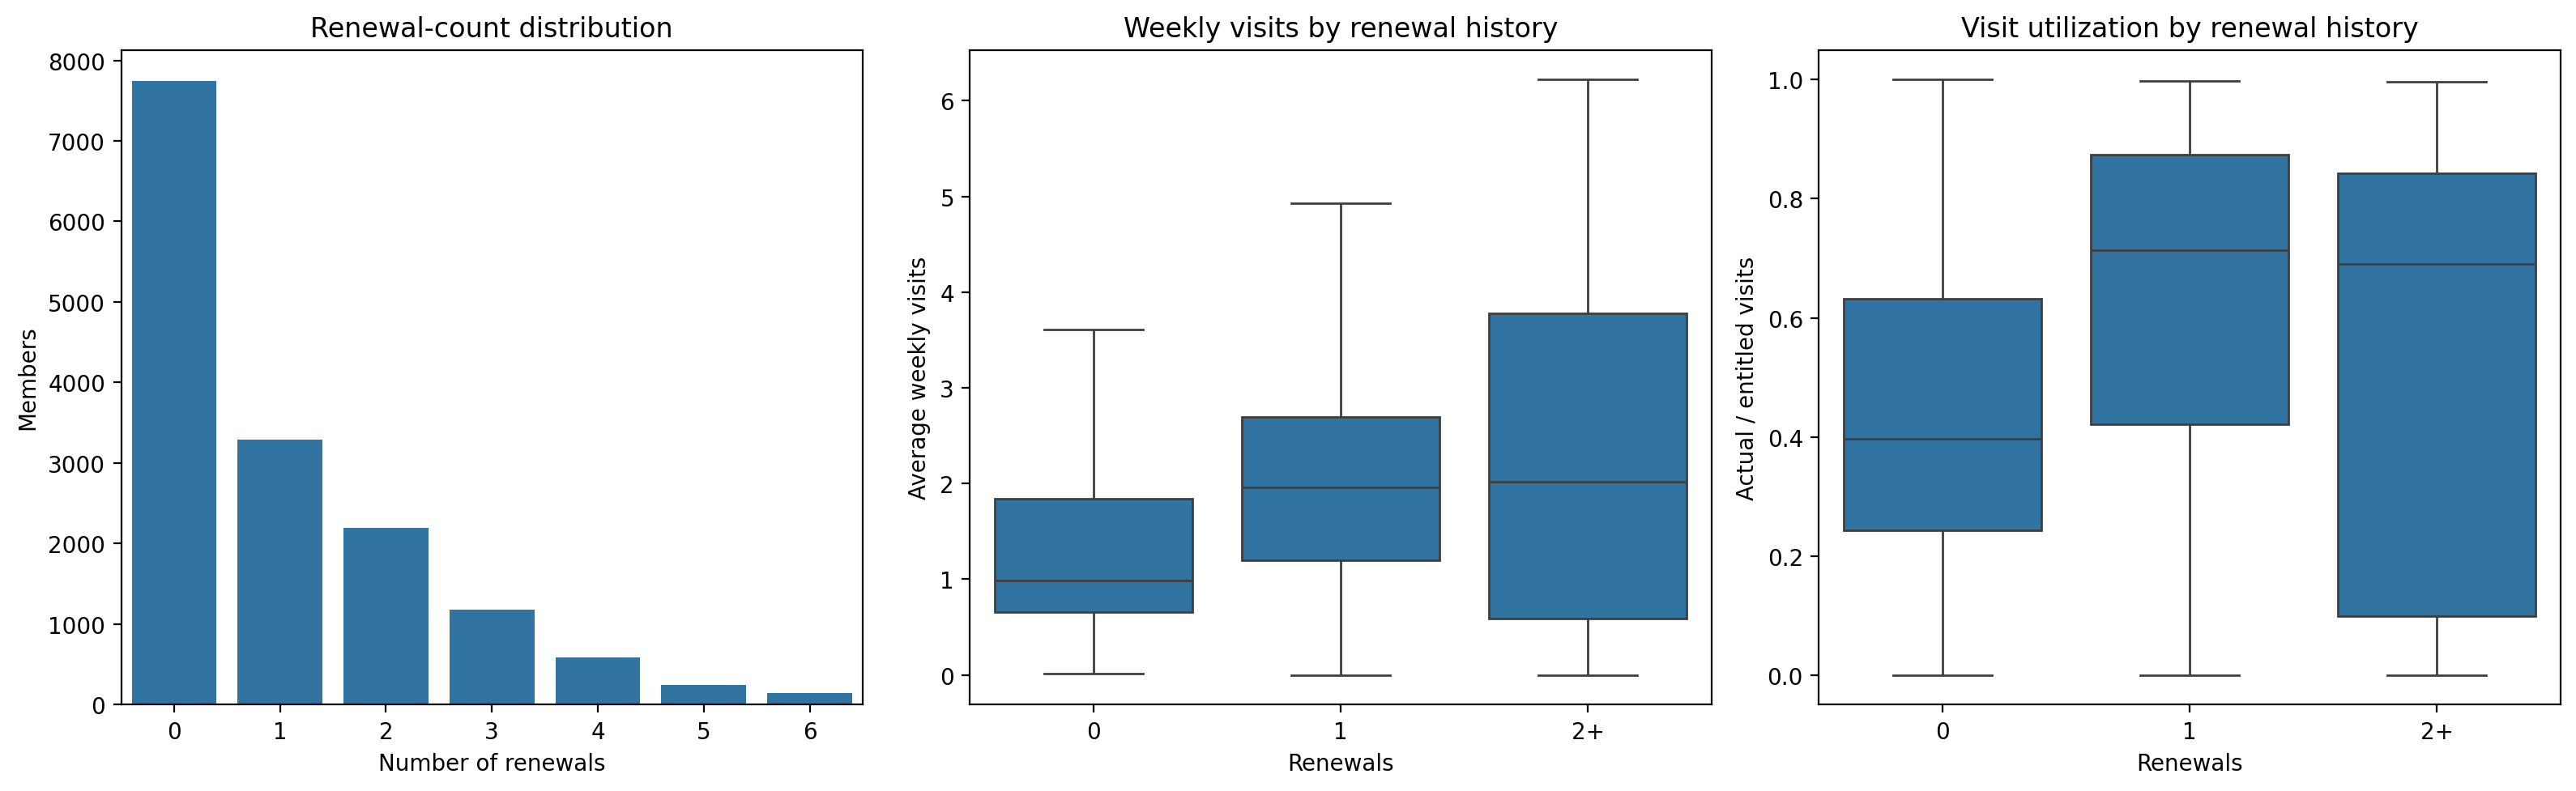

In [31]:
renewal_analysis = cluster_eda.loc[cluster_eda["n_renewals"].ge(0)].copy()
renewal_analysis["visit_utilization"] = (
    renewal_analysis["actual_visits_last_period"] /
    renewal_analysis["entitled_visits_last_period"].replace(0, np.nan)
)
renewal_analysis["renewal_band"] = pd.cut(
    renewal_analysis["n_renewals"],
    bins=[-0.5, 0.5, 1.5, np.inf],
    labels=["0", "1", "2+"],
)

print(f"Records with negative renewals excluded: {(cluster_eda['n_renewals'] < 0).sum():,}")
print("Renewal-count distribution (valid non-negative values):")
display(renewal_analysis["n_renewals"].value_counts().sort_index().rename("members").to_frame())

renewal_group_summary = (
    renewal_analysis.groupby("renewal_band", observed=False)
    .agg(
        members=("member_id", "size"),
        median_weekly_visits=("avg_weekly_visits", "median"),
        median_visit_utilization=("visit_utilization", "median"),
    )
)
display(renewal_group_summary.round(3))

spearman_renewal = pd.Series({
    column: renewal_analysis[["n_renewals", column]].corr(method="spearman").iloc[0, 1]
    for column in ["avg_weekly_visits", "visit_utilization"]
}, name="Spearman correlation with n_renewals").to_frame()
display(spearman_renewal.round(3))

industry_renewal_summary = (
    renewal_analysis.groupby("industry_clean", dropna=False)
    .agg(
        members=("member_id", "size"),
        median_renewals=("n_renewals", "median"),
        zero_renewal_pct=("n_renewals", lambda values: 100 * values.eq(0).mean()),
        median_weekly_visits=("avg_weekly_visits", "median"),
    )
    .query("members >= 30")
    .sort_values("members", ascending=False)
)
print("Industry profile (groups with at least 30 valid records):")
display(industry_renewal_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.countplot(data=renewal_analysis, x="n_renewals", order=sorted(renewal_analysis["n_renewals"].unique()), ax=axes[0])
axes[0].set(title="Renewal-count distribution", xlabel="Number of renewals", ylabel="Members")
sns.boxplot(data=renewal_analysis, x="renewal_band", y="avg_weekly_visits", showfliers=False, ax=axes[1])
axes[1].set(title="Weekly visits by renewal history", xlabel="Renewals", ylabel="Average weekly visits")
sns.boxplot(data=renewal_analysis, x="renewal_band", y="visit_utilization", showfliers=False, ax=axes[2])
axes[2].set(title="Visit utilization by renewal history", xlabel="Renewals", ylabel="Actual / entitled visits")
plt.tight_layout()
plt.show()

**Preliminary interpretation:** After excluding the 66 negative renewal records, members with one or more renewals have higher median weekly visits and visit utilization than members with no renewals. In the 0 / 1 / 2+ comparison, median weekly visits are approximately 0.99 / 1.96 / 2.02 and median utilization is approximately 40% / 71% / 69%. The rank-based associations are modest for weekly visits (Spearman about 0.26) and weak for utilization (about 0.14). This suggests an association worth following up, but not a simple steadily increasing pattern or evidence that visits cause renewal. Check tenure, membership-date quality, and group sizes before drawing conclusions; use renewals to profile clusters unless the clustering goal explicitly includes membership history.

### Are renewals associated with membership tenure?

Compare renewal counts with completed membership duration, calculated as membership end minus membership start. The `1970-01-01` end date is used as an active-membership sentinel in this project, so exclude those rows rather than treating them as real end dates. This analysis therefore describes members with valid, non-sentinel end dates only; it cannot establish tenure for active members without a known observation date. Negative renewals, unparseable dates, and end dates before start dates are also excluded. A positive association is expected in part because longer memberships provide more opportunities to renew; it is not evidence that tenure causes renewal.

Valid ended memberships included: 11,293
Active sentinel end dates excluded: 3,954
Other invalid/missing date records excluded: 152
Negative renewal records excluded: 66
Spearman correlation between renewals and completed tenure: 0.637 (n=11,293)


,members,median_tenure_years
renewal_band,,
0,6470,0.20
1,2353,1.19
2+,2470,1.58


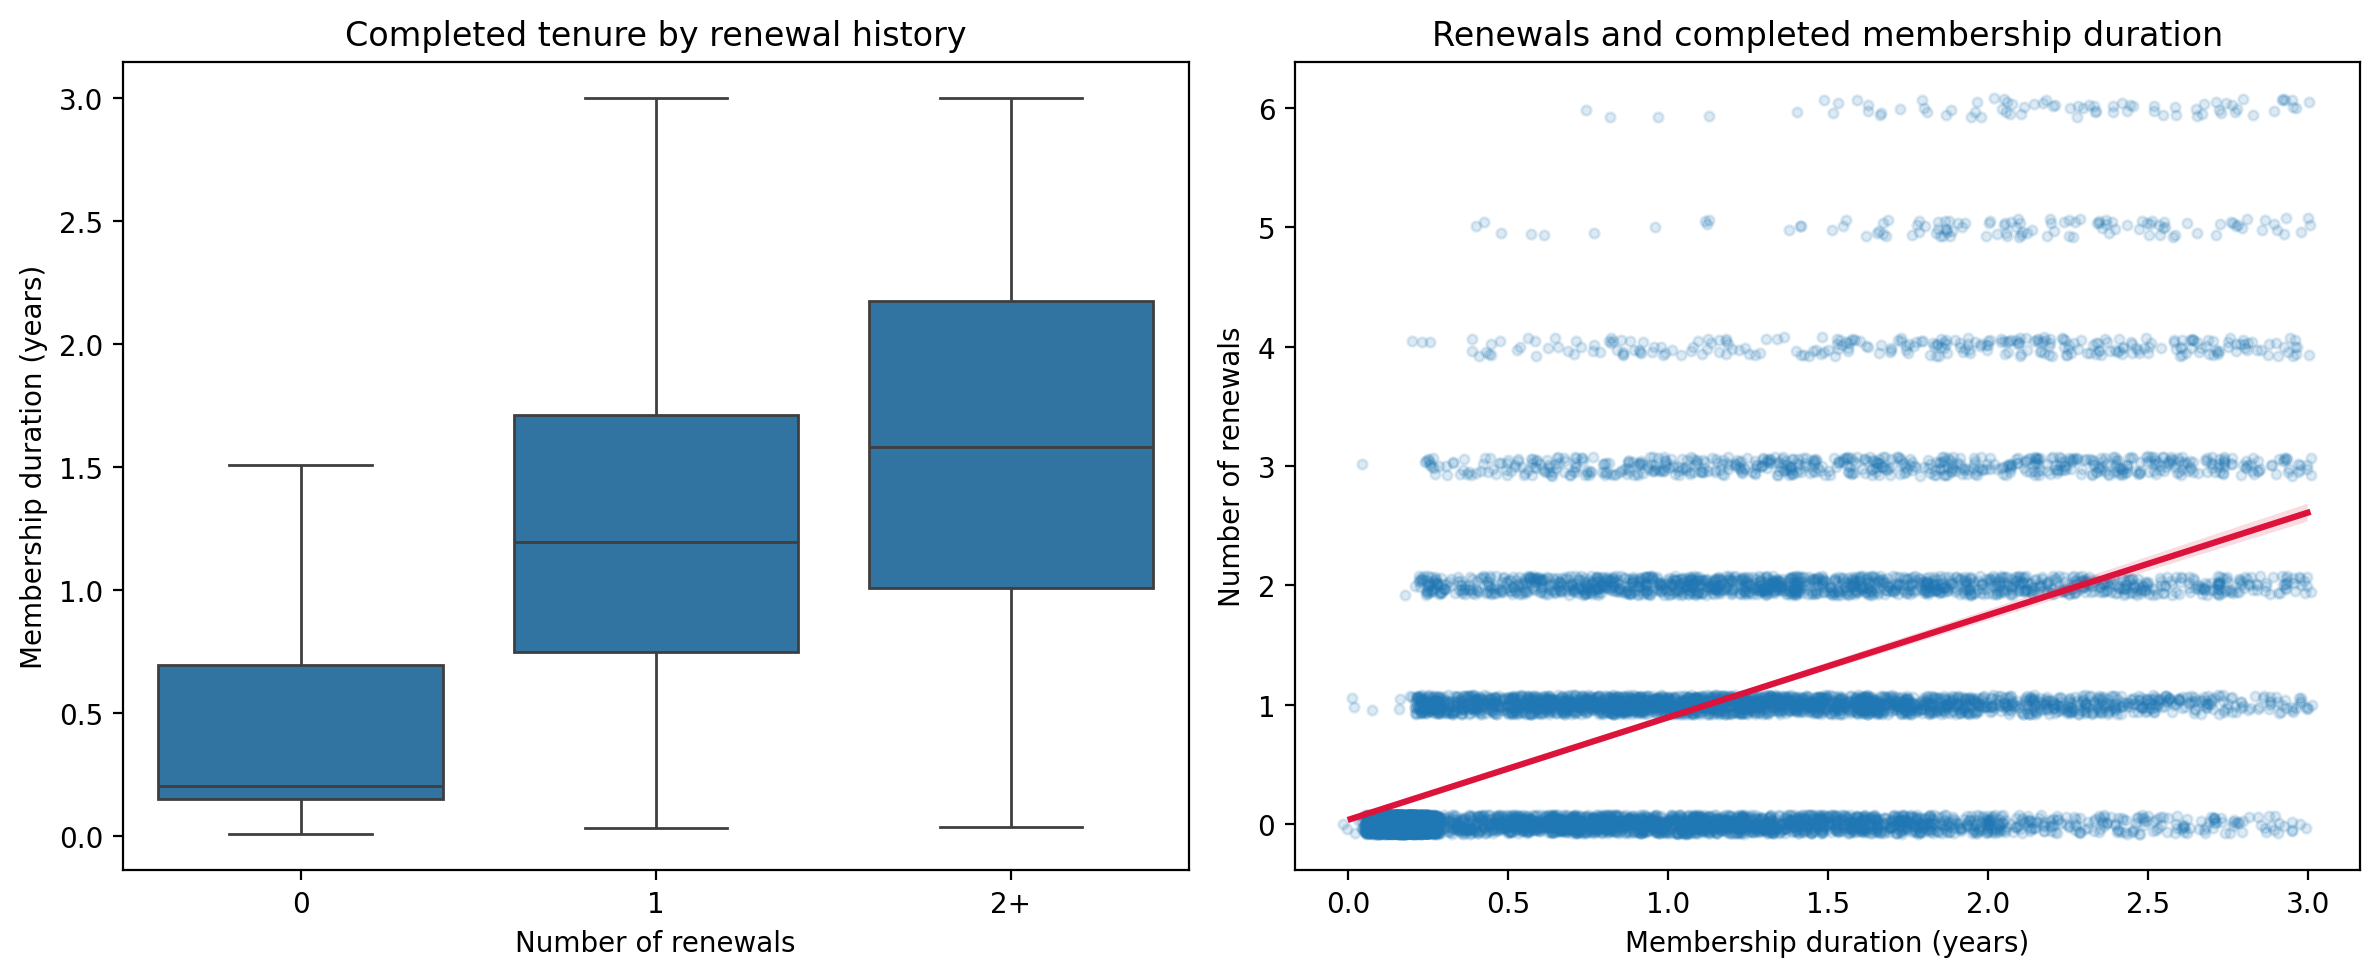

In [32]:
active_end_sentinel = pd.Timestamp("1970-01-01")
valid_membership_dates = (
    parsed_dates["membership_start"].notna()
    & parsed_dates["membership_end"].notna()
    & parsed_dates["membership_end"].ne(active_end_sentinel)
    & parsed_dates["membership_end"].ge(parsed_dates["membership_start"])
)
valid_renewal_counts = cluster_eda["n_renewals"].ge(0)
tenure_mask = valid_membership_dates & valid_renewal_counts
renewal_tenure = cluster_eda.loc[tenure_mask, ["member_id", "n_renewals"]].copy()
renewal_tenure["membership_tenure_days"] = (
    parsed_dates.loc[tenure_mask, "membership_end"]
    - parsed_dates.loc[tenure_mask, "membership_start"]
).dt.days
renewal_tenure["membership_tenure_years"] = renewal_tenure["membership_tenure_days"] / 365.25

print(f"Valid ended memberships included: {len(renewal_tenure):,}")
print(f"Active sentinel end dates excluded: {int(parsed_dates['membership_end'].eq(active_end_sentinel).sum()):,}")
print(f"Other invalid/missing date records excluded: {int((~valid_membership_dates & ~parsed_dates['membership_end'].eq(active_end_sentinel)).sum()):,}")
print(f"Negative renewal records excluded: {int((cluster_eda['n_renewals'] < 0).sum()):,}")

renewal_tenure_rho = renewal_tenure["n_renewals"].corr(
    renewal_tenure["membership_tenure_days"], method="spearman"
)
print(f"Spearman correlation between renewals and completed tenure: {renewal_tenure_rho:.3f} (n={len(renewal_tenure):,})")

# Use the same 0 / 1 / 2+ bands as the engagement comparison.
renewal_tenure["renewal_band"] = pd.cut(
    renewal_tenure["n_renewals"],
    bins=[-0.5, 0.5, 1.5, np.inf],
    labels=["0", "1", "2+"],
)
tenure_by_renewal_band = (
    renewal_tenure.groupby("renewal_band", observed=False)
    .agg(
        members=("member_id", "size"),
        median_tenure_years=("membership_tenure_years", "median"),
    )
)
display(tenure_by_renewal_band.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=renewal_tenure, x="renewal_band", y="membership_tenure_years", showfliers=False, ax=axes[0])
axes[0].set(title="Completed tenure by renewal history", xlabel="Number of renewals", ylabel="Membership duration (years)")
sns.regplot(data=renewal_tenure, x="membership_tenure_years", y="n_renewals",
            x_jitter=0.04, y_jitter=0.08, scatter_kws={"alpha": 0.15, "s": 12},
            line_kws={"color": "crimson"}, ax=axes[1])
axes[1].set(title="Renewals and completed membership duration", xlabel="Membership duration (years)", ylabel="Number of renewals")
plt.tight_layout()
plt.show()

**Preliminary interpretation:** In the valid ended-member records, renewal count has a positive Spearman association with completed membership duration (about 0.64). Median completed tenure also rises across the 0 / 1 / 2+ renewal bands (about 0.20 / 1.19 / 1.58 years). This is a substantial descriptive relationship, but it is partly expected by construction: a longer membership gives more opportunities to renew. The result applies only to members with valid end dates, not active members, and should not be interpreted as evidence that longer tenure causes renewal.

### Do service-use patterns differ by industry?

Compare the share of members using each optional service across the cleaned industry categories. This shows whether service mixes differ descriptively by industry; it does not show that industry causes a service preference. Only industries with at least 30 records are shown to reduce the influence of very small groups. Because service indicators are yes/no flags, the group mean is the proportion using that service. Review small differences cautiously, especially when some categories remain sparse.

,members,meeting rooms,event space,guest passes,print,mail handling,phone booths,day passes,storage,bike locker
industry_clean,,,,,,,,,,
Information Technology,3557,32.9,10.8,16.5,33.7,24.4,27.1,20.6,16.5,0.2
Consulting,2055,38.5,13.2,20.0,35.5,30.7,28.6,21.4,19.3,0.0
Design & Creative,1974,28.8,12.1,15.9,33.2,13.0,22.8,24.1,8.1,0.3
Marketing & PR,1962,38.8,15.4,22.4,30.9,18.3,24.6,24.3,11.8,0.1
Finance,1219,37.1,11.1,20.9,33.9,36.1,28.2,18.3,22.6,0.1
Other,1175,28.1,11.0,17.1,27.0,16.4,21.4,24.6,11.7,0.2
Legal,878,35.3,10.9,18.2,36.9,30.8,28.1,20.0,20.6,0.0
Education,775,30.7,10.1,14.7,24.6,15.6,25.4,24.3,9.4,0.0
Unknown,693,31.5,9.8,18.6,30.3,23.7,24.8,23.2,11.7,1.0


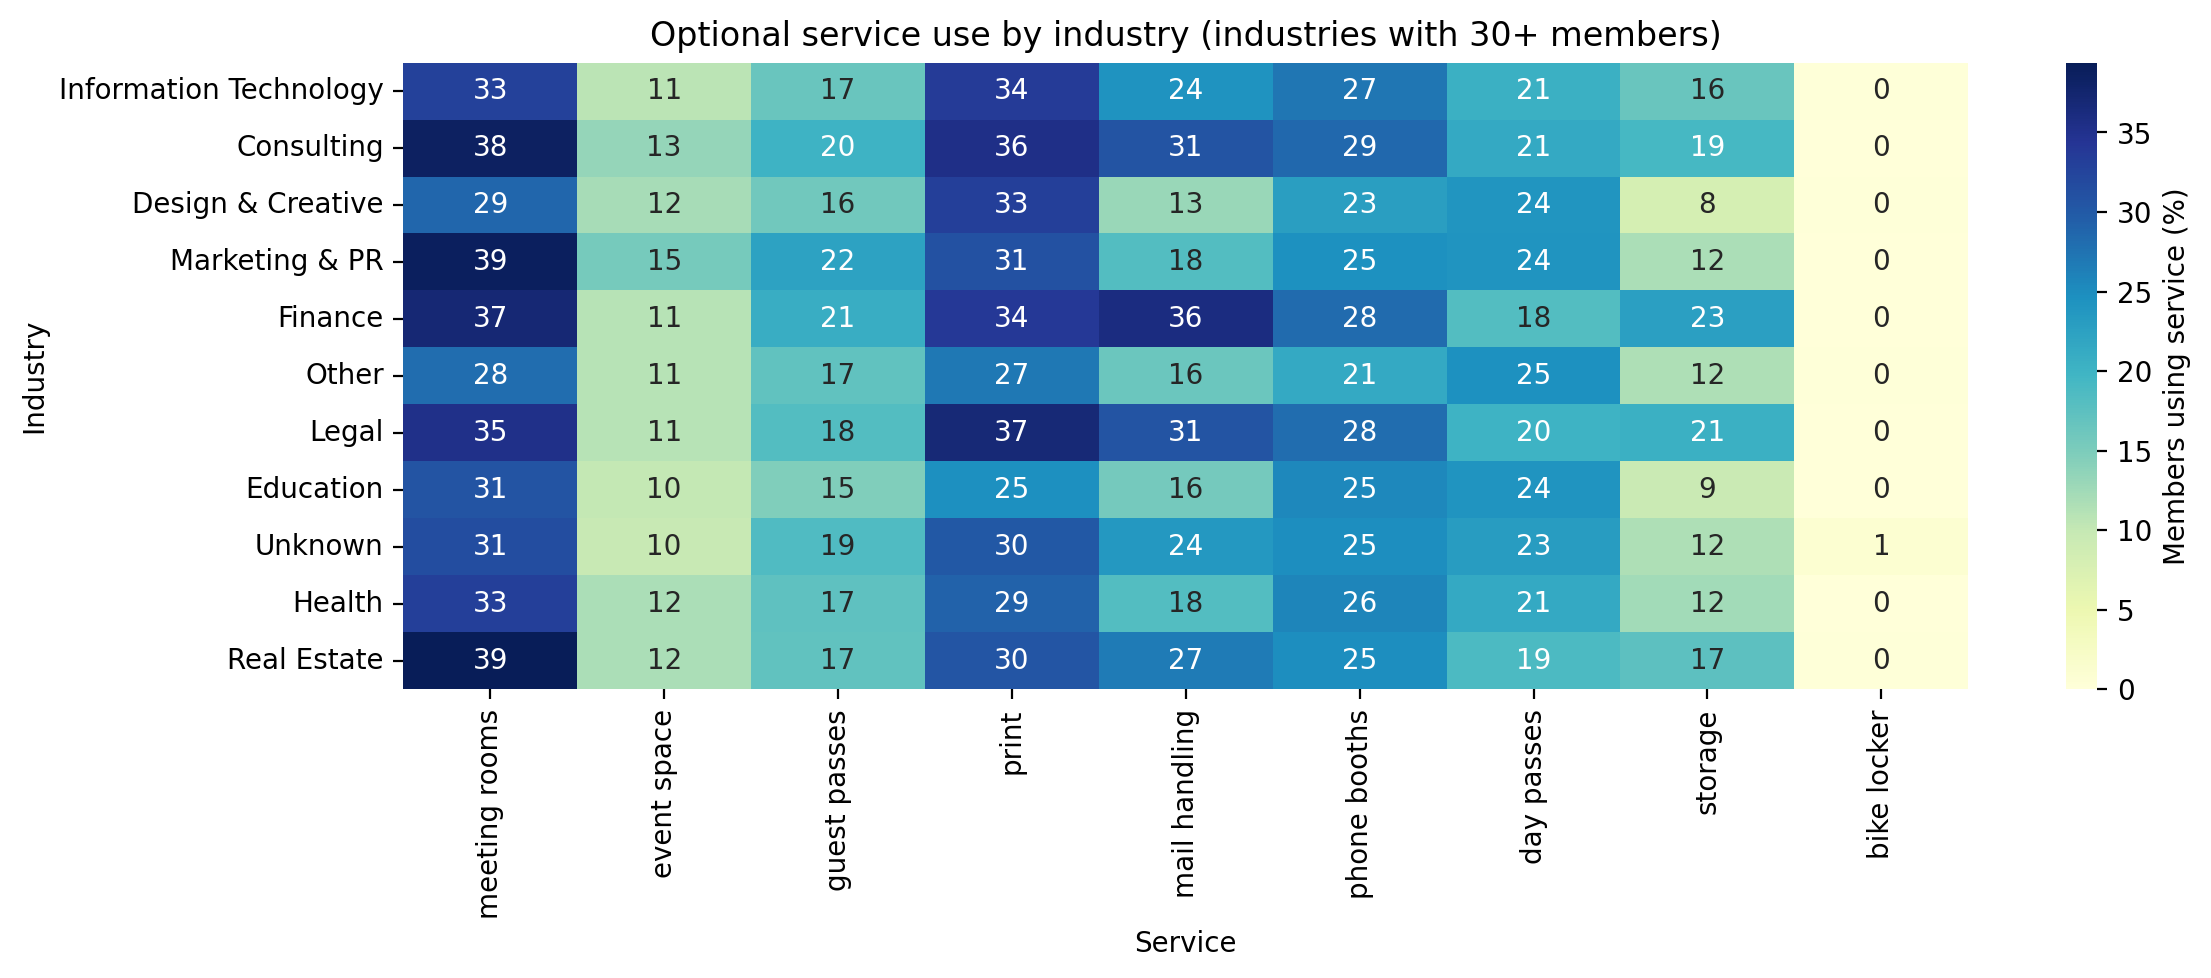

In [33]:
service_cols = [
    "uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print",
    "uses_mail_handling", "uses_phone_booths", "uses_day_passes", "uses_storage",
    "uses_bike_locker",
]
industry_service_data = cluster_eda[["industry_clean", *service_cols]].copy()
industry_service_data[service_cols] = industry_service_data[service_cols].astype(float)
industry_service_counts = industry_service_data.groupby("industry_clean", dropna=False).size()
eligible_industries = industry_service_counts[industry_service_counts >= 30].index
industry_service_data = industry_service_data.loc[
    industry_service_data["industry_clean"].isin(eligible_industries)
]
industry_service_rates = (
    industry_service_data.groupby("industry_clean", dropna=False)[service_cols]
    .mean()
    .mul(100)
)
industry_service_rates.columns = [column.removeprefix("uses_").replace("_", " ") for column in service_cols]
industry_service_rates.insert(
    0, "members", industry_service_data.groupby("industry_clean", dropna=False).size()
)
industry_service_rates = industry_service_rates.sort_values("members", ascending=False)
display(industry_service_rates.round(1))

heatmap_data = industry_service_rates.drop(columns="members")
plt.figure(figsize=(12, max(5, 0.38 * len(heatmap_data))))
sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "Members using service (%)"})
plt.title("Optional service use by industry (industries with 30+ members)")
plt.xlabel("Service")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

### Candidate feature overlap and selection

A clustering algorithm sees distances, not business meaning. If several inputs all measure attendance, that dimension can dominate. Compare the candidate numerical features after excluding negative values that require validation. This is a screening step: low Spearman correlation does not prove independence, and high correlation does not by itself dictate which variable to remove.

,avg_weekly_visits,actual_visits_last_period,days_since_last_visit,visit_utilization,plan_days_per_week,meeting_room_hours,event_space_hours,guest_passes_issued,n_renewals
avg_weekly_visits,1.00,0.93,-0.66,0.84,0.27,0.30,0.07,0.15,0.26
actual_visits_last_period,0.93,1.00,-0.62,0.84,0.25,0.32,0.08,0.18,0.27
days_since_last_visit,-0.66,-0.62,1.00,-0.65,-0.03,-0.26,-0.11,-0.14,-0.22
visit_utilization,0.84,0.84,-0.65,1.00,-0.14,0.16,0.01,0.07,0.14
plan_days_per_week,0.27,0.25,-0.03,-0.14,1.00,0.21,0.04,0.12,0.45
meeting_room_hours,0.30,0.32,-0.26,0.16,0.21,1.00,0.32,0.34,0.22
event_space_hours,0.07,0.08,-0.11,0.01,0.04,0.32,1.00,0.25,0.08
guest_passes_issued,0.15,0.18,-0.14,0.07,0.12,0.34,0.25,1.00,0.13
n_renewals,0.26,0.27,-0.22,0.14,0.45,0.22,0.08,0.13,1.00


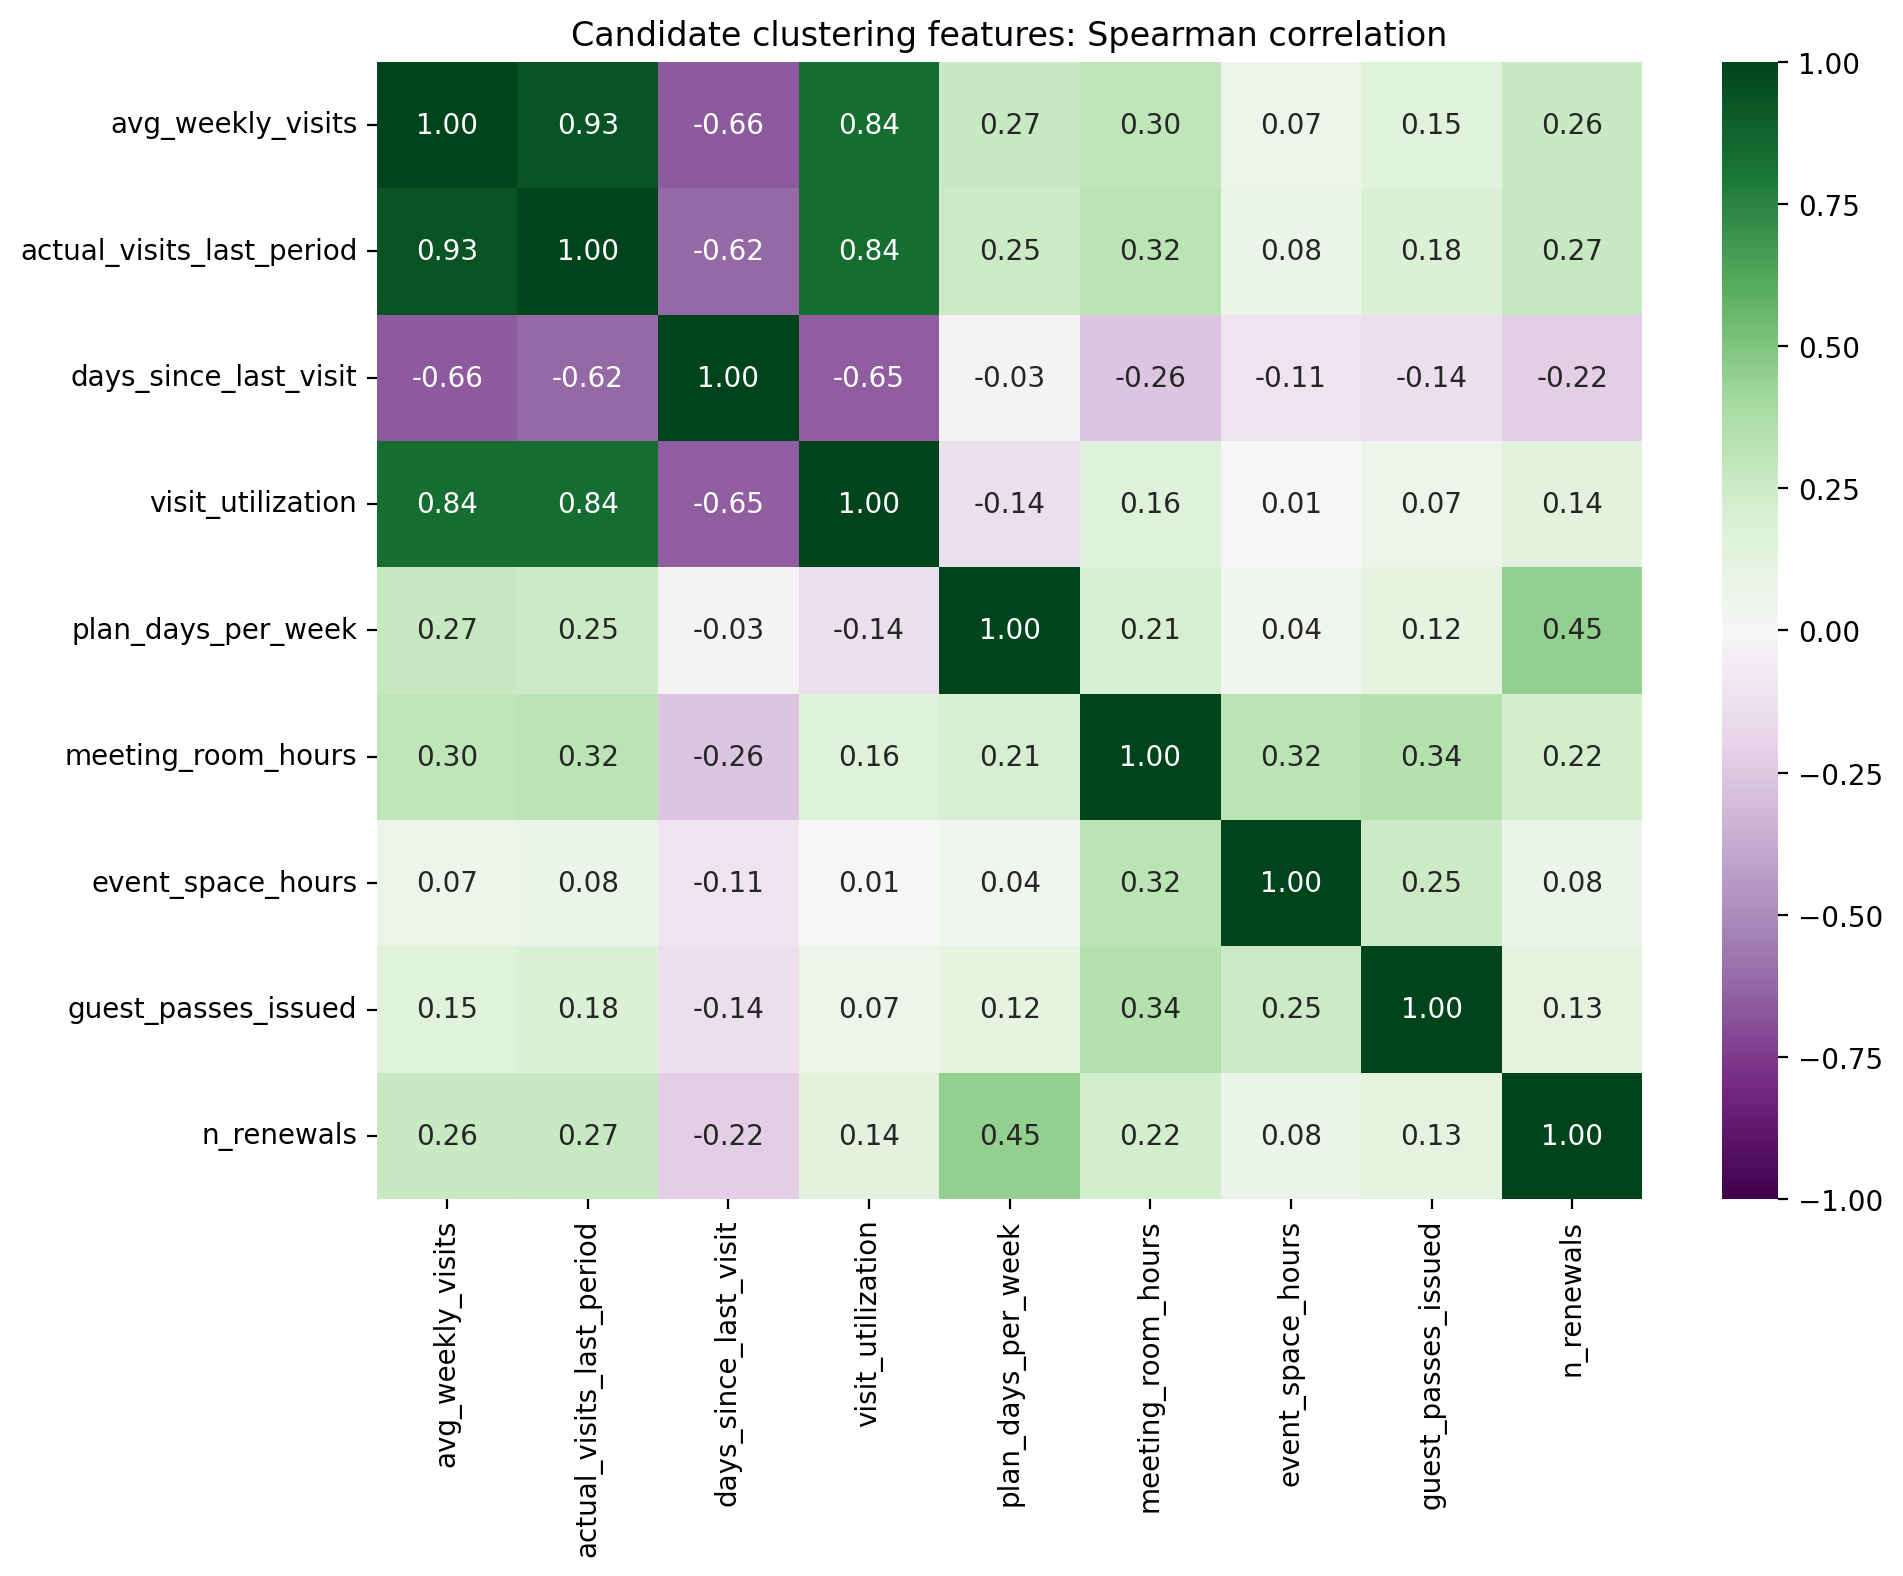

In [34]:
candidate_numeric = [
    "avg_weekly_visits", "actual_visits_last_period", "days_since_last_visit",
    "visit_utilization", "plan_days_per_week", "meeting_room_hours",
    "event_space_hours", "guest_passes_issued", "n_renewals",
]
feature_frame = cluster_eda[candidate_numeric].copy()
for column in ["days_since_last_visit", "meeting_room_hours", "event_space_hours",
               "guest_passes_issued", "n_renewals"]:
    feature_frame.loc[feature_frame[column] < 0, column] = np.nan
feature_corr = feature_frame.corr(method="spearman", min_periods=100).round(2)
display(feature_corr)

plt.figure(figsize=(10, 8))
sns.heatmap(feature_corr, annot=True, fmt=".2f", cmap="PRGn", center=0, vmin=-1, vmax=1)
plt.title("Candidate clustering features: Spearman correlation")
plt.tight_layout()
plt.show()


### What this suggests for the clustering stage

**Candidate behavioral inputs to test**

- Engagement: average weekly visits and/or days since last visit. Recent-period visits are highly related to weekly visits, so test whether both are needed rather than automatically including all attendance measures.
- Plan-relative engagement: visit utilization, alongside plan allowance/tier for interpretation. Utilization is undefined when entitled visits are zero; keep that distinct from zero utilization.
- Service needs: selected individual service indicators and/or service count. A count is compact, while individual indicators preserve which services are used; compare their contribution and avoid giving redundant representations excessive weight.
- Collaboration: team-account status, colleagues, and meeting/guest behavior only if the record-level definition makes them comparable and quality checks pass.

**Usually profile after clustering rather than use as initial behavioral inputs:** age, gender, country, and industry. Plan tier may be an input if the goal includes membership choice, or a profiling variable if the goal is to cluster usage behavior regardless of plan. Renewals, total visits, and lifetime value need a tenure check; lifetime value may also be better used to describe clusters than define them.

Before fitting, resolve exact duplicates and conflicting IDs, standardize category labels, investigate invalid values, decide a missing-value strategy, transform strongly skewed variables where appropriate, and scale numerical inputs. Run sensitivity checks so cluster profiles are not artifacts of these decisions.


## Preliminary findings for the business

These are EDA observations and **testable hypotheses**, not discovered clusters.

1. **Most useful early signal:** members differ in attendance and recency. After exact duplicate removal, weekly visits and actual visits in the last period remain strongly associated (Spearman ? ? 0.93); weekly visits and days since last visit are inversely associated (? ? ?0.66) among non-negative recency records. These measures describe a plausible engagement dimension, but the attendance variables overlap.
2. **Potentially useful additional dimensions:** members differ in how much of their visit allowance they use and in which optional services they use. Plan tier and the individual service comparisons above help establish whether these are distinct from simple attendance.
3. **Largest reliability risks:** invalid negative values, extreme values, missing usage fields, inconsistent category labels, and duplicate records. These can distort distance calculations and manufacture apparent groups. Validate against source definitions, document decisions, and compare results under reasonable cleaning alternatives.
4. **Working segment hypothesis:** test whether a small number of interpretable behavior profiles emerge, for example frequent/high-utilization members, low-activity or less-recent members, and members whose service mix is broader or collaboration-oriented. These profiles may overlap and should not be presented as findings until a clustering model supports them.
5. **Number of groups:** as a starting experiment, evaluate several candidate cluster counts (for example, k=2 through k=6). A business-facing working hypothesis is roughly **3-4** profiles, but the final choice must be based on stability, separation, useful profile differences, and stakeholder interpretability?not EDA alone or one score.

**Plain-language version:** ?We are checking whether members differ in how often they visit, how fully they use their plans, and which services they use. Early patterns suggest attendance is an important dimension, while service mix and plan-relative use may add context. We will test a few possible groupings and validate that they are stable and understandable before recommending actions. Data-quality problems and overlapping attendance measures are the main challenges.?

For the final clustering report, show each cluster's size and a small number of distinctive behavioral measures, describe it in plain language, and state uncertainty and data limitations. Use demographics to check and describe the resulting groups carefully, not to imply that demographic attributes explain behavior.
